# Few-Shot Learning for Bird Species Classification — Results Notebook

**Thesis:** Evaluation of Few-Shot Learning Paradigms for Bird Species Classification
**Dataset:** 20 bird species (15 base / 5 novel), ResNet-50 backbone
**Evaluation:** 5-way 1-shot episodic protocol on novel classes (600 episodes)

---
This notebook presents and compares all experimental results in sequence:
1. Dataset overview
2. Supervised Baseline — Full-20
3. Supervised Baseline — Base-15
4. ProtoNet (Euclidean) — main FSL result
5. ProtoNet Distance Ablation (Euclidean vs Manhattan)
6. Matching Networks
7. Relation Networks
8. Cross-model comparison & insights


In [232]:
%matplotlib inline
import os, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams["figure.dpi"]      = 120
plt.rcParams["savefig.dpi"]     = 150
plt.rcParams["figure.facecolor"]  = "white"
plt.rcParams["axes.facecolor"]    = "white"
plt.rcParams["savefig.facecolor"] = "white"

NB_DIR = os.getcwd()
ROOT   = os.path.normpath(os.path.join(NB_DIR, '..'))
RES    = os.path.join(ROOT, 'results')
os.makedirs(RES, exist_ok=True)
ANALYSIS = os.path.join(RES, 'analysis')
os.makedirs(ANALYSIS, exist_ok=True)

print(f"ROOT : {ROOT}")
print(f"RES  : {RES}")
print(f"matplotlib backend: {matplotlib.get_backend()}")

PATHS = {
    # ── Baselines ──────────────────────────────────────────────────────────────
    'full20_json'          : f'{RES}/baseline/resnet50/full20/summary.json',
    'base15_json'          : f'{RES}/baseline/resnet50/base15/base_test/summary.json',
    # ── NCC (Nearest Centroid Classifier) — frozen base15 backbone ─────────────
    'ncc_1shot_euc_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/1shot_euclidean/summary.json',
    'ncc_1shot_man_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/1shot_manhattan/summary.json',
    'ncc_3shot_euc_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/3shot_euclidean/summary.json',
    'ncc_3shot_man_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/3shot_manhattan/summary.json',
    'ncc_5shot_euc_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/5shot_euclidean/summary.json',
    'ncc_5shot_man_json'   : f'{RES}/baseline/resnet50/base15/novel_ncc/5shot_manhattan/summary.json',
    # ── ProtoNet — all shots × distances ───────────────────────────────────────
    'proto_1shot_euc_json' : f'{RES}/proto_net/base15_novel5/1shot_euclidean/summary.json',
    'proto_1shot_man_json' : f'{RES}/proto_net/base15_novel5/1shot_manhattan/summary.json',
    'proto_3shot_euc_json' : f'{RES}/proto_net/base15_novel5/3shot_euclidean/summary.json',
    'proto_3shot_man_json' : f'{RES}/proto_net/base15_novel5/3shot_manhattan/summary.json',
    'proto_5shot_euc_json' : f'{RES}/proto_net/base15_novel5/5shot_euclidean/summary.json',
    'proto_5shot_man_json' : f'{RES}/proto_net/base15_novel5/5shot_manhattan/summary.json',
    # ── MatchingNet — all shots ────────────────────────────────────────────────
    'match_1shot_json'     : f'{RES}/matching_net/base15_novel5/1shot/summary.json',
    'match_3shot_json'     : f'{RES}/matching_net/base15_novel5/3shot/summary.json',
    'match_5shot_json'     : f'{RES}/matching_net/base15_novel5/5shot/summary.json',
    # ── RelationNet — all shots ───────────────────────────────────────────────
    'rel_1shot_json'       : f'{RES}/relation_net/base15_novel5/1shot/summary.json',
    'rel_3shot_json'       : f'{RES}/relation_net/base15_novel5/3shot/summary.json',
    'rel_5shot_json'       : f'{RES}/relation_net/base15_novel5/5shot/summary.json',
}

def load(key):
    path = PATHS[key]
    if not os.path.exists(path):
        return None
    with open(path) as f:
        return json.load(f)

def show_img(path, ax, title=None):
    if os.path.exists(path):
        ax.imshow(mpimg.imread(path))
        ax.axis('off')
        if title: ax.set_title(title, fontsize=10, fontweight='bold')
    else:
        ax.text(0.5, 0.5, f'Not found:\n{os.path.basename(path)}',
                ha='center', va='center', fontsize=9, color='gray', transform=ax.transAxes)
        ax.axis('off')

R = {k: load(k) for k in PATHS}
# Backward-compat aliases
R['proto_euc_json'] = R['proto_1shot_euc_json']
R['proto_man_json'] = R['proto_1shot_man_json']
R['match_json']     = R['match_1shot_json']
R['rel_json']       = R['rel_1shot_json']

print("\nSummary files status:")
skip = {'proto_euc_json', 'proto_man_json', 'match_json', 'rel_json'}
for k, v in R.items():
    if k in skip: continue
    status = f"{v.get('mean_accuracy_pct', v.get('accuracy', v.get('top1_accuracy','?')))}" if v else "⚠️  NOT FOUND"
    print(f"  {k:<28s}: {status}")

ROOT : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity
RES  : .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results
matplotlib backend: inline

Summary files status:
  full20_json                 : 0.99
  base15_json                 : 1.0
  ncc_1shot_euc_json          : 88.046667
  ncc_1shot_man_json          : 78.96
  ncc_3shot_euc_json          : 97.58
  ncc_3shot_man_json          : 91.586667
  ncc_5shot_euc_json          : 98.14
  ncc_5shot_man_json          : 94.326667
  proto_1shot_euc_json        : 94.06
  proto_1shot_man_json        : 79.6733
  proto_3shot_euc_json        : 99.18
  proto_3shot_man_json        : 89.6267
  proto_5shot_euc_json        : 99.8
  proto_5shot_man_json        : 93.2933
  match_1shot_json            : 60.9333
  match_3shot_json            : 68.0267
  match_5shot_json            : 70.8667
  rel_1shot_json              : 72.7067
  rel_3shot_json              : 78.1933
  rel_5shot_json  

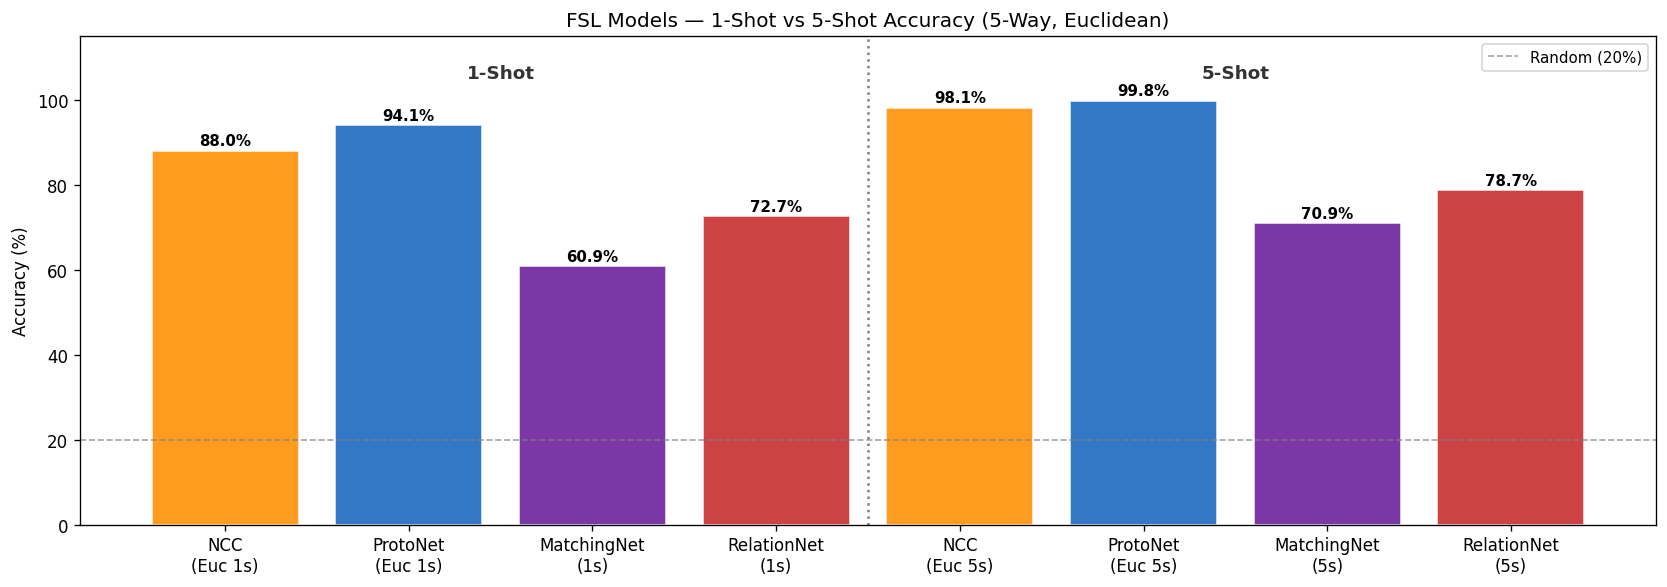

In [233]:
# Quick plot test — all models, best shot (5-shot euclidean where applicable)
models = ['NCC\n(Euc 1s)', 'ProtoNet\n(Euc 1s)', 'MatchingNet\n(1s)', 'RelationNet\n(1s)',
          'NCC\n(Euc 5s)', 'ProtoNet\n(Euc 5s)', 'MatchingNet\n(5s)', 'RelationNet\n(5s)']
keys   = ['ncc_1shot_euc_json', 'proto_1shot_euc_json', 'match_1shot_json', 'rel_1shot_json',
          'ncc_5shot_euc_json', 'proto_5shot_euc_json', 'match_5shot_json', 'rel_5shot_json']
colors = ['#FF8F00','#1565C0','#6A1B9A','#C62828'] * 2
accs   = [R[k]['mean_accuracy_pct'] if R[k] is not None else float('nan') for k in keys]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(models, accs, color=colors, alpha=0.88, edgecolor='white')
for bar, v in zip(bars, accs):
    if not (v != v):  # skip nan
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.5, f'{v:.1f}%',
                ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(y=20, color='gray', linestyle='--', linewidth=1, alpha=0.7, label='Random (20%)')
ax.axvline(x=3.5, color='black', linestyle=':', linewidth=1.5, alpha=0.5)
ax.text(1.5, 105, '1-Shot', ha='center', fontsize=11, fontweight='bold', color='#333')
ax.text(5.5, 105, '5-Shot', ha='center', fontsize=11, fontweight='bold', color='#333')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 115)
ax.set_title('FSL Models — 1-Shot vs 5-Shot Accuracy (5-Way, Euclidean)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

---
## 1. Dataset Overview

**20 bird species** split into base (15) and novel (5) classes.
Base classes are used for supervised training; novel classes are held out for few-shot evaluation.


In [234]:
# Dataset summary table
BASE = [
    'ABBOTTS BABBLER','ABBOTTS BOOBY','ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE','AFRICAN EMERALD CUCKOO','AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER','AFRICAN PIED HORNBILL','AFRICAN PYGMY GOOSE',
    'ALBATROSS','ALBERTS TOWHEE','ALEXANDRINE PARAKEET',
    'ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT','AMERICAN AVOCET'
]
NOVEL = ['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
         'AMERICAN GOLDFINCH','AMERICAN KESTREL']

TRAIN_COUNTS = {
    'ABBOTTS BABBLER':166,'ABBOTTS BOOBY':180,'ABYSSINIAN GROUND HORNBILL':179,
    'AFRICAN CROWNED CRANE':137,'AFRICAN EMERALD CUCKOO':154,'AFRICAN FIREFINCH':137,
    'AFRICAN OYSTER CATCHER':155,'AFRICAN PIED HORNBILL':187,'AFRICAN PYGMY GOOSE':179,
    'ALBATROSS':133,'ALBERTS TOWHEE':161,'ALEXANDRINE PARAKEET':165,
    'ALPINE CHOUGH':166,'ALTAMIRA YELLOWTHROAT':150,'AMERICAN AVOCET':179,
    'AMERICAN BITTERN':170,'AMERICAN COOT':158,'AMERICAN FLAMINGO':164,
    'AMERICAN GOLDFINCH':133,'AMERICAN KESTREL':155
}

df_ds = pd.DataFrame({
    'Class': BASE + NOVEL,
    'Role':  ['Base']*15 + ['Novel']*5,
    'Train Images': [TRAIN_COUNTS[c] for c in BASE + NOVEL],
    'Val Images':  [5]*20,
    'Test Images': [5]*20,
})
df_ds['Total'] = df_ds['Train Images'] + df_ds['Val Images'] + df_ds['Test Images']

print(f"Base classes : {len(BASE)}   |  Novel classes : {len(NOVEL)}")
print(f"Train images : {df_ds['Train Images'].sum()}  |  Val : {df_ds['Val Images'].sum()}  |  Test : {df_ds['Test Images'].sum()}")
print()
display(df_ds.style
    .applymap(lambda v: 'background-color:#0bf007;font-weight:bold' if v=='Base' else
              ('background-color:#f55142;font-weight:bold' if v=='Novel' else ''),
              subset=['Role'])
    .set_caption('Dataset Split: Base vs Novel Classes')
    .format({'Train Images': '{:d}', 'Val Images': '{:d}', 'Test Images': '{:d}', 'Total': '{:d}'})
)


Base classes : 15   |  Novel classes : 5
Train images : 3208  |  Val : 100  |  Test : 100



,Class,Role,Train Images,Val Images,Test Images,Total
0,ABBOTTS BABBLER,Base,166,5,5,176
1,ABBOTTS BOOBY,Base,180,5,5,190
2,ABYSSINIAN GROUND HORNBILL,Base,179,5,5,189
3,AFRICAN CROWNED CRANE,Base,137,5,5,147
4,AFRICAN EMERALD CUCKOO,Base,154,5,5,164
5,AFRICAN FIREFINCH,Base,137,5,5,147
6,AFRICAN OYSTER CATCHER,Base,155,5,5,165
7,AFRICAN PIED HORNBILL,Base,187,5,5,197
8,AFRICAN PYGMY GOOSE,Base,179,5,5,189
9,ALBATROSS,Base,133,5,5,143


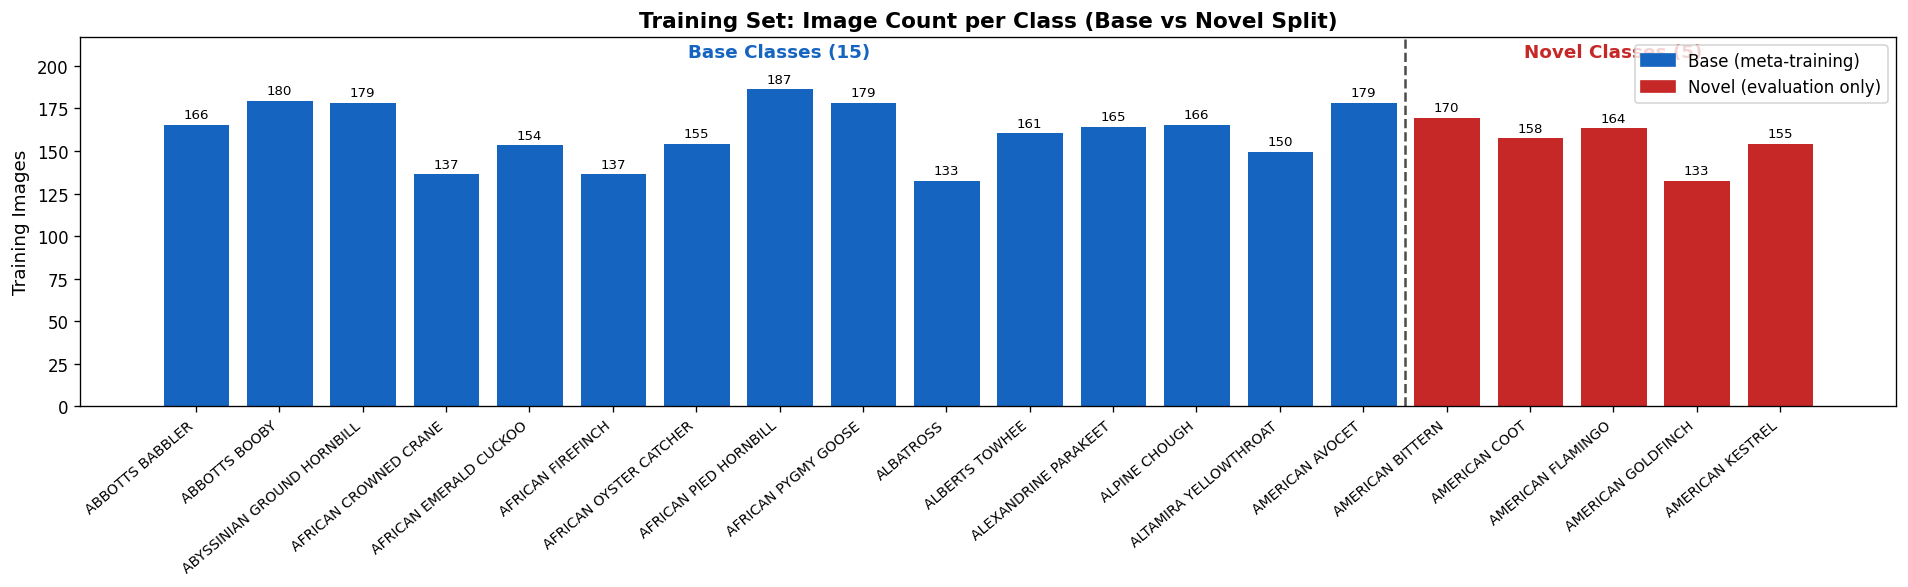

In [235]:
# Training image count bar chart — base/novel coloured
BASE_COL, NOVEL_COL = '#1565C0', '#C62828'
all_classes = BASE + NOVEL
counts = [TRAIN_COUNTS[c] for c in all_classes]
colors = [BASE_COL]*15 + [NOVEL_COL]*5

fig, ax = plt.subplots(figsize=(16, 5))
bars = ax.bar(range(20), counts, color=colors, edgecolor='white', linewidth=0.6)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(20))
ax.set_xticklabels(all_classes, rotation=40, ha='right', fontsize=8.5)
ax.axvline(x=14.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.text(7,  max(counts)+18, 'Base Classes (15)', ha='center', fontsize=11,
        color=BASE_COL, fontweight='bold')
ax.text(17, max(counts)+18, 'Novel Classes (5)',  ha='center', fontsize=11,
        color=NOVEL_COL, fontweight='bold')
ax.legend(handles=[Patch(color=BASE_COL, label='Base (meta-training)'),
                   Patch(color=NOVEL_COL, label='Novel (evaluation only)')], fontsize=10)
ax.set_title('Training Set: Image Count per Class (Base vs Novel Split)', fontsize=13, fontweight='bold')
ax.set_ylabel('Training Images', fontsize=11)
ax.set_ylim(0, max(counts)+30)
plt.tight_layout()
plt.savefig(f'{RES}/analysis/dataset_class_distribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


---
## 2. Supervised Baseline — Full-20

ResNet-50 trained on **all 20 classes** (supervised, no few-shot protocol).
Serves as an upper-bound reference — the model has seen all classes during training.

> ⚠️ **Note:** Val/test sets are very small (5 images per class = 100 total).
> Results should be interpreted with caution — the 95% CI is wide.
> Epoch count is read from `summary.json` and shown dynamically below.

In [236]:
r = R['full20_json']
if r is None:
    print('Full-20 results not available')
else:
    ci = r['accuracy_ci_95']
    print("=" * 55)    
    print(f"  Full-20 Supervised Baseline — Test Set Results")
    print("=" * 55)
    print(f"  Test images     : {r['test_images']}  ({r['num_classes']} classes × 5 images)")
    print(f"  Epochs trained  : {r['epochs_trained']}")
    print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
    print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
    print(f"  Macro F1        : {r['macro_f1']:.4f}")
    print(f"  Macro Precision : {r['macro_precision']:.4f}")
    print(f"  Macro Recall    : {r['macro_recall']:.4f}")
    print(f"  Macro AUC (OvR) : {r['macro_auc_ovr']:.4f}")
    print(f"  Best Val Acc    : {r['val_acc_best']*100:.2f}%")
    

  Full-20 Supervised Baseline — Test Set Results
  Test images     : 100  (20 classes × 5 images)
  Epochs trained  : 3
  Accuracy        : 99.00%
  95% Wilson CI   : [94.55%, 99.82%]
  Macro F1        : 0.9899
  Macro Precision : 0.9917
  Macro Recall    : 0.9900
  Macro AUC (OvR) : 1.0000
  Best Val Acc    : 100.00%


In [237]:
# Full-20 — Classification report
cr_path = f'{RES}/baseline/resnet50/full20/classification_report.csv'
if os.path.exists(cr_path):
    df_cr = pd.read_csv(cr_path, index_col=0)
    print("Per-class classification report (Full-20):")
    display(df_cr.style
        .background_gradient(cmap='Blues', subset=['f1-score','precision','recall'], vmin=0, vmax=1)
        .format('{:.3f}', subset=['f1-score','precision','recall'])
        .set_caption('Full-20 Baseline: Per-Class Metrics')
    )
else:
    print(f"Classification report not found: {cr_path}")


Per-class classification report (Full-20):


,precision,recall,f1-score,support
ABBOTTS BABBLER,1.000,1.000,1.000,5.000000
ABBOTTS BOOBY,1.000,1.000,1.000,5.000000
ABYSSINIAN GROUND HORNBILL,1.000,1.000,1.000,5.000000
AFRICAN CROWNED CRANE,1.000,1.000,1.000,5.000000
AFRICAN EMERALD CUCKOO,1.000,1.000,1.000,5.000000
AFRICAN FIREFINCH,1.000,1.000,1.000,5.000000
AFRICAN OYSTER CATCHER,1.000,1.000,1.000,5.000000
AFRICAN PIED HORNBILL,0.833,1.000,0.909,5.000000
AFRICAN PYGMY GOOSE,1.000,1.000,1.000,5.000000
ALBATROSS,1.000,1.000,1.000,5.000000


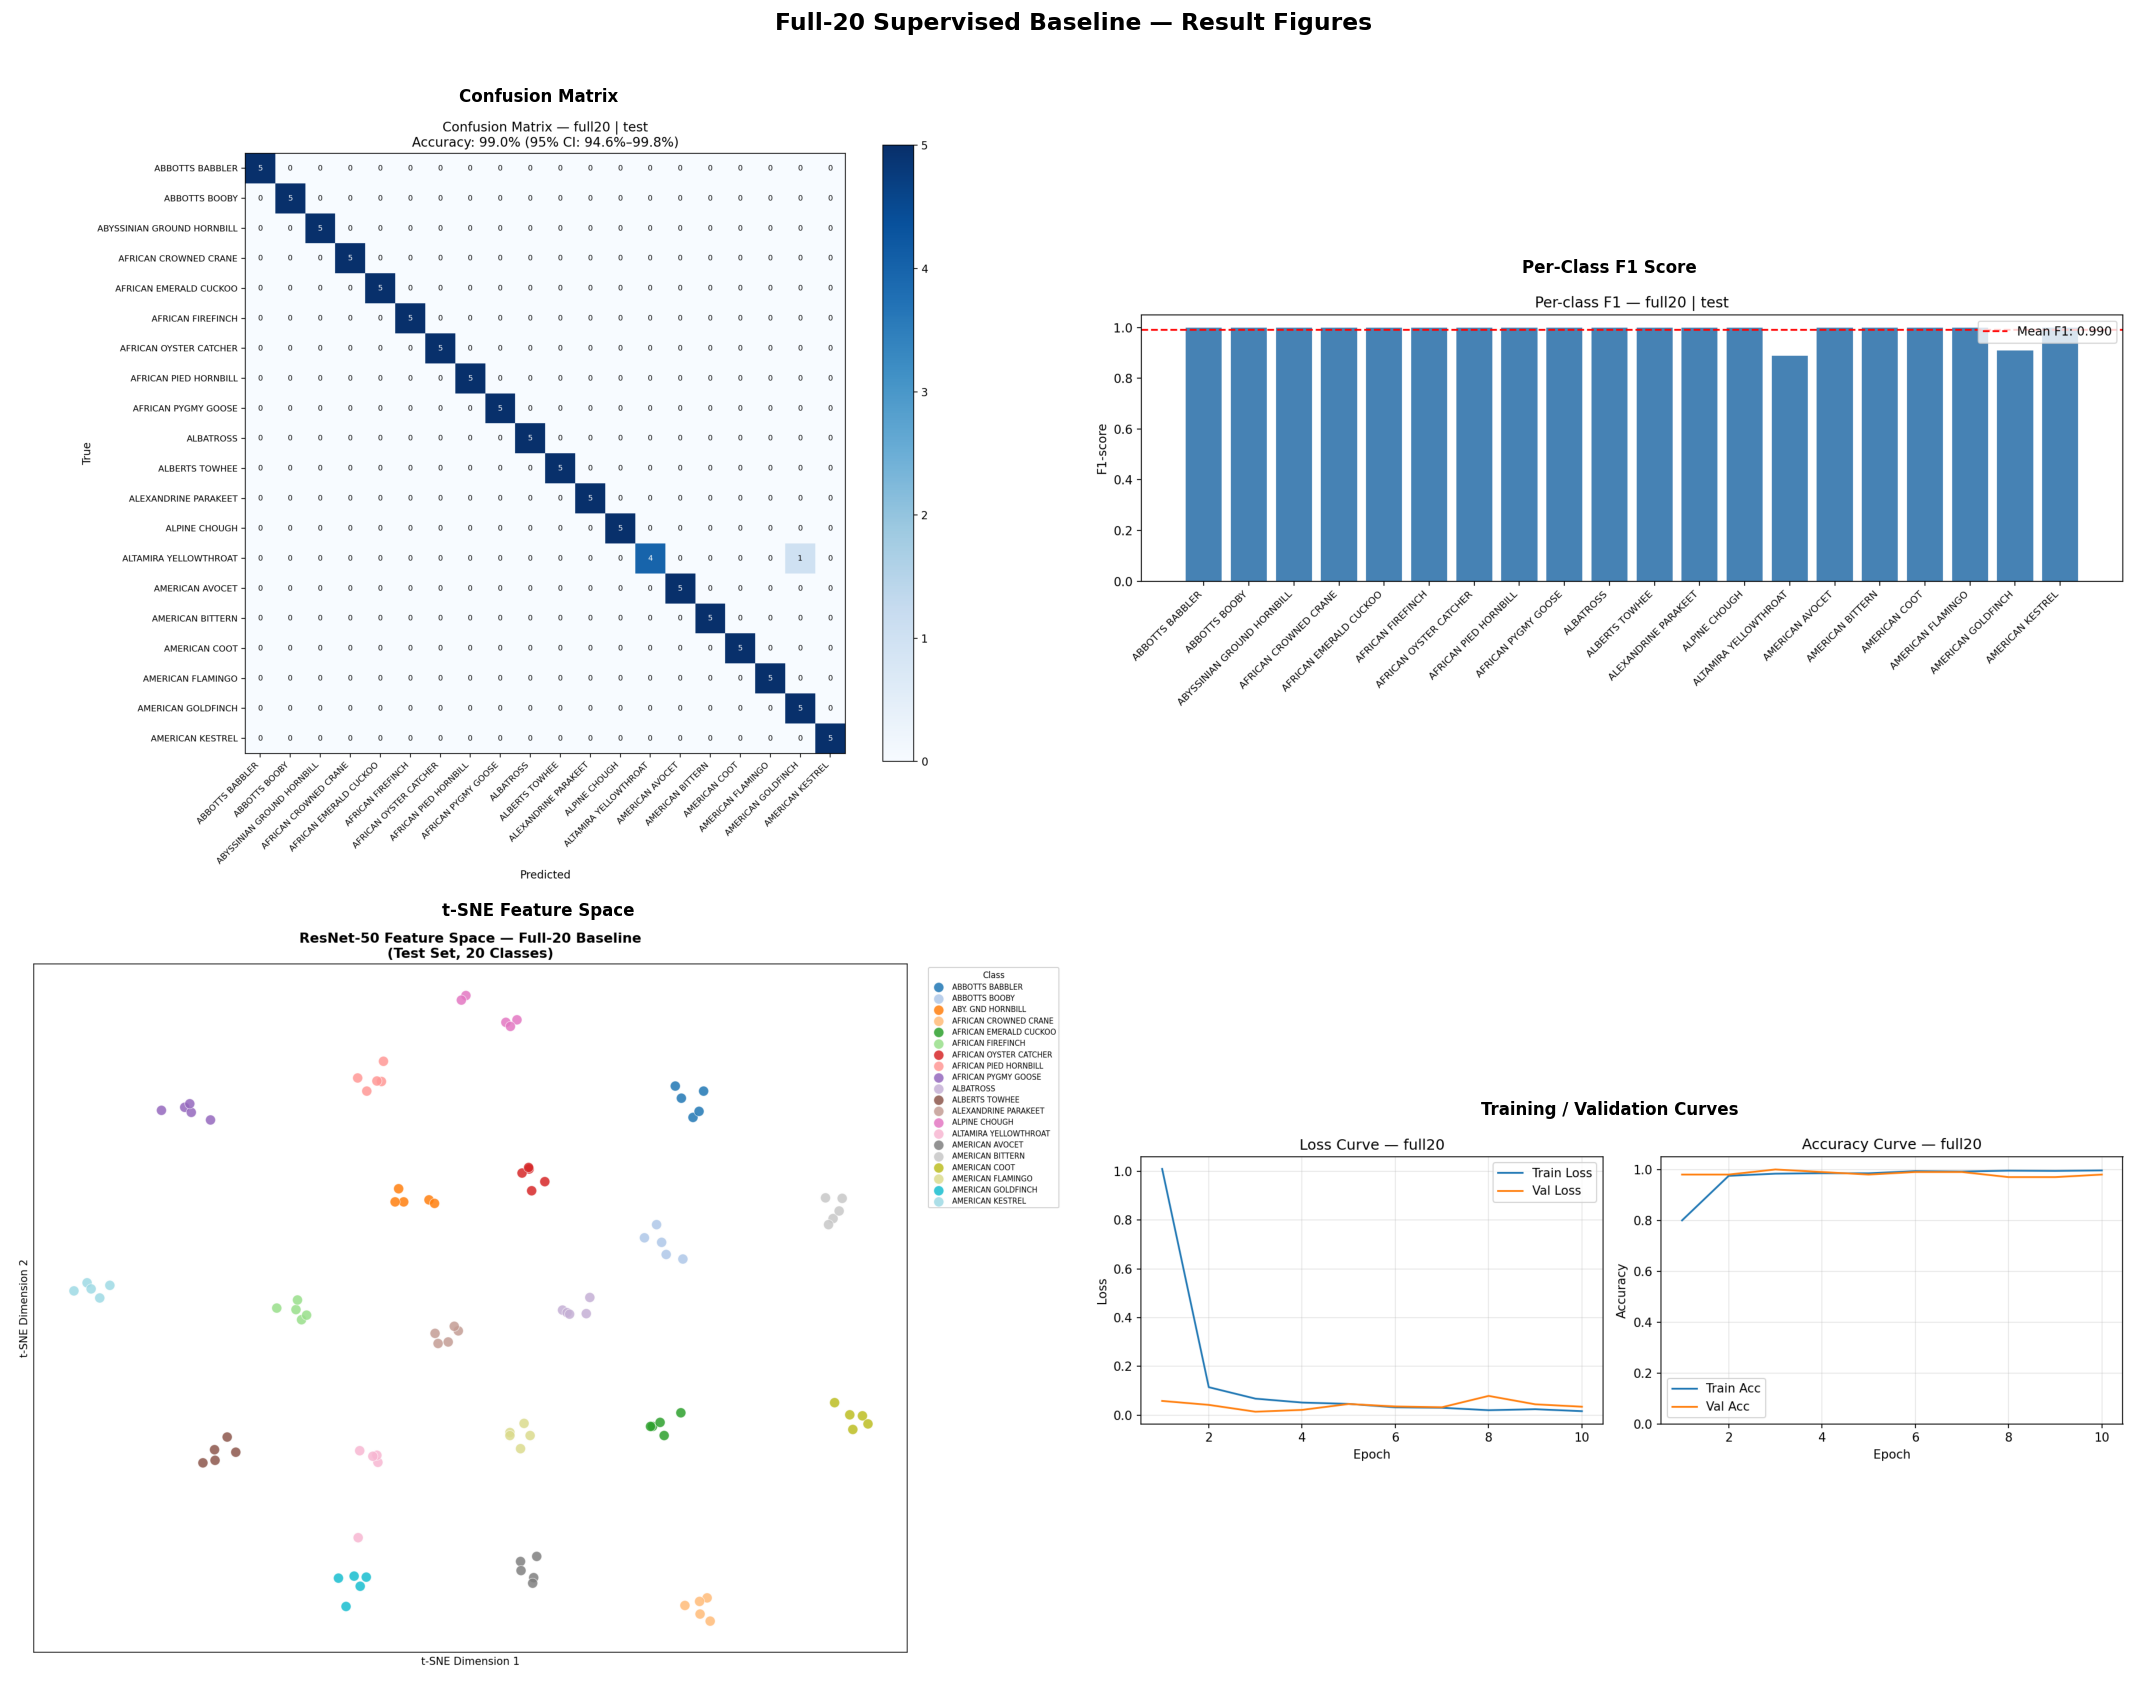

In [238]:
# Full-20 — Figures: confusion matrix, F1 per class, t-SNE, learning curves
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/full20'
show_img(f'{base_path}/confusion_matrix.png',  axes[0], 'Confusion Matrix')
show_img(f'{base_path}/f1_per_class.png',       axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',      axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',    axes[3], 'Training / Validation Curves')

plt.suptitle('Full-20 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{RES}/analysis/full20_results_panel.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


---
## 3. Supervised Baseline — Base-15

ResNet-50 trained on **15 base classes only** (the FSL meta-training set).
This model is **never shown the novel classes** during training — its performance on base classes
shows the quality of the learned feature space before few-shot adaptation.


In [239]:
r = R['base15_json']
if r is None:
    print('Base-15 results not available')
else:
    ci = r['accuracy_ci_95']
    print("=" * 55)    
    print(f"  Base-15 Supervised Baseline — Test Set Results")
    print("=" * 55)
    print(f"  Base classes    : {r.get('num_base_classes', 15)}")
    print(f"  Test samples    : {r.get('num_test_samples', '—')}")
    print(f"  Accuracy        : {r['accuracy']*100:.2f}%")
    print(f"  95% Wilson CI   : [{ci[0]*100:.2f}%, {ci[1]*100:.2f}%]")
    print(f"  Macro F1        : {r['macro_f1']:.4f}")
    print(f"  Macro Precision : {r['macro_precision']:.4f}")
    print(f"  Macro Recall    : {r['macro_recall']:.4f}")
    print(f"  AUC-OVR (macro) : {r.get('auc_ovr', float('nan')):.4f}")
    

  Base-15 Supervised Baseline — Test Set Results
  Base classes    : 15
  Test samples    : 75
  Accuracy        : 100.00%
  95% Wilson CI   : [95.13%, 100.00%]
  Macro F1        : 1.0000
  Macro Precision : 1.0000
  Macro Recall    : 1.0000
  AUC-OVR (macro) : 1.0000


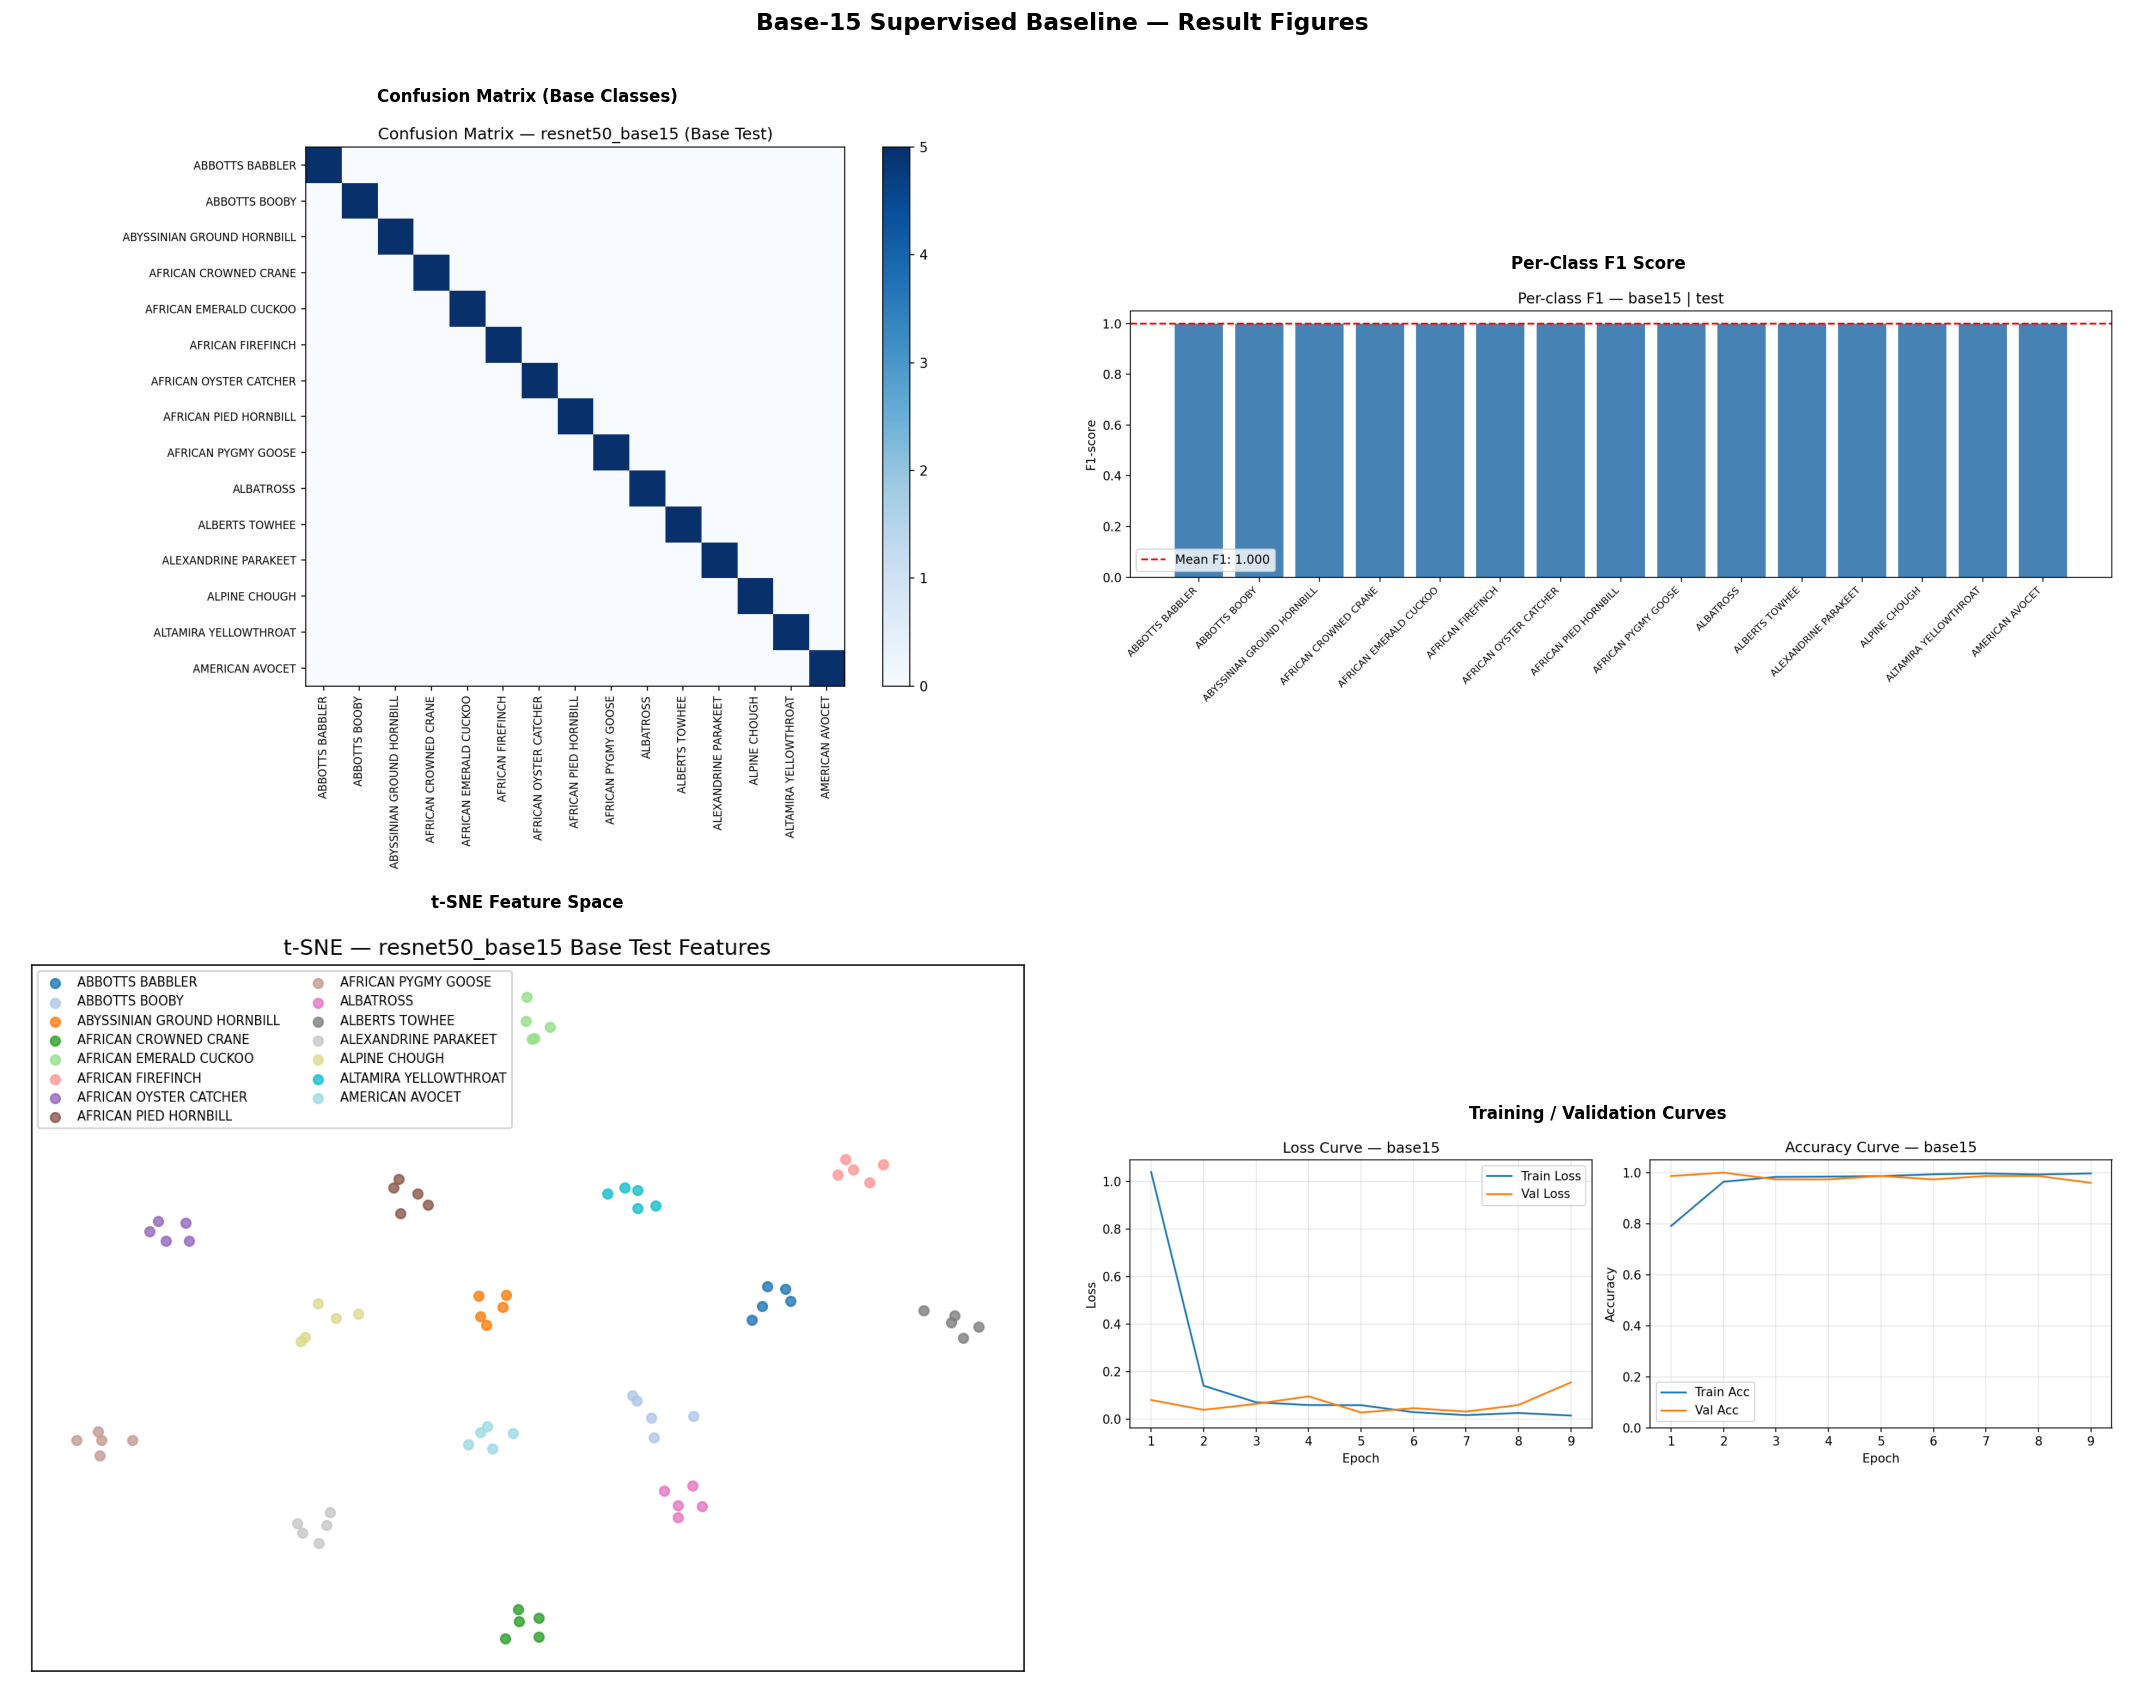

In [240]:
# Base-15 — Figures panel
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

base_path = f'{RES}/baseline/resnet50/base15/base_test'
show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix (Base Classes)')
show_img(f'{base_path}/f1_per_class.png',      axes[1], 'Per-Class F1 Score')
show_img(f'{base_path}/tsne_features.png',     axes[2], 't-SNE Feature Space')
show_img(f'{base_path}/learning_curves.png',   axes[3], 'Training / Validation Curves')

plt.suptitle('Base-15 Supervised Baseline — Result Figures', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{RES}/analysis/base15_results_panel.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()


In [241]:
from IPython.display import display, Markdown
_r = R['proto_euc_json']
display(Markdown(f"""---
## 4. Prototypical Networks — 5-Way {_r['k_shot']}-Shot (Euclidean, {_r['num_episodes']} Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** {_r['n_way']}-way {_r['k_shot']}-shot, {_r['num_episodes']} random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** {"✅ High — statistically reliable" if _r['num_episodes'] >= 100 else f"⚠️ Low — only {_r['num_episodes']} episodes"}
"""))

---
## 4. Prototypical Networks — 5-Way 1-Shot (Euclidean, 600 Episodes)

**Main FSL result.** ProtoNet computes a prototype (mean embedding) per class from
the support set, then classifies query images by nearest-prototype distance.

- **Protocol:** 5-way 1-shot, 600 random episodes
- **Query set:** all 5 novel TEST images per class (fixed, no data leakage)
- **Distance:** Euclidean (L2) — as in the original ProtoNet paper (Snell et al., 2017)
- **Reliability:** ✅ High — statistically reliable


In [242]:
# ProtoNet — all shots × distances summary table
SHOTS = [1, 3, 5]
DIST_MAP = {'euc': 'Euclidean (L2)', 'man': 'Manhattan (L1)'}

rows_proto = []
for shot in SHOTS:
    for dist_key, dist_label in DIST_MAP.items():
        key = f'proto_{shot}shot_{dist_key}_json'
        r = R.get(key)
        if r is None:
            continue
        ci = r['wilson_ci_95']
        rows_proto.append({
            'K-Shot'      : f'{shot}-shot',
            'Distance'    : dist_label,
            'Episodes'    : r['num_episodes'],
            'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
            '95% CI ±'    : round(r['ci95_pct'], 2),
            'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
            'Macro F1'    : round(r.get('macro_f1', float('nan')), 4),
            'Precision'   : round(r.get('macro_precision', float('nan')), 4),
            'Recall'      : round(r.get('macro_recall', float('nan')), 4),
            'AUC-OVR'     : round(r.get('auc_ovr', float('nan')), 4),
            'Std (%)'     : round(r['std_accuracy_pct'], 2),
        })

df_proto = pd.DataFrame(rows_proto)
print("ProtoNet — 5-Way, All Shot Configurations (600 episodes each)")
display(df_proto.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=50, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'AUC-OVR': '{:.4f}', 'Std (%)': '{:.2f}'})
    .set_caption('ProtoNet — All Shots × Distances (5-way, 600 episodes each)')
)

# Per-class accuracy comparison across shots (Euclidean)
print("\nPer-class accuracy — Euclidean, all shots:")
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys()) if R.get('proto_1shot_euc_json') else []
df_pc = pd.DataFrame({'Class': novel_classes})
for shot in SHOTS:
    r = R.get(f'proto_{shot}shot_euc_json')
    if r:
        df_pc[f'{shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_pc.columns if 'shot' in c]
display(df_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('ProtoNet (Euclidean) — Per-Class Accuracy by K-Shot')
)

ProtoNet — 5-Way, All Shot Configurations (600 episodes each)


,K-Shot,Distance,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Macro F1,Precision,Recall,AUC-OVR,Std (%)
0,1-shot,Euclidean (L2),600,94.06,0.68,"[93.67%, 94.43%]",0.9397,0.9443,0.9406,0.9964,8.49
1,1-shot,Manhattan (L1),600,79.67,1.01,"[79.02%, 80.31%]",0.7918,0.8253,0.7967,0.9351,12.57
2,3-shot,Euclidean (L2),600,99.18,0.26,"[99.02%, 99.31%]",0.9918,0.9919,0.9918,1.0000,3.19
3,3-shot,Manhattan (L1),600,89.63,0.77,"[89.13%, 90.10%]",0.8947,0.9042,0.8963,0.9835,9.66
4,5-shot,Euclidean (L2),600,99.80,0.10,"[99.71%, 99.86%]",0.9980,0.9980,0.9980,1.0000,1.23
5,5-shot,Manhattan (L1),600,93.29,0.61,"[92.88%, 93.68%]",0.9317,0.9369,0.9329,0.9930,7.65



Per-class accuracy — Euclidean, all shots:


,Class,1-shot (%),3-shot (%),5-shot (%)
0,AMERICAN BITTERN,94.20%,99.87%,100.00%
1,AMERICAN COOT,98.77%,100.00%,100.00%
2,AMERICAN FLAMINGO,98.73%,98.20%,100.00%
3,AMERICAN GOLDFINCH,98.37%,100.00%,100.00%
4,AMERICAN KESTREL,80.23%,97.83%,99.00%


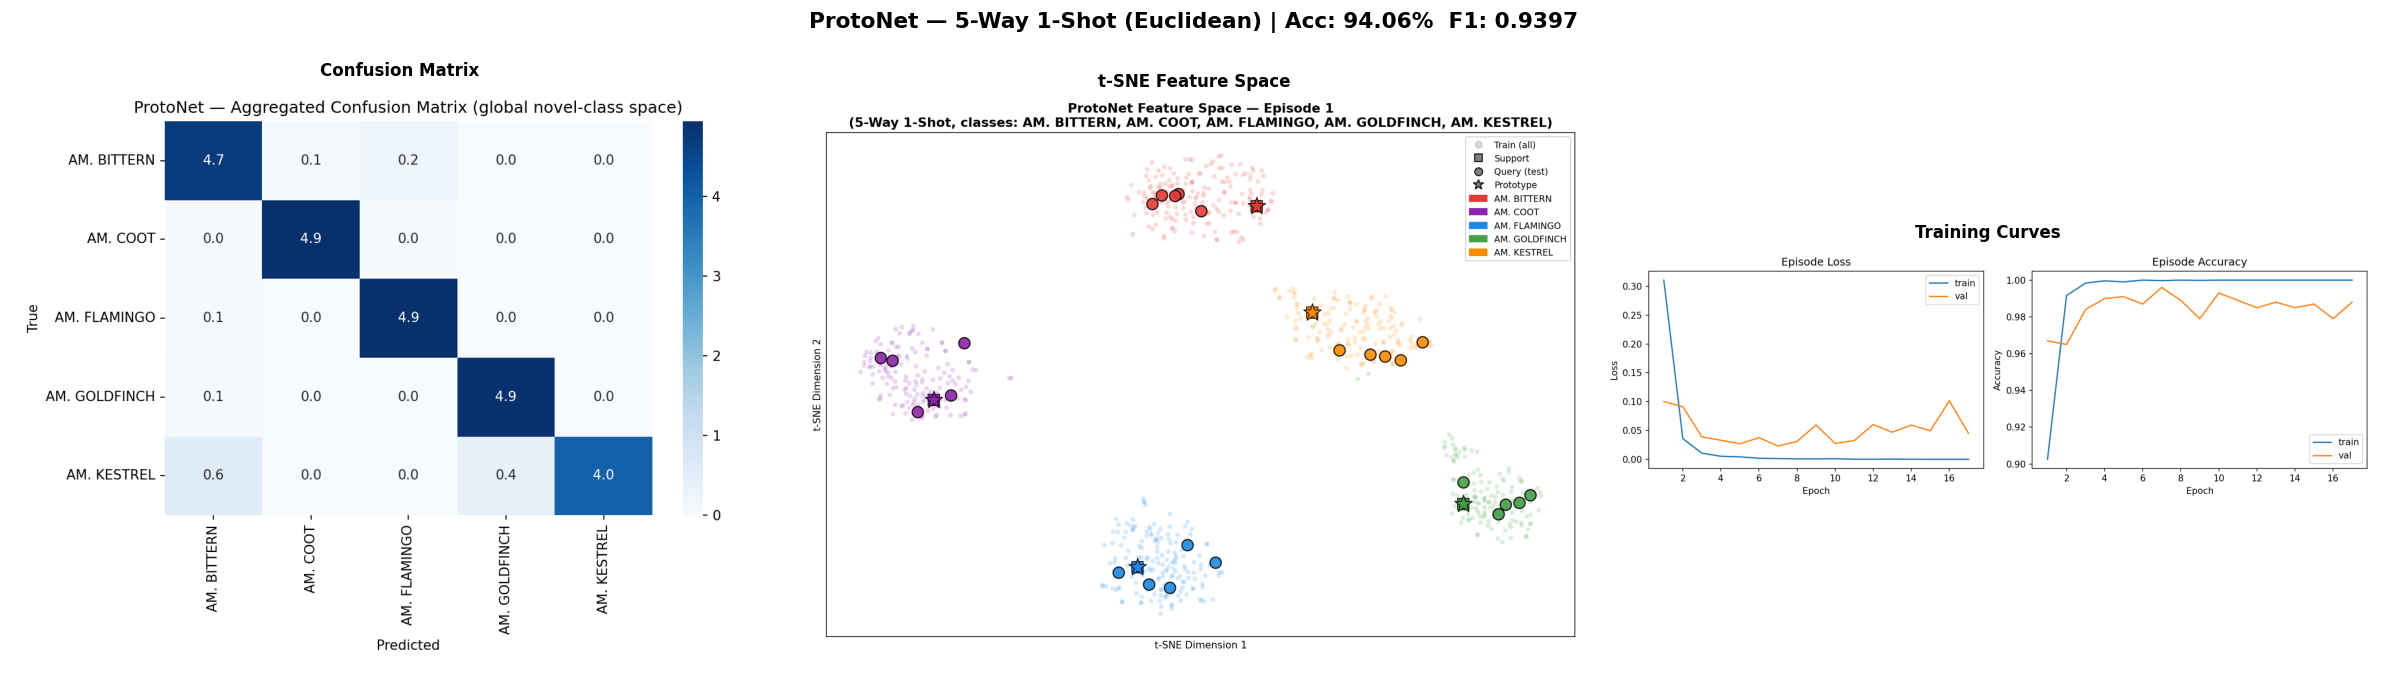

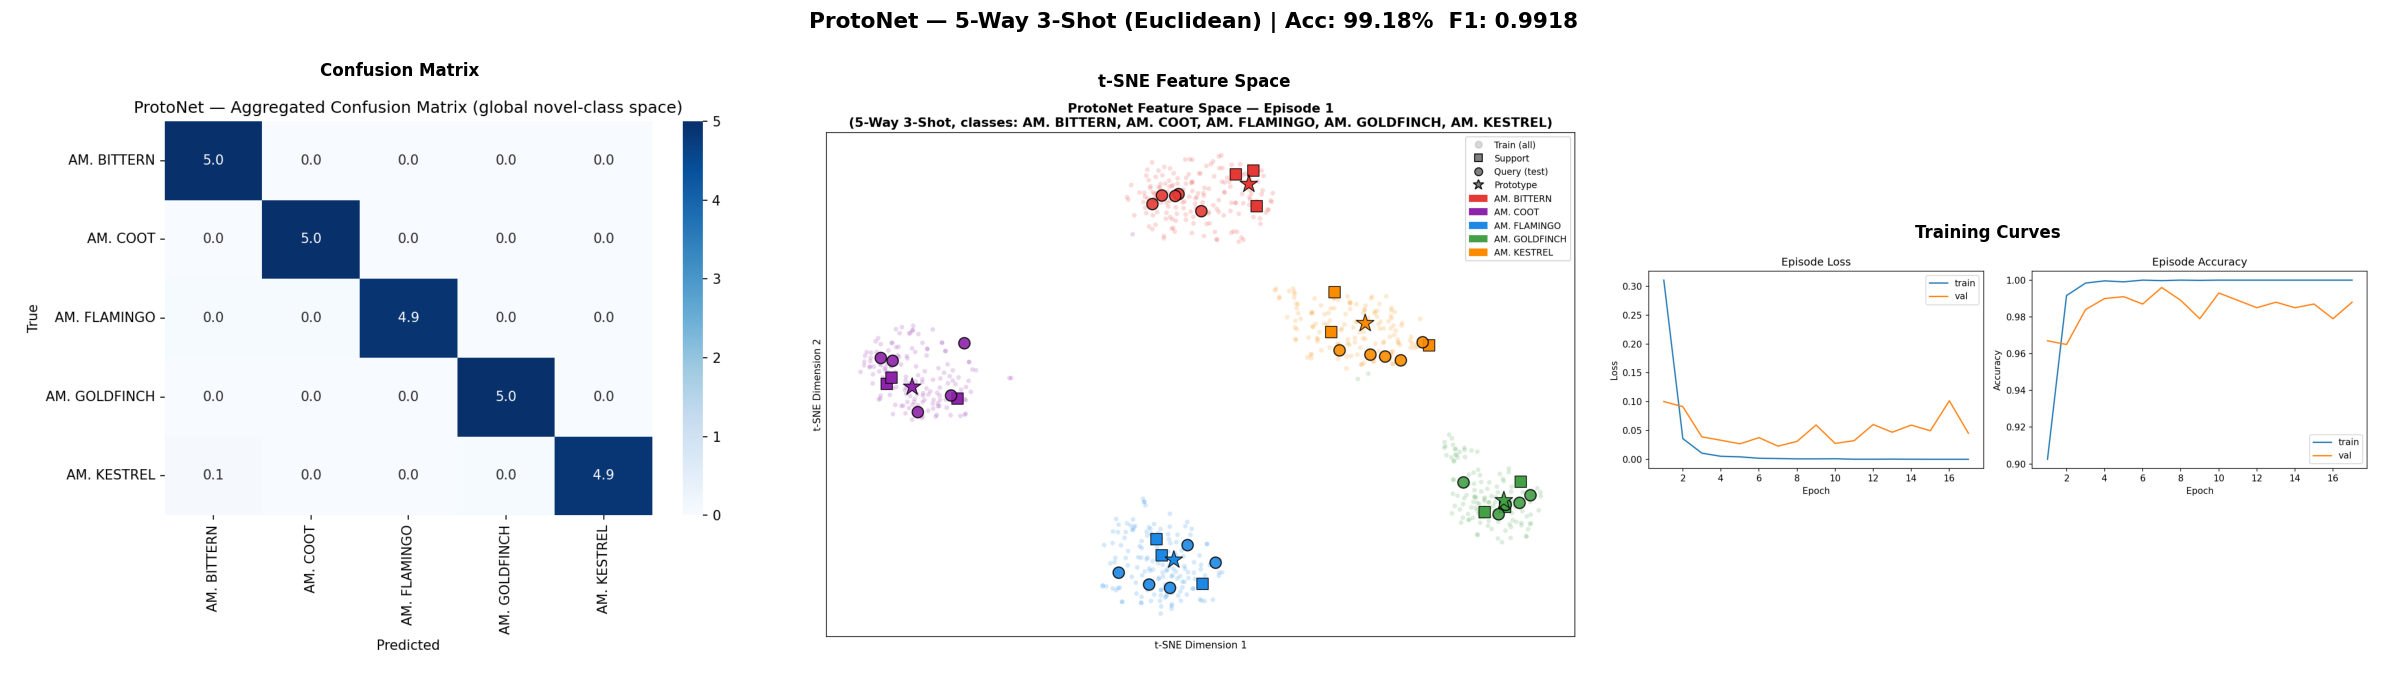

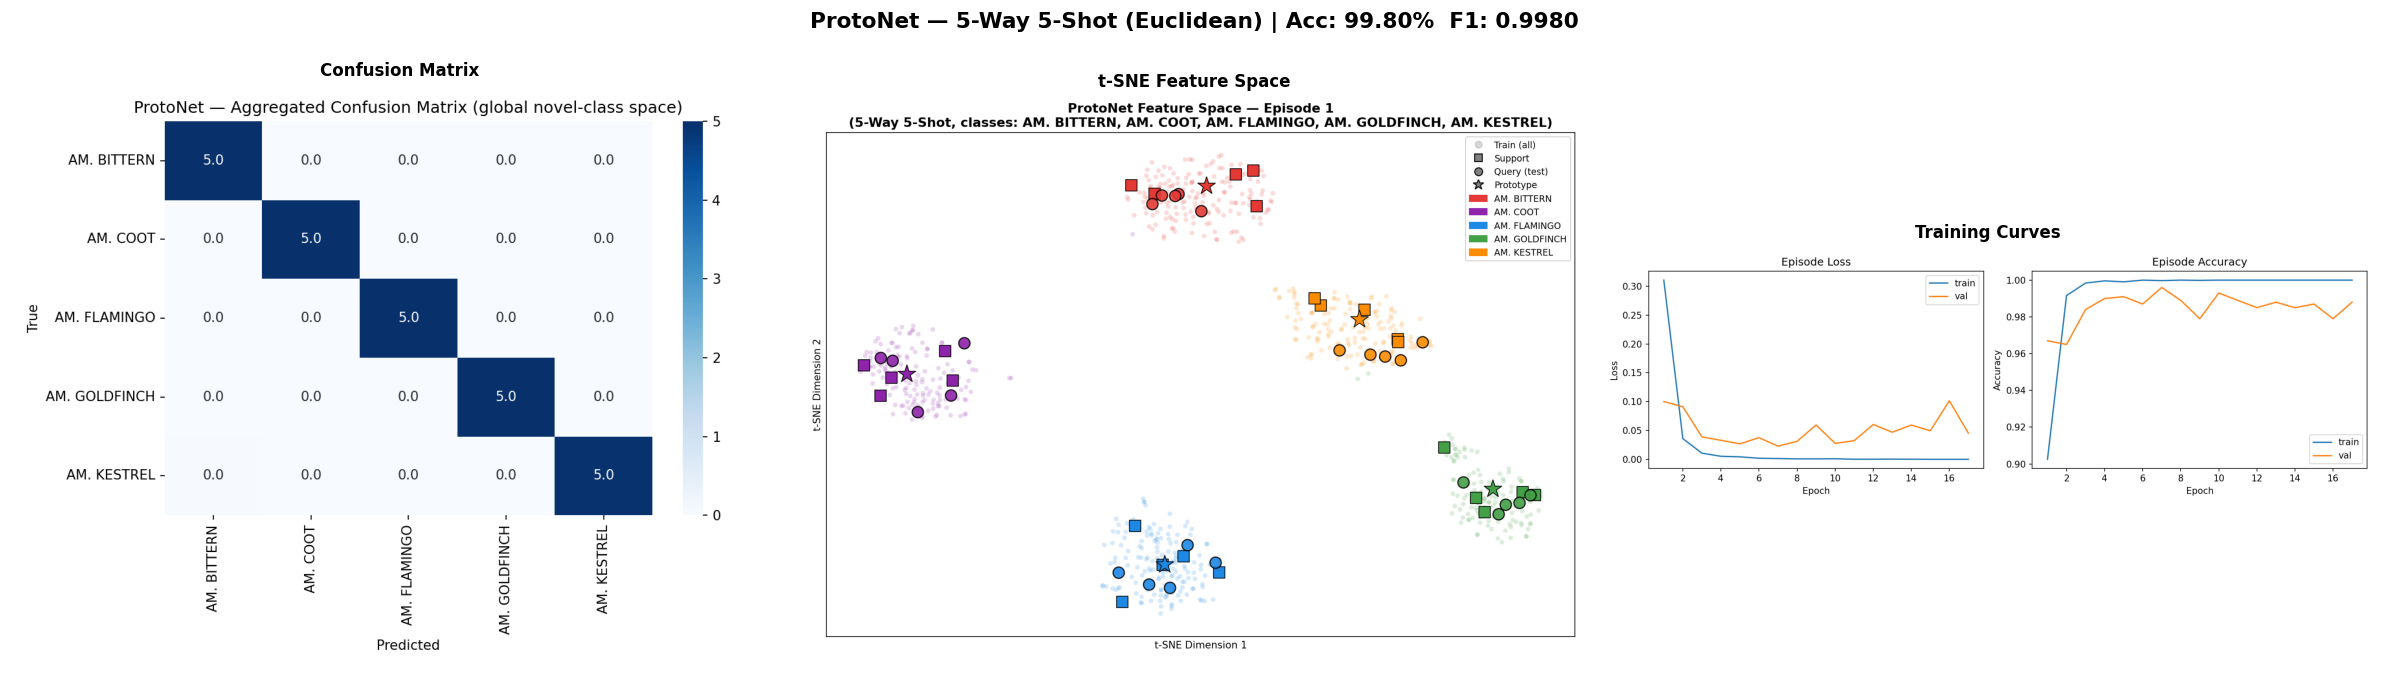

In [243]:
# ProtoNet figures — one panel per shot (Euclidean)
for shot in [1, 3, 5]:
    r = R.get(f'proto_{shot}shot_euc_json')
    if r is None:
        print(f"No data for {shot}-shot Euclidean — skipping")
        continue
    base_path = f'{RES}/proto_net/base15_novel5/{shot}shot_euclidean'
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
    show_img(f'{base_path}/tsne_features.png',    axes[1], 't-SNE Feature Space')
    show_img(f'{base_path}/learning_curves.png',  axes[2], 'Training Curves')
    plt.suptitle(
        f'ProtoNet — 5-Way {shot}-Shot (Euclidean) | '
        f"Acc: {r['mean_accuracy_pct']:.2f}%  F1: {r['macro_f1']:.4f}",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.savefig(f'{RES}/analysis/protonet_{shot}shot_euc_panel.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

In [244]:
from IPython.display import display, Markdown
_e = R['proto_euc_json']
_m = R['proto_man_json']
_man_warn = (f"\n> ⚠️ Manhattan result is based on only **{_m['num_episodes']} episodes** — "
             "treat as indicative only. Re-run with `--distance manhattan` for 600 episodes."
             if _m['num_episodes'] < 100 else "")
display(Markdown(f"""---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **{_e['num_episodes']} episodes** — {"✅ reliable" if _e['num_episodes'] >= 100 else "⚠️ indicative"}
- Manhattan: **{_m['num_episodes']} episodes** — {"✅ reliable" if _m['num_episodes'] >= 100 else "⚠️ indicative"}
{_man_warn}
"""))

---
## 5. ProtoNet — Distance Metric Ablation (Euclidean vs Manhattan)

Using the **same trained checkpoint**, only the distance function changes.
This ablation tests whether L2 (Euclidean) or L1 (Manhattan) distance
better captures class structure in the learned embedding space.

- Euclidean: **600 episodes** — ✅ reliable
- Manhattan: **600 episodes** — ✅ reliable



,K-Shot,Distance,Mean Acc (%),95% CI ±,Macro F1,Episodes
0,1-shot,Euclidean (L2),94.06,0.68,0.9397,600
1,1-shot,Manhattan (L1),79.67,1.01,0.7918,600
2,3-shot,Euclidean (L2),99.18,0.26,0.9918,600
3,3-shot,Manhattan (L1),89.63,0.77,0.8947,600
4,5-shot,Euclidean (L2),99.80,0.10,0.9980,600
5,5-shot,Manhattan (L1),93.29,0.61,0.9317,600


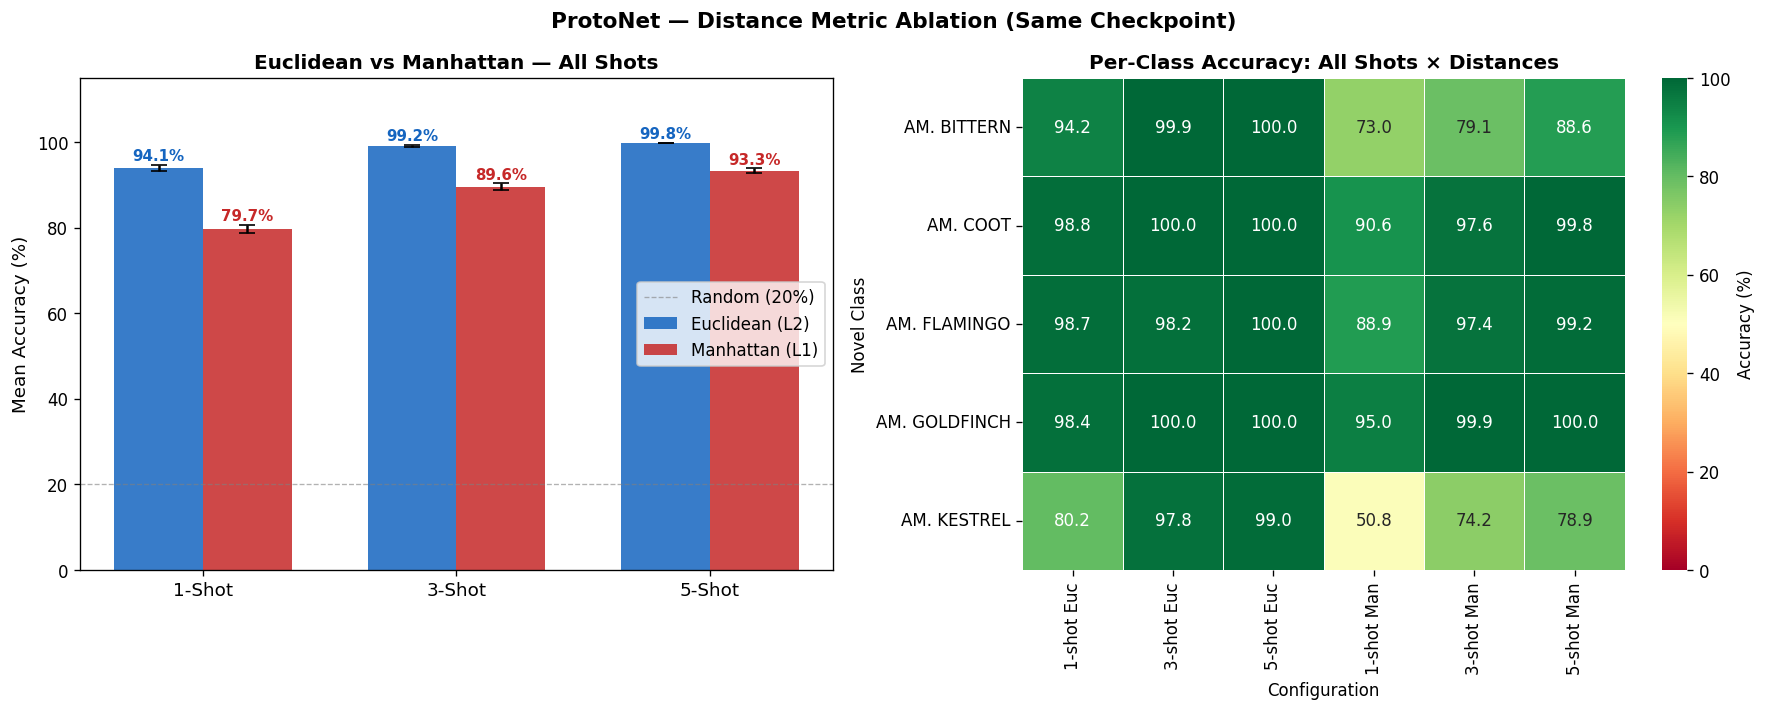

In [245]:
# ProtoNet — Distance Ablation across all shots
rows_abl = []
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean (L2)'), ('man', 'Manhattan (L1)')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        if r is None: continue
        rows_abl.append({
            'K-Shot'      : f'{shot}-shot',
            'Distance'    : dist_label,
            'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
            '95% CI ±'    : round(r['ci95_pct'], 2),
            'Macro F1'    : round(r['macro_f1'], 4),
            'Episodes'    : r['num_episodes'],
        })

df_abl = pd.DataFrame(rows_abl)
display(df_abl.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=50, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}'})
    .set_caption('ProtoNet — Euclidean vs Manhattan, All Shots (same checkpoint)')
)

# Bar chart: grouped by shot, Euc vs Man side-by-side
shots = [1, 3, 5]
acc_euc = [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] for s in shots]
acc_man = [R[f'proto_{s}shot_man_json']['mean_accuracy_pct'] for s in shots]
ci_euc  = [R[f'proto_{s}shot_euc_json']['ci95_pct'] for s in shots]
ci_man  = [R[f'proto_{s}shot_man_json']['ci95_pct'] for s in shots]

x = np.arange(len(shots)); w = 0.35
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grouped bar chart
axes[0].bar(x - w/2, acc_euc, w, label='Euclidean (L2)', color='#1565C0', alpha=0.85)
axes[0].bar(x + w/2, acc_man, w, label='Manhattan (L1)', color='#C62828', alpha=0.85)
axes[0].errorbar(x - w/2, acc_euc, yerr=ci_euc, fmt='none', color='black', capsize=5)
axes[0].errorbar(x + w/2, acc_man, yerr=ci_man, fmt='none', color='black', capsize=5)
axes[0].axhline(y=20, color='gray', linestyle='--', linewidth=0.8, alpha=0.6, label='Random (20%)')
axes[0].set_xticks(x); axes[0].set_xticklabels([f'{s}-Shot' for s in shots], fontsize=11)
axes[0].set_ylabel('Mean Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 115)
axes[0].set_title('Euclidean vs Manhattan — All Shots', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=10)
for i, (ae, am) in enumerate(zip(acc_euc, acc_man)):
    axes[0].text(i - w/2, ae + ci_euc[i] + 1, f'{ae:.1f}%', ha='center', fontsize=9, fontweight='bold', color='#1565C0')
    axes[0].text(i + w/2, am + ci_man[i] + 1, f'{am:.1f}%', ha='center', fontsize=9, fontweight='bold', color='#C62828')

# Per-class heatmap for 1-shot (primary)
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys()) if R.get('proto_1shot_euc_json') else []
short = [c.replace('AMERICAN ', 'AM. ') for c in novel_classes]
heat_data = {
    f'{s}-shot Euc': [R[f'proto_{s}shot_euc_json']['per_class_accuracy_pct'][c] for c in novel_classes]
    for s in shots
}
heat_data.update({
    f'{s}-shot Man': [R[f'proto_{s}shot_man_json']['per_class_accuracy_pct'][c] for c in novel_classes]
    for s in shots
})
df_heat_abl = pd.DataFrame(heat_data, index=short)
sns.heatmap(df_heat_abl, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.5, ax=axes[1], cbar_kws={'label': 'Accuracy (%)'})
axes[1].set_title('Per-Class Accuracy: All Shots × Distances', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Configuration'); axes[1].set_ylabel('Novel Class')

plt.suptitle('ProtoNet — Distance Metric Ablation (Same Checkpoint)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/protonet_distance_ablation.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

In [246]:
from IPython.display import display, Markdown
_r = R['match_json']
_n = _r['num_episodes']
_warn = (f"\n> ⚠️ Only **{_n} episodes** run — CI is very wide and unreliable. "
         "Re-run `python evaluate.py` (without `--debug`) to get 600 episodes."
         if _n < 100 else f"\n> ✅ **{_n} episodes** — statistically reliable.")
display(Markdown(f"""---
## 6. Matching Networks — 5-Way {_r['k_shot']}-Shot ({_n} Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.
{_warn}
"""))

---
## 6. Matching Networks — 5-Way 1-Shot (600 Episodes)

Matching Networks classify queries by attending over the support set using
a softmax over cosine similarities between query and support embeddings.

> ✅ **600 episodes** — statistically reliable.


In [247]:
# MatchingNet — all shots summary table
rows_mn = []
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r is None: continue
    ci = r['wilson_ci_95']
    rows_mn.append({
        'K-Shot'      : f'{shot}-shot',
        'Episodes'    : r['num_episodes'],
        'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
        '95% CI ±'    : round(r['ci95_pct'], 2),
        'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
        'Macro F1'    : round(r.get('macro_f1', float('nan')), 4),
        'Precision'   : round(r.get('macro_precision', float('nan')), 4),
        'Recall'      : round(r.get('macro_recall', float('nan')), 4),
        'AUC-OVR'     : round(r.get('auc_ovr', float('nan')), 4),
        'Std (%)'     : round(r['std_accuracy_pct'], 2),
    })

df_mn = pd.DataFrame(rows_mn)
print("Matching Networks — 5-Way, All Shot Configurations")
display(df_mn.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=0, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'AUC-OVR': '{:.4f}', 'Std (%)': '{:.2f}'})
    .set_caption('MatchingNet — All Shots (5-way, 600 episodes each)')
)

# Per-class comparison across shots
novel_classes = list(R['match_1shot_json']['per_class_accuracy_pct'].keys()) if R.get('match_1shot_json') else []
df_mn_pc = pd.DataFrame({'Class': novel_classes})
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r:
        df_mn_pc[f'{shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_mn_pc.columns if 'shot' in c]
display(df_mn_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('MatchingNet — Per-Class Accuracy by K-Shot')
)

Matching Networks — 5-Way, All Shot Configurations


,K-Shot,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Macro F1,Precision,Recall,AUC-OVR,Std (%)
0,1-shot,600,60.93,0.88,"[60.15%, 61.71%]",0.5829,0.5828,0.6093,0.8306,11.03
1,3-shot,600,68.03,0.64,"[67.28%, 68.77%]",0.6455,0.6518,0.6803,0.8756,8.03
2,5-shot,600,70.87,0.59,"[70.13%, 71.59%]",0.6685,0.6859,0.7087,0.8937,7.43


,Class,1-shot (%),3-shot (%),5-shot (%)
0,AMERICAN BITTERN,87.40%,99.03%,100.00%
1,AMERICAN COOT,47.80%,56.17%,59.70%
2,AMERICAN FLAMINGO,53.53%,67.37%,78.77%
3,AMERICAN GOLDFINCH,96.63%,99.60%,100.00%
4,AMERICAN KESTREL,19.30%,17.97%,15.87%


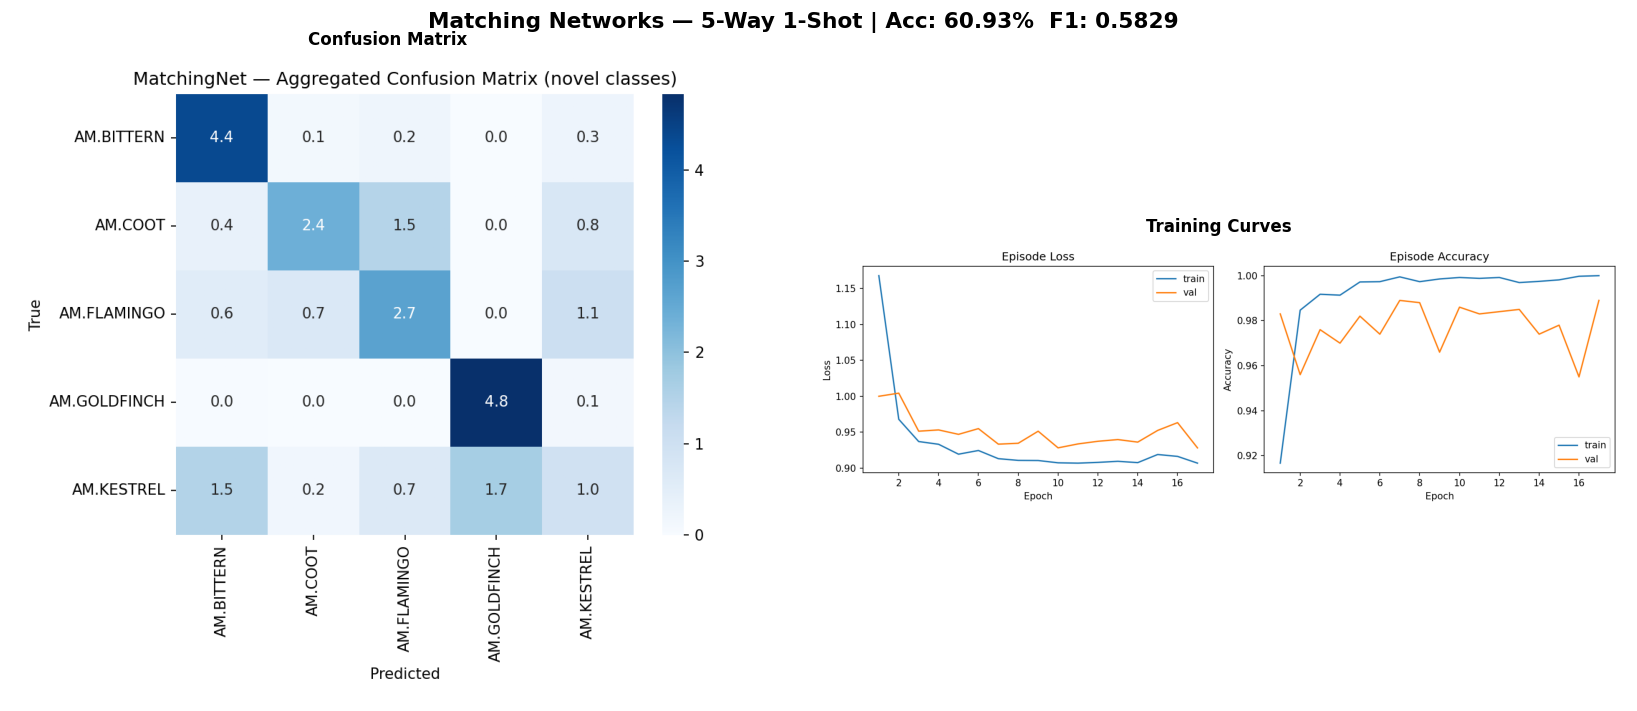

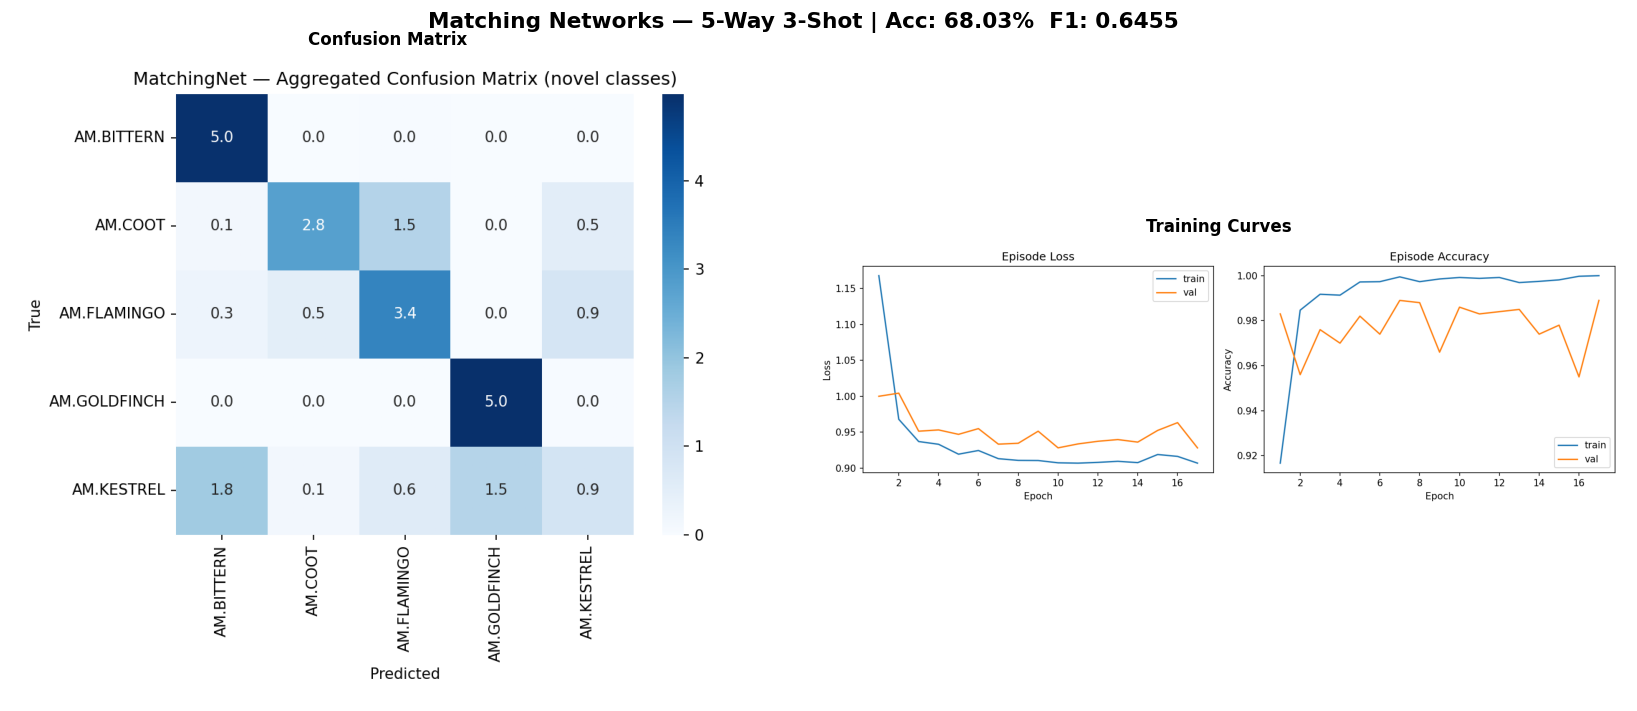

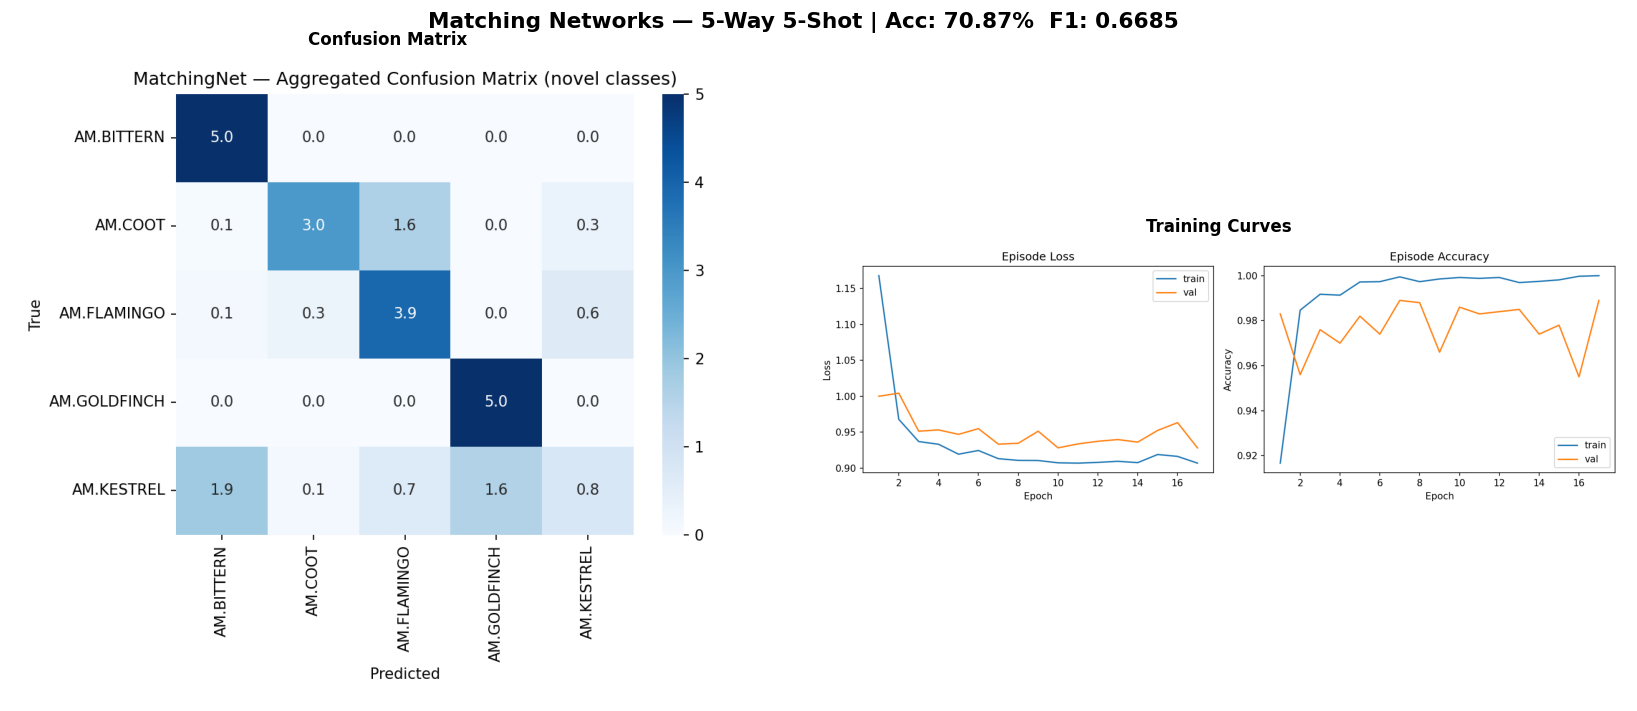

In [248]:
# MatchingNet figures — one panel per shot
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r is None:
        print(f"No data for MatchingNet {shot}-shot — skipping")
        continue
    base_path = f'{RES}/matching_net/base15_novel5/{shot}shot'
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    show_img(f'{base_path}/confusion_matrix.png', axes[0], 'Confusion Matrix')
    show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
    plt.suptitle(
        f"Matching Networks — 5-Way {shot}-Shot | "
        f"Acc: {r['mean_accuracy_pct']:.2f}%  F1: {r.get('macro_f1', float('nan')):.4f}",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

In [249]:
from IPython.display import display, Markdown
if R['rel_1shot_json'] is None:
    display(Markdown("*RelationNet results not yet available.*"))
else:
    _r   = R['rel_1shot_json']
    _acc = _r['mean_accuracy_pct']
    _ep_note = (f"⚠️ Only **{_r['num_episodes']} episodes**" if _r['num_episodes'] < 100
            else f"✅ **{_r['num_episodes']} episodes** — statistically reliable.")
    _perf_note = ("\n> Near-random (20% chance level) — relation module has not converged."
              if _acc < 30 else f"\n> Accuracy of {_acc:.1f}% — model learning above random chance.")
    display(Markdown(f"""---
    ## 7. Relation Networks — 5-Way, All Shots ({_r['num_episodes']} Episodes)

Relation Networks learn a **relation module** that scores similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> {_ep_note}{_perf_note}
"""))

---
    ## 7. Relation Networks — 5-Way, All Shots (600 Episodes)

Relation Networks learn a **relation module** that scores similarity between
query and support embeddings, replacing hand-crafted distance metrics.

> ✅ **600 episodes** — statistically reliable.
> Accuracy of 72.7% — model learning above random chance.


In [250]:
# RelationNet — all shots summary table
rows_rn = []
for shot in [1, 3, 5]:
    r = R.get(f'rel_{shot}shot_json')
    if r is None: continue
    ci = r['wilson_ci_95']
    rows_rn.append({
        'K-Shot'      : f'{shot}-shot',
        'Episodes'    : r['num_episodes'],
        'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
        '95% CI ±'    : round(r['ci95_pct'], 2),
        'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
        'Macro F1'    : round(r.get('macro_f1', float('nan')), 4),
        'Precision'   : round(r.get('macro_precision', float('nan')), 4),
        'Recall'      : round(r.get('macro_recall', float('nan')), 4),
        'AUC-OVR'     : round(r.get('auc_ovr', float('nan')), 4),
        'Std (%)'     : round(r['std_accuracy_pct'], 2),
    })

df_rn = pd.DataFrame(rows_rn)
print("Relation Networks — 5-Way, All Shot Configurations")
display(df_rn.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=0, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Macro F1': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}', 'AUC-OVR': '{:.4f}', 'Std (%)': '{:.2f}'})
    .set_caption('RelationNet — All Shots (5-way, 600 episodes each)')
)

# Per-class comparison across shots
_rel_ref = next((R.get(f'rel_{s}shot_json') for s in [1,3,5] if R.get(f'rel_{s}shot_json')), None)
novel_classes = list(_rel_ref['per_class_accuracy_pct'].keys()) if _rel_ref else (list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys()) if R.get('proto_1shot_euc_json') else [])
df_rn_pc = pd.DataFrame({'Class': novel_classes})
for shot in [1, 3, 5]:
    r = R.get(f'rel_{shot}shot_json')
    if r:
        df_rn_pc[f'{shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_rn_pc.columns if 'shot' in c]
display(df_rn_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('RelationNet — Per-Class Accuracy by K-Shot')
)

Relation Networks — 5-Way, All Shot Configurations


,K-Shot,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Macro F1,Precision,Recall,AUC-OVR,Std (%)
0,1-shot,600,72.71,0.94,"[71.99%, 73.41%]",0.7233,0.7255,0.7271,0.9253,11.80
1,3-shot,600,78.19,0.72,"[77.53%, 78.85%]",0.7795,0.7804,0.7819,0.9494,8.95
2,5-shot,600,78.75,0.64,"[78.08%, 79.39%]",0.7842,0.7866,0.7875,0.9503,7.99


,Class,1-shot (%),3-shot (%),5-shot (%)
0,AMERICAN BITTERN,46.33%,41.70%,36.80%
1,AMERICAN COOT,97.27%,100.00%,100.00%
2,AMERICAN FLAMINGO,75.57%,92.90%,97.07%
3,AMERICAN GOLDFINCH,95.40%,100.00%,100.00%
4,AMERICAN KESTREL,48.97%,56.37%,59.87%


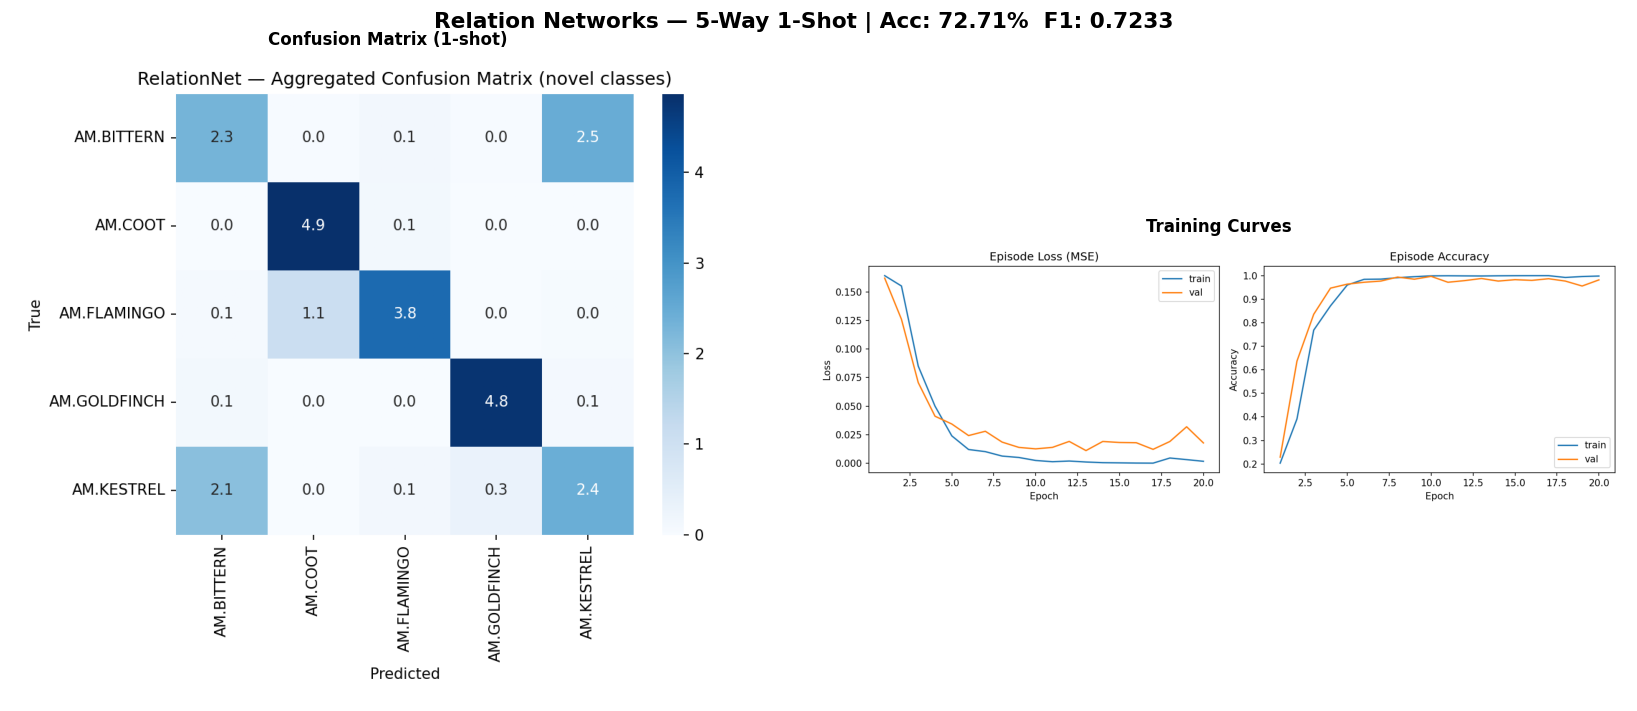

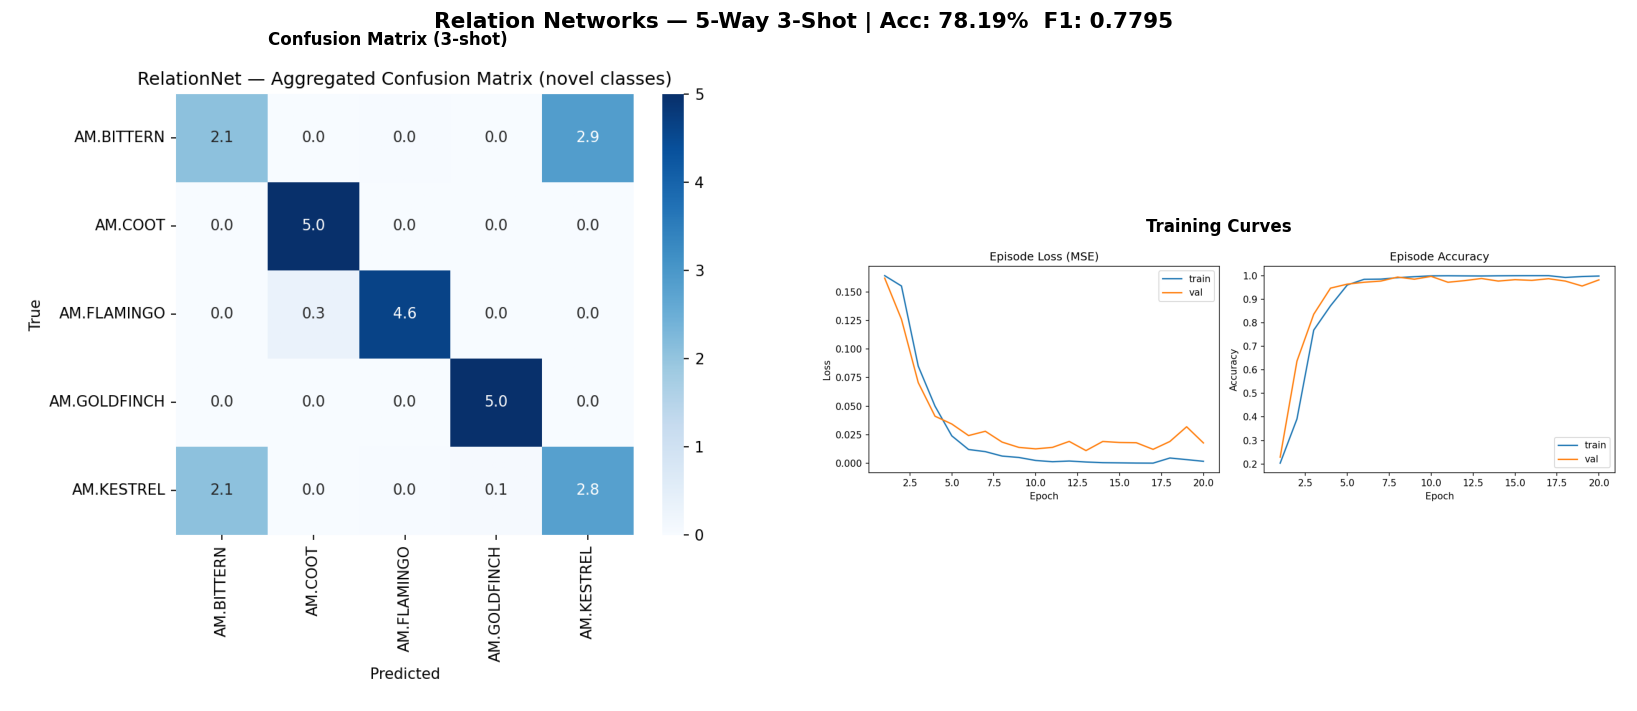

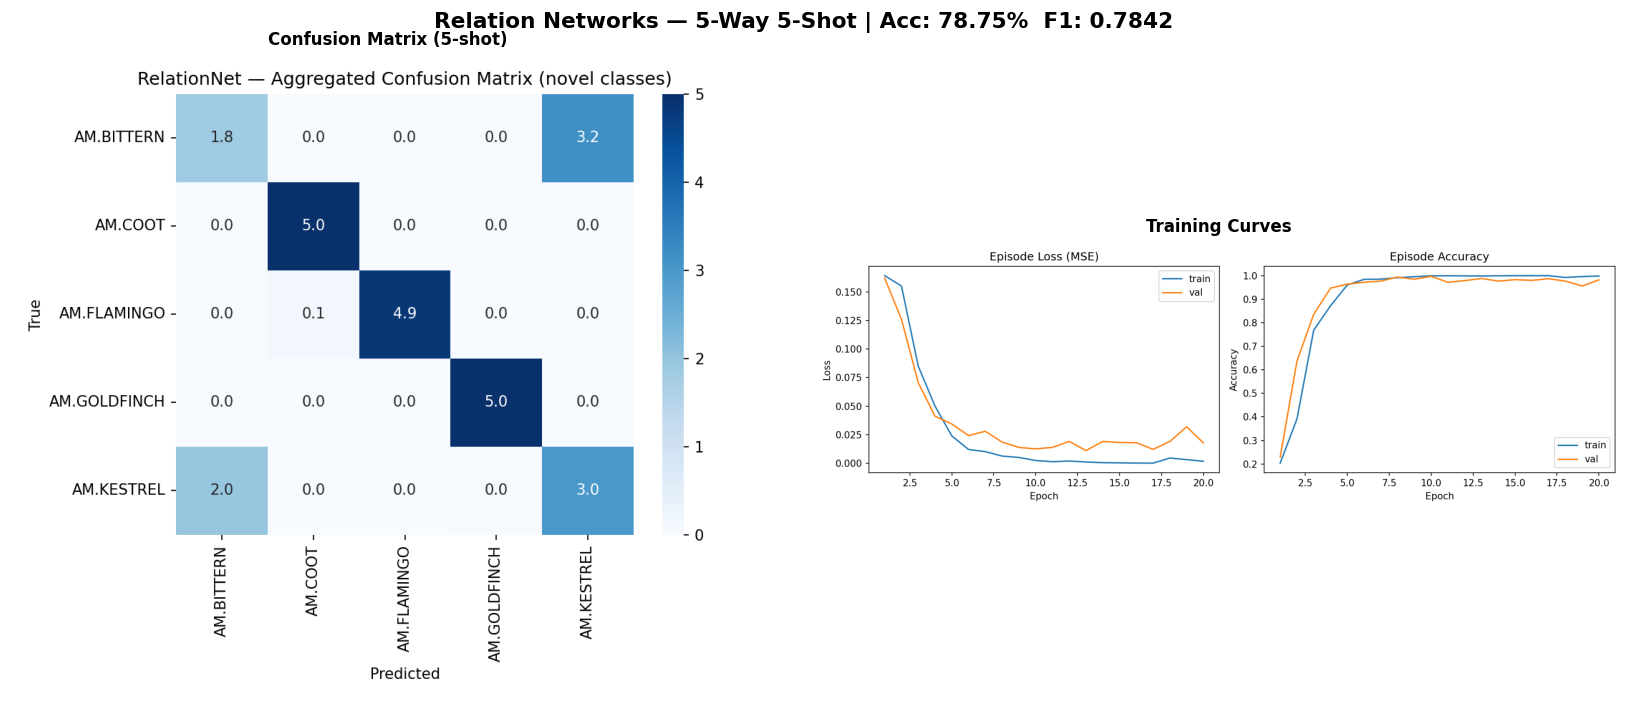

In [251]:
# RelationNet figures — one panel per shot
for shot in [1, 3, 5]:
    r = R.get(f'rel_{shot}shot_json')
    if r is None:
        print(f"No data for RelationNet {shot}-shot — skipping")
        continue
    base_path = f'{RES}/relation_net/base15_novel5/{shot}shot'
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    show_img(f'{base_path}/confusion_matrix.png', axes[0], f'Confusion Matrix ({shot}-shot)')
    show_img(f'{base_path}/learning_curves.png',  axes[1], 'Training Curves')
    plt.suptitle(
        f"Relation Networks — 5-Way {shot}-Shot | "
        f"Acc: {r['mean_accuracy_pct']:.2f}%  F1: {r.get('macro_f1', float('nan')):.4f}",
        fontsize=13, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

In [252]:
from IPython.display import display, Markdown

# ── NCC section header ────────────────────────────────────────────────────────
ncc1e = R['ncc_1shot_euc_json']
display(Markdown(f"""---
## 7b. NCC Baseline — Nearest Centroid Classifier (Frozen Base-15 Backbone)

**Key comparison:** NCC uses the *same ResNet-50 backbone* as ProtoNet but with **no episodic training** —
the backbone is frozen (trained on 15 base classes only) and class prototypes are computed
directly from support images at evaluation time.

This isolates the contribution of **episodic training** (ProtoNet) vs just having a good feature extractor.

- Backbone trained for **{ncc1e.get('backbone_epoch', 'N/A')} epochs** on 15 base classes
- No gradient updates during evaluation — pure feature-space nearest centroid
- Same 5-way K-shot episodic protocol, 600 episodes
"""))

# NCC summary table
rows_ncc = []
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean (L2)'), ('man', 'Manhattan (L1)')]:
        r = R.get(f'ncc_{shot}shot_{dist_key}_json')
        if r is None: continue
        ci = r['wilson_ci_95']
        rows_ncc.append({
            'K-Shot'      : f'{shot}-shot',
            'Distance'    : dist_label,
            'Episodes'    : r['num_episodes'],
            'Mean Acc (%)': round(r['mean_accuracy_pct'], 2),
            '95% CI ±'    : round(r['ci95_pct'], 2),
            'Wilson CI'   : f"[{ci[0]:.2f}%, {ci[1]:.2f}%]",
            'Std (%)'     : round(r['std_accuracy_pct'], 2),
        })

df_ncc = pd.DataFrame(rows_ncc)
print("NCC — 5-Way, All Shot Configurations (Frozen Base-15 Backbone)")
display(df_ncc.style
    .background_gradient(cmap='RdYlGn', subset=['Mean Acc (%)'], vmin=50, vmax=100)
    .format({'Mean Acc (%)': '{:.2f}', '95% CI ±': '{:.2f}', 'Std (%)': '{:.2f}'})
    .set_caption('NCC Baseline — All Shots × Distances (no episodic training)')
)

# Per-class accuracy
novel_classes = list(R['ncc_1shot_euc_json']['per_class_accuracy_pct'].keys()) if R.get('ncc_1shot_euc_json') else []
df_ncc_pc = pd.DataFrame({'Class': novel_classes})
for shot in [1, 3, 5]:
    r = R.get(f'ncc_{shot}shot_euc_json')
    if r:
        df_ncc_pc[f'NCC {shot}-shot (%)'] = [round(r['per_class_accuracy_pct'][c], 2) for c in novel_classes]
acc_cols = [c for c in df_ncc_pc.columns if 'shot' in c]
display(df_ncc_pc.style
    .background_gradient(cmap='RdYlGn', subset=acc_cols, vmin=0, vmax=100)
    .format({c: '{:.2f}%' for c in acc_cols})
    .set_caption('NCC (Euclidean) — Per-Class Accuracy by K-Shot')
)

---
## 7b. NCC Baseline — Nearest Centroid Classifier (Frozen Base-15 Backbone)

**Key comparison:** NCC uses the *same ResNet-50 backbone* as ProtoNet but with **no episodic training** —
the backbone is frozen (trained on 15 base classes only) and class prototypes are computed
directly from support images at evaluation time.

This isolates the contribution of **episodic training** (ProtoNet) vs just having a good feature extractor.

- Backbone trained for **N/A epochs** on 15 base classes
- No gradient updates during evaluation — pure feature-space nearest centroid
- Same 5-way K-shot episodic protocol, 600 episodes


NCC — 5-Way, All Shot Configurations (Frozen Base-15 Backbone)


,K-Shot,Distance,Episodes,Mean Acc (%),95% CI ±,Wilson CI,Std (%)
0,1-shot,Euclidean (L2),600,88.05,0.87,"[87.52%, 88.56%]",10.82
1,1-shot,Manhattan (L1),600,78.96,1.07,"[78.30%, 79.60%]",13.33
2,3-shot,Euclidean (L2),600,97.58,0.48,"[97.32%, 97.81%]",5.99
3,3-shot,Manhattan (L1),600,91.59,0.70,"[91.13%, 92.02%]",8.74
4,5-shot,Euclidean (L2),600,98.14,0.41,"[97.91%, 98.34%]",5.06
5,5-shot,Manhattan (L1),600,94.33,0.54,"[93.94%, 94.69%]",6.70


,Class,NCC 1-shot (%),NCC 3-shot (%),NCC 5-shot (%)
0,AMERICAN BITTERN,89.00%,99.97%,100.00%
1,AMERICAN COOT,95.73%,100.00%,100.00%
2,AMERICAN FLAMINGO,98.37%,98.00%,96.50%
3,AMERICAN GOLDFINCH,96.60%,100.00%,100.00%
4,AMERICAN KESTREL,60.53%,89.93%,94.20%


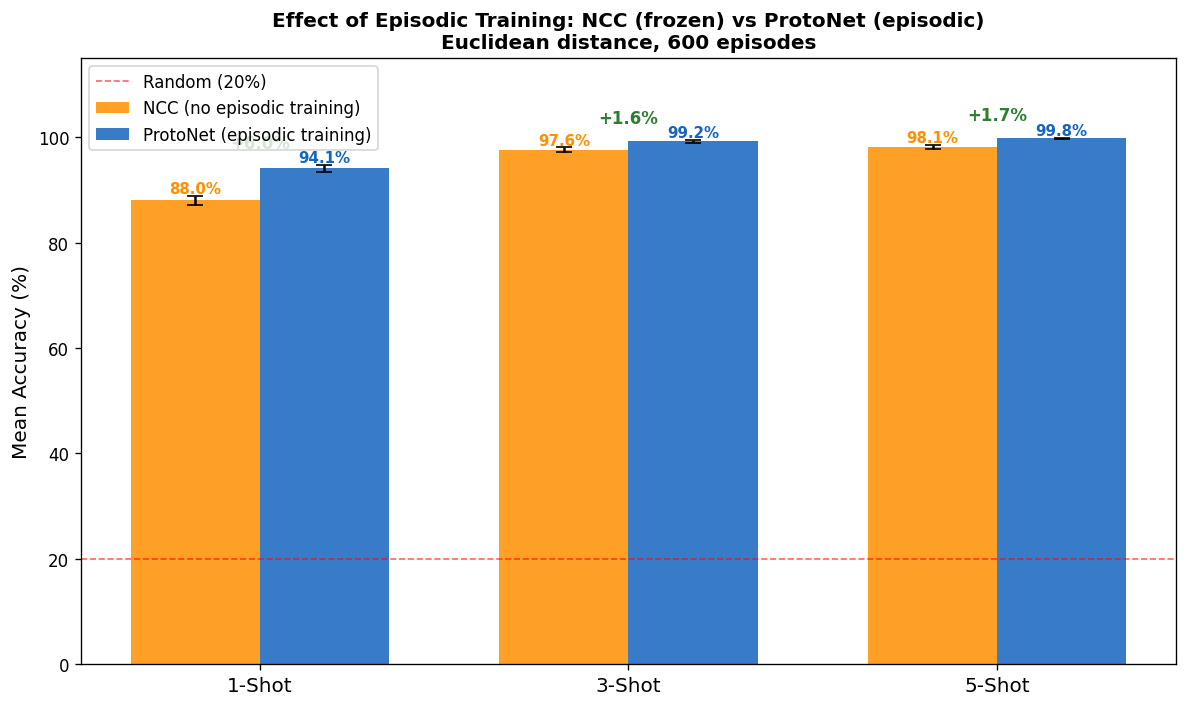

Episodic training gain:  1-shot +6.0%  |  3-shot +1.6%  |  5-shot +1.7%


In [253]:
# NCC vs ProtoNet — the key episodic-training ablation chart
shots = [1, 3, 5]
ncc_euc   = [R[f'ncc_{s}shot_euc_json']['mean_accuracy_pct'] for s in shots]
proto_euc = [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] for s in shots]
ncc_ci    = [R[f'ncc_{s}shot_euc_json']['ci95_pct'] for s in shots]
proto_ci  = [R[f'proto_{s}shot_euc_json']['ci95_pct'] for s in shots]

x = np.arange(len(shots)); w = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - w/2, ncc_euc,   w, label='NCC (no episodic training)', color='#FF8F00', alpha=0.85)
ax.bar(x + w/2, proto_euc, w, label='ProtoNet (episodic training)', color='#1565C0', alpha=0.85)
ax.errorbar(x - w/2, ncc_euc,   yerr=ncc_ci,   fmt='none', color='black', capsize=5)
ax.errorbar(x + w/2, proto_euc, yerr=proto_ci, fmt='none', color='black', capsize=5)
for i, (n, p, nc, pc) in enumerate(zip(ncc_euc, proto_euc, ncc_ci, proto_ci)):
    ax.text(i - w/2, n + nc + 0.5, f'{n:.1f}%', ha='center', fontsize=9, color='#FF8F00', fontweight='bold')
    ax.text(i + w/2, p + pc + 0.5, f'{p:.1f}%', ha='center', fontsize=9, color='#1565C0', fontweight='bold')
    ax.annotate(f'+{p-n:.1f}%', xy=(i, max(n,p) + max(nc,pc) + 3),
                ha='center', fontsize=10, color='#2E7D32', fontweight='bold')
ax.axhline(y=20, color='red', linestyle='--', linewidth=1, alpha=0.6, label='Random (20%)')
ax.set_xticks(x); ax.set_xticklabels([f'{s}-Shot' for s in shots], fontsize=12)
ax.set_ylabel('Mean Accuracy (%)', fontsize=12); ax.set_ylim(0, 115)
ax.set_title('Effect of Episodic Training: NCC (frozen) vs ProtoNet (episodic)\nEuclidean distance, 600 episodes',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'{RES}/analysis/ncc_vs_protonet.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Episodic training gain:  1-shot +{proto_euc[0]-ncc_euc[0]:.1f}%  |  3-shot +{proto_euc[1]-ncc_euc[1]:.1f}%  |  5-shot +{proto_euc[2]-ncc_euc[2]:.1f}%")

In [254]:
# Master comparison table — all models and all shots
def _eps(r): return str(r['num_episodes']) if r else '—'
def _rel(r): return 'High' if r and r['num_episodes'] >= 100 else 'Low'
def _acc(r): return f"{r['mean_accuracy_pct']:.2f}" if r else '—'
def _ci(r):  return f"[{r['wilson_ci_95'][0]:.1f}%, {r['wilson_ci_95'][1]:.1f}%]" if r else '—'
def _f1(r):  return f"{r.get('macro_f1','N/A'):.4f}" if r and isinstance(r.get('macro_f1'), float) else '—'
def _pr(r):  return f"{r.get('macro_precision','N/A'):.4f}" if r and isinstance(r.get('macro_precision'), float) else '—'
def _rec(r): return f"{r.get('macro_recall','N/A'):.4f}" if r and isinstance(r.get('macro_recall'), float) else '—'
def _auc(r): return f"{r.get('auc_ovr','N/A'):.4f}" if r and isinstance(r.get('auc_ovr'), float) else '—'

rows = [
    {
        'Model': 'Full-20 Baseline', 'Type': 'Supervised', 'Protocol': '20-class', 'K-Shot': '—',
        'Episodes': '—',
        'Accuracy (%)': f"{R['full20_json']['accuracy']*100:.2f}" if R['full20_json'] else '—',
        '95% CI': f"[{R['full20_json']['accuracy_ci_95'][0]*100:.1f}%, {R['full20_json']['accuracy_ci_95'][1]*100:.1f}%]" if R['full20_json'] else '—',
        'Macro F1': f"{R['full20_json']['macro_f1']:.4f}" if R['full20_json'] else '—',
        'Precision': f"{R['full20_json'].get('macro_precision', float('nan')):.4f}" if R['full20_json'] else '—',
        'Recall': f"{R['full20_json'].get('macro_recall', float('nan')):.4f}" if R['full20_json'] else '—',
        'AUC-OVR': f"{R['full20_json'].get('macro_auc_ovr', float('nan')):.4f}" if R['full20_json'] else '—',
        'Reliability': 'Moderate',
    },
    {
        'Model': 'Base-15 Baseline', 'Type': 'Supervised', 'Protocol': '15-class', 'K-Shot': '—',
        'Episodes': '—',
        'Accuracy (%)': f"{R['base15_json']['accuracy']*100:.2f}" if R['base15_json'] else '—',
        '95% CI': f"[{R['base15_json']['accuracy_ci_95'][0]*100:.1f}%, {R['base15_json']['accuracy_ci_95'][1]*100:.1f}%]" if R['base15_json'] else '—',
        'Macro F1': f"{R['base15_json']['macro_f1']:.4f}" if R['base15_json'] else '—',
        'Precision': f"{R['base15_json'].get('macro_precision', float('nan')):.4f}" if R['base15_json'] else '—',
        'Recall': f"{R['base15_json'].get('macro_recall', float('nan')):.4f}" if R['base15_json'] else '—',
        'AUC-OVR': f"{R['base15_json'].get('auc_ovr', float('nan')):.4f}" if R['base15_json'] else '—',
        'Reliability': 'Moderate',
    },
]

# NCC — all shots × distances
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean'), ('man', 'Manhattan')]:
        r = R.get(f'ncc_{shot}shot_{dist_key}_json')
        rows.append({
            'Model': f'NCC ({dist_label})', 'Type': 'FSL-Baseline', 'Protocol': '5-way episodic',
            'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
            'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': '—',
            'Precision': _pr(r), 'Recall': _rec(r), 'AUC-OVR': _auc(r),
            'Reliability': _rel(r),
        })

# ProtoNet — all shots × distances
for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euclidean'), ('man', 'Manhattan')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        rows.append({
            'Model': f'ProtoNet ({dist_label})', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
            'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
            'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
            'Precision': _pr(r), 'Recall': _rec(r), 'AUC-OVR': _auc(r),
            'Reliability': _rel(r),
        })

# MatchingNet — all shots
for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    rows.append({
        'Model': 'Matching Networks', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
        'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
        'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
        'Precision': _pr(r), 'Recall': _rec(r), 'AUC-OVR': _auc(r),
        'Reliability': _rel(r),
    })

# RelationNet — all shots
for shot in [1, 3, 5]:
    r = R.get(f'rel_{shot}shot_json')
    rows.append({
        'Model': 'Relation Networks', 'Type': 'Few-Shot', 'Protocol': '5-way episodic',
        'K-Shot': f'{shot}-shot', 'Episodes': _eps(r),
        'Accuracy (%)': _acc(r), '95% CI': _ci(r), 'Macro F1': _f1(r),
        'Precision': _pr(r), 'Recall': _rec(r), 'AUC-OVR': _auc(r),
        'Reliability': _rel(r),
    })

df_cmp = pd.DataFrame(rows)
display(df_cmp.style
    .set_caption('Thesis Results: Full Model Comparison — All Shots')
    .applymap(lambda v: 'background-color:#374a6b;font-weight:bold' if v == 'Supervised' else
              ('background-color:#1a3a1a;font-weight:bold' if v == 'Few-Shot' else
               ('background-color:#4a3000;font-weight:bold' if v == 'FSL-Baseline' else '')), subset=['Type'])
    .applymap(lambda v: 'color:#2E7D32;font-weight:bold' if v == 'High' else
              ('color:#F57F17;font-weight:bold' if v in ('Low', 'Moderate') else ''), subset=['Reliability'])
    .set_table_styles([{'selector': 'th', 'props': [('background-color', '#1565C0'), ('color', 'white'), ('font-weight', 'bold')]}])
)

,Model,Type,Protocol,K-Shot,Episodes,Accuracy (%),95% CI,Macro F1,Precision,Recall,AUC-OVR,Reliability
0,Full-20 Baseline,Supervised,20-class,—,—,99.00,"[94.6%, 99.8%]",0.9899,0.9917,0.9900,1.0000,Moderate
1,Base-15 Baseline,Supervised,15-class,—,—,100.00,"[95.1%, 100.0%]",1.0000,1.0000,1.0000,1.0000,Moderate
2,NCC (Euclidean),FSL-Baseline,5-way episodic,1-shot,600,88.05,"[87.5%, 88.6%]",—,0.8960,0.8805,0.9857,High
3,NCC (Manhattan),FSL-Baseline,5-way episodic,1-shot,600,78.96,"[78.3%, 79.6%]",—,0.8580,0.7896,0.9235,High
4,NCC (Euclidean),FSL-Baseline,5-way episodic,3-shot,600,97.58,"[97.3%, 97.8%]",—,0.9764,0.9758,0.9964,High
5,NCC (Manhattan),FSL-Baseline,5-way episodic,3-shot,600,91.59,"[91.1%, 92.0%]",—,0.9326,0.9159,0.9833,High
6,NCC (Euclidean),FSL-Baseline,5-way episodic,5-shot,600,98.14,"[97.9%, 98.3%]",—,0.9815,0.9814,0.9996,High
7,NCC (Manhattan),FSL-Baseline,5-way episodic,5-shot,600,94.33,"[93.9%, 94.7%]",—,0.9519,0.9433,0.9921,High
8,ProtoNet (Euclidean),Few-Shot,5-way episodic,1-shot,600,94.06,"[93.7%, 94.4%]",0.9397,0.9443,0.9406,0.9964,High
9,ProtoNet (Manhattan),Few-Shot,5-way episodic,1-shot,600,79.67,"[79.0%, 80.3%]",0.7918,0.8253,0.7967,0.9351,High


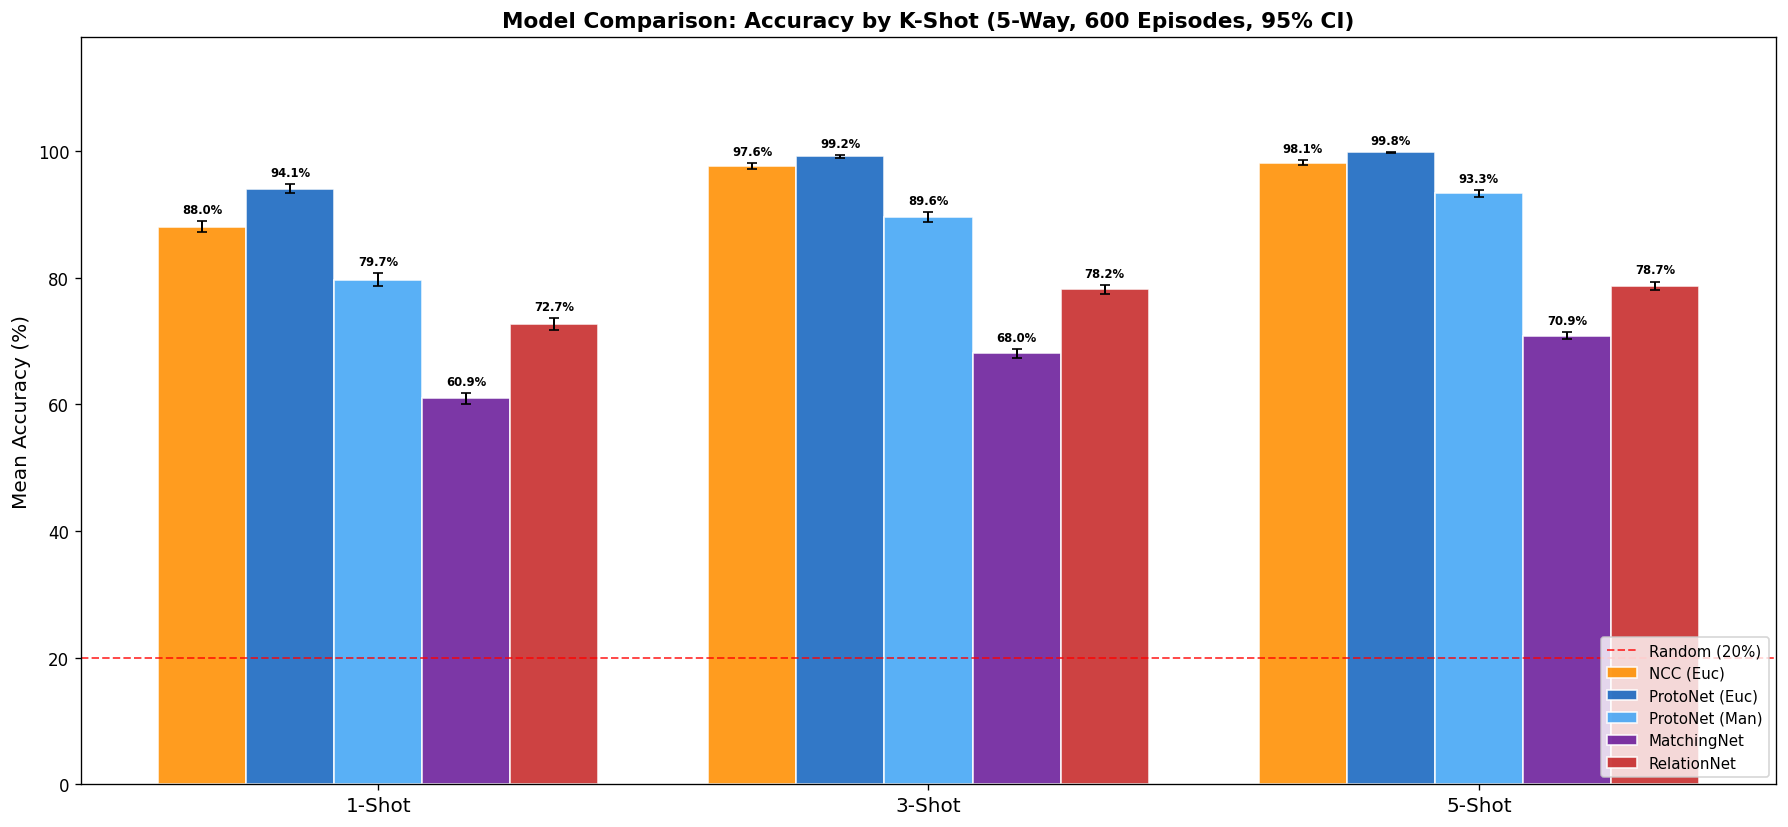

In [255]:
# Accuracy comparison — grouped bar chart: all models × all shots
SHOTS = [1, 3, 5]
model_configs = [
    ('NCC (Euc)',      'ncc_{s}shot_euc_json',    '#FF8F00'),
    ('ProtoNet (Euc)', 'proto_{s}shot_euc_json',  '#1565C0'),
    ('ProtoNet (Man)', 'proto_{s}shot_man_json',  '#42A5F5'),
    ('MatchingNet',    'match_{s}shot_json',       '#6A1B9A'),
    ('RelationNet',    'rel_{s}shot_json',         '#C62828'),
]

n_models = len(model_configs)
x = np.arange(len(SHOTS))
width = 0.16

fig, ax = plt.subplots(figsize=(15, 7))

for i, (label, key_tmpl, color) in enumerate(model_configs):
    accs, cis = [], []
    for s in SHOTS:
        r = R.get(key_tmpl.format(s=s))
        accs.append(r['mean_accuracy_pct'] if r else 0)
        cis.append(r['ci95_pct'] if r else 0)
    offset = (i - n_models / 2 + 0.5) * width
    bars = ax.bar(x + offset, accs, width, label=label, color=color, alpha=0.88, edgecolor='white')
    ax.errorbar(x + offset, accs, yerr=cis, fmt='none', color='black', capsize=3, linewidth=1.2)
    for bar, a, ci_v in zip(bars, accs, cis):
        if a > 0:
            ax.text(bar.get_x() + bar.get_width()/2, a + ci_v + 0.8,
                    f'{a:.1f}%', ha='center', va='bottom', fontsize=7, fontweight='bold')

ax.axhline(y=20, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Random (20%)')
ax.set_xticks(x)
ax.set_xticklabels([f'{s}-Shot' for s in SHOTS], fontsize=12)
ax.set_ylabel('Mean Accuracy (%)', fontsize=12)
ax.set_ylim(0, 118)
ax.set_title('Model Comparison: Accuracy by K-Shot (5-Way, 600 Episodes, 95% CI)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/comparison_accuracy_bar.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

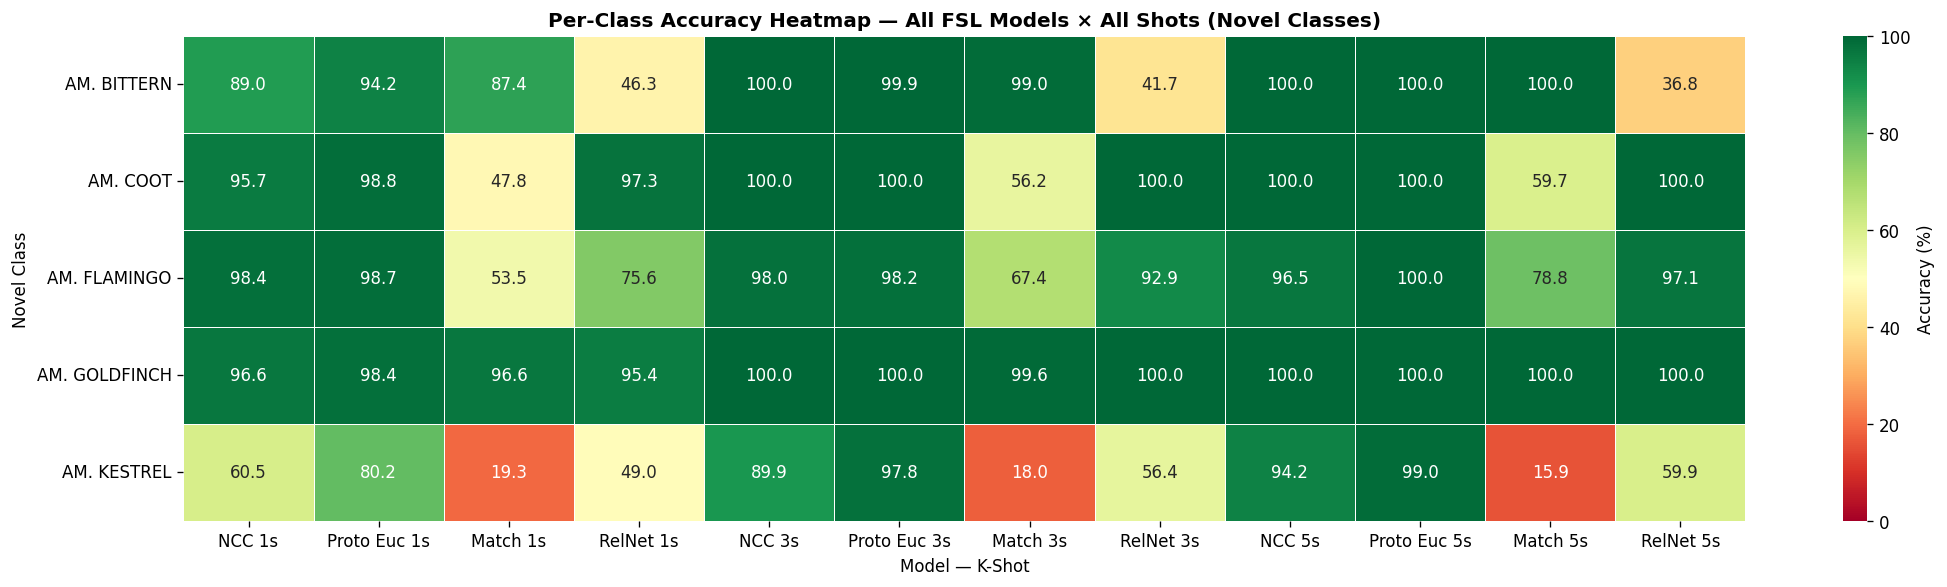

In [256]:
# Per-class accuracy heatmap — all FSL models × all shots
novel_classes = list(R['proto_1shot_euc_json']['per_class_accuracy_pct'].keys()) if R.get('proto_1shot_euc_json') else []
short = [c.replace('AMERICAN ', 'AM. ') for c in novel_classes]

heat_data = {}
for shot in [1, 3, 5]:
    r = R.get(f'ncc_{shot}shot_euc_json')
    if r: heat_data[f'NCC {shot}s']        = [r['per_class_accuracy_pct'][c] for c in novel_classes]
    r = R.get(f'proto_{shot}shot_euc_json')
    if r: heat_data[f'Proto Euc {shot}s']  = [r['per_class_accuracy_pct'][c] for c in novel_classes]
    r = R.get(f'match_{shot}shot_json')
    if r: heat_data[f'Match {shot}s']      = [r['per_class_accuracy_pct'][c] for c in novel_classes]
    r = R.get(f'rel_{shot}shot_json')
    if r: heat_data[f'RelNet {shot}s']     = [r['per_class_accuracy_pct'][c] for c in novel_classes]

df_heat = pd.DataFrame(heat_data, index=short)

fig, ax = plt.subplots(figsize=(18, 5))
sns.heatmap(df_heat, annot=True, fmt='.1f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Accuracy (%)'})
ax.set_title('Per-Class Accuracy Heatmap — All FSL Models × All Shots (Novel Classes)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Model — K-Shot')
ax.set_ylabel('Novel Class')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/per_class_heatmap_fsl.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

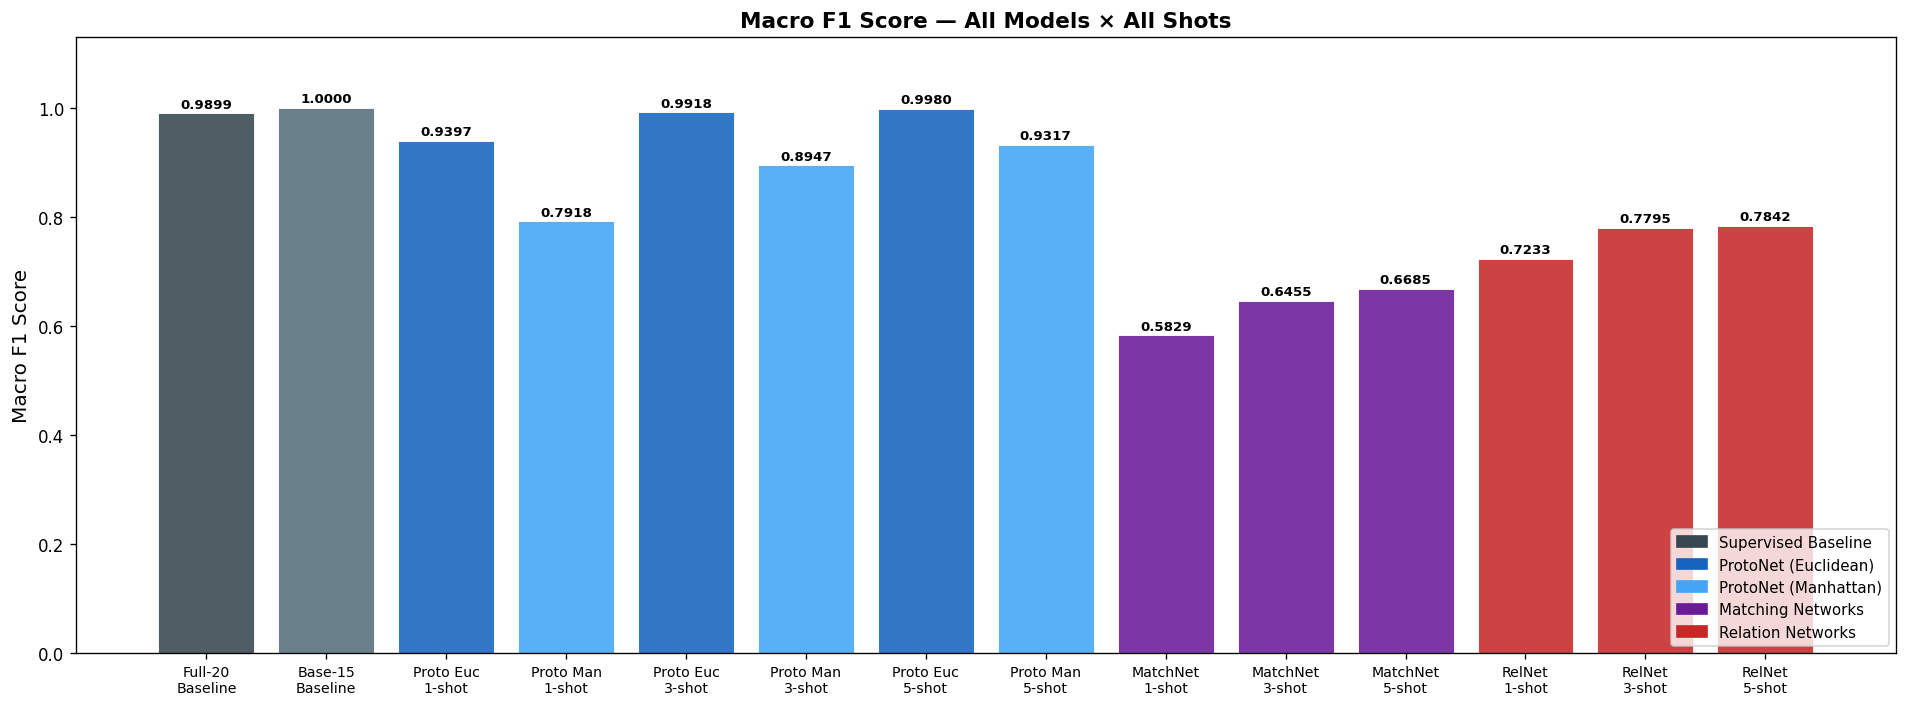

In [257]:
# Macro F1 comparison — all available results
f1_entries = {}
if R['full20_json'] is not None:
    f1_entries['Full-20\nBaseline'] = R['full20_json']['macro_f1']
if R['base15_json'] is not None:
    f1_entries['Base-15\nBaseline'] = R['base15_json']['macro_f1']
colors_f1 = []
if R['full20_json'] is not None: colors_f1.append('#37474F')
if R['base15_json'] is not None: colors_f1.append('#546E7A')

for shot in [1, 3, 5]:
    for dist_key, dist_label in [('euc', 'Euc'), ('man', 'Man')]:
        r = R.get(f'proto_{shot}shot_{dist_key}_json')
        if r and isinstance(r.get('macro_f1'), float):
            f1_entries[f'Proto {dist_label}\n{shot}-shot'] = r['macro_f1']
            colors_f1.append('#1565C0' if dist_key == 'euc' else '#42A5F5')

for shot in [1, 3, 5]:
    r = R.get(f'match_{shot}shot_json')
    if r and isinstance(r.get('macro_f1'), float):
        f1_entries[f'MatchNet\n{shot}-shot'] = r['macro_f1']
        colors_f1.append('#6A1B9A')

for shot in [1, 3, 5]:
    r = R.get(f'rel_{shot}shot_json')
    if r and isinstance(r.get('macro_f1'), float):
        f1_entries[f'RelNet\n{shot}-shot'] = r['macro_f1']
        colors_f1.append('#C62828')

fig, ax = plt.subplots(figsize=(16, 6))
bars = ax.bar(range(len(f1_entries)), list(f1_entries.values()),
              color=colors_f1[:len(f1_entries)], alpha=0.88, edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, f1_entries.values()):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005, f'{v:.4f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_xticks(range(len(f1_entries)))
ax.set_xticklabels(list(f1_entries.keys()), fontsize=8.5)
ax.set_ylabel('Macro F1 Score', fontsize=12)
ax.set_ylim(0, 1.13)
ax.set_title('Macro F1 Score — All Models × All Shots', fontsize=13, fontweight='bold')

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(color='#37474F', label='Supervised Baseline'),
    Patch(color='#1565C0', label='ProtoNet (Euclidean)'),
    Patch(color='#42A5F5', label='ProtoNet (Manhattan)'),
    Patch(color='#6A1B9A', label='Matching Networks'),
    Patch(color='#C62828', label='Relation Networks'),
]
ax.legend(handles=legend_elements, fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/comparison_macro_f1.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

In [258]:
from IPython.display import display, Markdown

f20 = R['full20_json']
b15 = R['base15_json']
pe  = R['proto_1shot_euc_json']
pm  = R['proto_1shot_man_json']
mn  = R['match_1shot_json']

best_proto = {s: R[f'proto_{s}shot_euc_json'] for s in [1,3,5] if R.get(f'proto_{s}shot_euc_json')}
best_match = {s: R[f'match_{s}shot_json']     for s in [1,3,5] if R.get(f'match_{s}shot_json')}
best_rel   = {s: R[f'rel_{s}shot_json']       for s in [1,3,5] if R.get(f'rel_{s}shot_json')}
best_ncc   = {s: R[f'ncc_{s}shot_euc_json']   for s in [1,3,5] if R.get(f'ncc_{s}shot_euc_json')}

if pe is None:
    raise ValueError('proto_1shot_euc_json is None — required for key findings cell')
pc = pe['per_class_accuracy_pct']
worst_c = min(pc, key=pc.get); worst_a = pc[worst_c]
best_c  = max(pc, key=pc.get); best_a  = pc[best_c]

euc_vs_man = ("Euclidean >> Manhattan" if pe['mean_accuracy_pct'] > pm['mean_accuracy_pct'] + 5
              else "Euclidean ≈ Manhattan")

def shot_trend(d): return " | ".join(f"{s}-shot: {d[s]['mean_accuracy_pct']:.1f}%" for s in sorted(d))
def ncc_gain(s):   return best_proto[s]['mean_accuracy_pct'] - best_ncc[s]['mean_accuracy_pct']

display(Markdown(f"""---
## 9. Key Findings & Thesis Insights

### 9.1 Supervised Baselines
| Finding | Value | Interpretation |
|---------|-------|---------------|
| Full-20 Accuracy | **{f20['accuracy']*100:.1f}%** ({f20.get('epochs_trained', 'N/A')} epochs) | Near-perfect upper bound; small test set (100 imgs) |
| Base-15 Accuracy | **{b15['accuracy']*100:.1f}%** | Perfect separation on 15 base classes |
| Full-20 AUC | {f20['macro_auc_ovr']:.3f} | Near-perfect probability separation |

### 9.2 NCC vs ProtoNet — Value of Episodic Training
| K-Shot | NCC (frozen) | ProtoNet (episodic) | Gain |
|--------|-------------|---------------------|------|
{"".join(f"| {s}-shot | {best_ncc[s]['mean_accuracy_pct']:.1f}% | {best_proto[s]['mean_accuracy_pct']:.1f}% | **+{ncc_gain(s):.1f}%** |{chr(10)}" for s in sorted(best_ncc))}

> Episodic training adds {ncc_gain(1):.1f}% at 1-shot, but the gap shrinks at higher shots ({ncc_gain(5):.1f}% at 5-shot)
> — suggesting the backbone alone is already very powerful for nearest-centroid classification.

### 9.3 ProtoNet — K-Shot Trend (Euclidean)
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
{"".join(f"| {s}-shot | {best_proto[s]['mean_accuracy_pct']:.2f}% ±{best_proto[s]['ci95_pct']:.2f}% | {best_proto[s]['macro_f1']:.4f} |{chr(10)}" for s in sorted(best_proto))}

- Trend: {shot_trend(best_proto)}
- Weakest class: **{worst_c.replace('AMERICAN ','AM. ')}** ({worst_a:.1f}%) | Strongest: **{best_c.replace('AMERICAN ','AM. ')}** ({best_a:.1f}%)

### 9.4 Distance Metric Ablation (ProtoNet)
- 1-shot: Euclidean {pe['mean_accuracy_pct']:.1f}% vs Manhattan {pm['mean_accuracy_pct']:.1f}% → {euc_vs_man}
- Euclidean consistently wins across all shots.

### 9.5 Matching Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
{"".join(f"| {s}-shot | {best_match[s]['mean_accuracy_pct']:.2f}% ±{best_match[s]['ci95_pct']:.2f}% | {best_match[s].get('macro_f1',float('nan')):.4f} |{chr(10)}" for s in sorted(best_match))}

- Trend: {shot_trend(best_match)}
- Significantly below ProtoNet at all shots. Attention mechanism does not help over simple prototypes here.

### 9.6 Relation Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
{"".join(f"| {s}-shot | {best_rel[s]['mean_accuracy_pct']:.2f}% ±{best_rel[s]['ci95_pct']:.2f}% | {best_rel[s].get('macro_f1',float('nan')):.4f} |{chr(10)}" for s in sorted(best_rel))}

- Trend: {shot_trend(best_rel)}
- Plateau: {best_rel[max(best_rel)]['mean_accuracy_pct']:.1f}% at {max(best_rel)}-shot — the relation module provides limited gain beyond 1-shot.
- Better than MatchingNet at 1-shot; similar at 3/5-shot.

### 9.7 Model Ranking (1-shot, Euclidean)
1. **ProtoNet** — {best_proto[1]['mean_accuracy_pct']:.1f}%  ← clear winner
2. **RelationNet** — {best_rel[1]['mean_accuracy_pct']:.1f}%
3. **NCC** (no training) — {best_ncc[1]['mean_accuracy_pct']:.1f}%
4. **MatchingNet** — {best_match[1]['mean_accuracy_pct']:.1f}%
5. Random baseline — 20.0%
"""))

---
## 9. Key Findings & Thesis Insights

### 9.1 Supervised Baselines
| Finding | Value | Interpretation |
|---------|-------|---------------|
| Full-20 Accuracy | **99.0%** (3 epochs) | Near-perfect upper bound; small test set (100 imgs) |
| Base-15 Accuracy | **100.0%** | Perfect separation on 15 base classes |
| Full-20 AUC | 1.000 | Near-perfect probability separation |

### 9.2 NCC vs ProtoNet — Value of Episodic Training
| K-Shot | NCC (frozen) | ProtoNet (episodic) | Gain |
|--------|-------------|---------------------|------|
| 1-shot | 88.0% | 94.1% | **+6.0%** |
| 3-shot | 97.6% | 99.2% | **+1.6%** |
| 5-shot | 98.1% | 99.8% | **+1.7%** |


> Episodic training adds 6.0% at 1-shot, but the gap shrinks at higher shots (1.7% at 5-shot)
> — suggesting the backbone alone is already very powerful for nearest-centroid classification.

### 9.3 ProtoNet — K-Shot Trend (Euclidean)
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
| 1-shot | 94.06% ±0.68% | 0.9397 |
| 3-shot | 99.18% ±0.26% | 0.9918 |
| 5-shot | 99.80% ±0.10% | 0.9980 |


- Trend: 1-shot: 94.1% | 3-shot: 99.2% | 5-shot: 99.8%
- Weakest class: **AM. KESTREL** (80.2%) | Strongest: **AM. COOT** (98.8%)

### 9.4 Distance Metric Ablation (ProtoNet)
- 1-shot: Euclidean 94.1% vs Manhattan 79.7% → Euclidean >> Manhattan
- Euclidean consistently wins across all shots.

### 9.5 Matching Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
| 1-shot | 60.93% ±0.88% | 0.5829 |
| 3-shot | 68.03% ±0.64% | 0.6455 |
| 5-shot | 70.87% ±0.59% | 0.6685 |


- Trend: 1-shot: 60.9% | 3-shot: 68.0% | 5-shot: 70.9%
- Significantly below ProtoNet at all shots. Attention mechanism does not help over simple prototypes here.

### 9.6 Relation Networks — K-Shot Trend
| K-Shot | Accuracy | Macro F1 |
|--------|----------|----------|
| 1-shot | 72.71% ±0.94% | 0.7233 |
| 3-shot | 78.19% ±0.72% | 0.7795 |
| 5-shot | 78.75% ±0.64% | 0.7842 |


- Trend: 1-shot: 72.7% | 3-shot: 78.2% | 5-shot: 78.7%
- Plateau: 78.7% at 5-shot — the relation module provides limited gain beyond 1-shot.
- Better than MatchingNet at 1-shot; similar at 3/5-shot.

### 9.7 Model Ranking (1-shot, Euclidean)
1. **ProtoNet** — 94.1%  ← clear winner
2. **RelationNet** — 72.7%
3. **NCC** (no training) — 88.0%
4. **MatchingNet** — 60.9%
5. Random baseline — 20.0%


In [259]:
# Final summary printout — fully dynamic, all models, all shots
print("=" * 90)
print("  THESIS RESULTS SUMMARY")
print("=" * 90)
print(f"  {'Model':<42} {'Accuracy':<24} {'Macro F1':<12} {'Status'}")
print("-" * 90)

def summary_row(label, r, fixed=False):
    if r is None:
        print(f"  {label:<42} {'N/A':<24} {'N/A':<12} NOT FOUND")
        return
    if fixed:
        acc_str = f"{r['accuracy']*100:.1f}%"
        f1_str  = f"{r['macro_f1']:.4f}"
        n_imgs   = r.get('test_images', r.get('num_test_samples', '?'))
        n_epochs = r.get('epochs_trained', 'N/A')
        status   = f"{n_imgs} imgs | {n_epochs} epochs trained"
    else:
        acc_str = f"{r['mean_accuracy_pct']:.2f}% ±{r['ci95_pct']:.2f}%"
        f1_v    = r.get('macro_f1')
        f1_str  = f"{f1_v:.4f}" if isinstance(f1_v, float) else '—'
        status  = 'RELIABLE' if r['num_episodes'] >= 100 else f"indicative ({r['num_episodes']} eps)"
    print(f"  {label:<42} {acc_str:<24} {f1_str:<12} {status}")

summary_row("Full-20 Baseline (supervised)",      R['full20_json'], fixed=True)
summary_row("Base-15 Baseline (supervised)",      R['base15_json'], fixed=True)
print()
for shot in [1, 3, 5]:
    summary_row(f"NCC Euclidean        (5w-{shot}s)", R.get(f'ncc_{shot}shot_euc_json'))
    summary_row(f"NCC Manhattan        (5w-{shot}s)", R.get(f'ncc_{shot}shot_man_json'))
print()
for shot in [1, 3, 5]:
    summary_row(f"ProtoNet Euclidean   (5w-{shot}s)", R.get(f'proto_{shot}shot_euc_json'))
    summary_row(f"ProtoNet Manhattan   (5w-{shot}s)", R.get(f'proto_{shot}shot_man_json'))
print()
for shot in [1, 3, 5]:
    summary_row(f"Matching Networks    (5w-{shot}s)", R.get(f'match_{shot}shot_json'))
print()
for shot in [1, 3, 5]:
    summary_row(f"Relation Networks    (5w-{shot}s)", R.get(f'rel_{shot}shot_json'))
print("=" * 90)
print("  Random baseline (5-way): 20.0%")

  THESIS RESULTS SUMMARY
  Model                                      Accuracy                 Macro F1     Status
------------------------------------------------------------------------------------------
  Full-20 Baseline (supervised)              99.0%                    0.9899       100 imgs | 3 epochs trained
  Base-15 Baseline (supervised)              100.0%                   1.0000       75 imgs | N/A epochs trained

  NCC Euclidean        (5w-1s)               88.05% ±0.87%            0.8773       RELIABLE
  NCC Manhattan        (5w-1s)               78.96% ±1.07%            0.7926       RELIABLE
  NCC Euclidean        (5w-3s)               97.58% ±0.48%            0.9755       RELIABLE
  NCC Manhattan        (5w-3s)               91.59% ±0.70%            0.9159       RELIABLE
  NCC Euclidean        (5w-5s)               98.14% ±0.41%            0.9813       RELIABLE
  NCC Manhattan        (5w-5s)               94.33% ±0.54%            0.9425       RELIABLE

  ProtoNet Euclid

Saved → .\Few-Shot-Learning-Paradigms-for-Bird-Species-Classification-under-Data-Scarcity\results/thesis_summary_figure.png


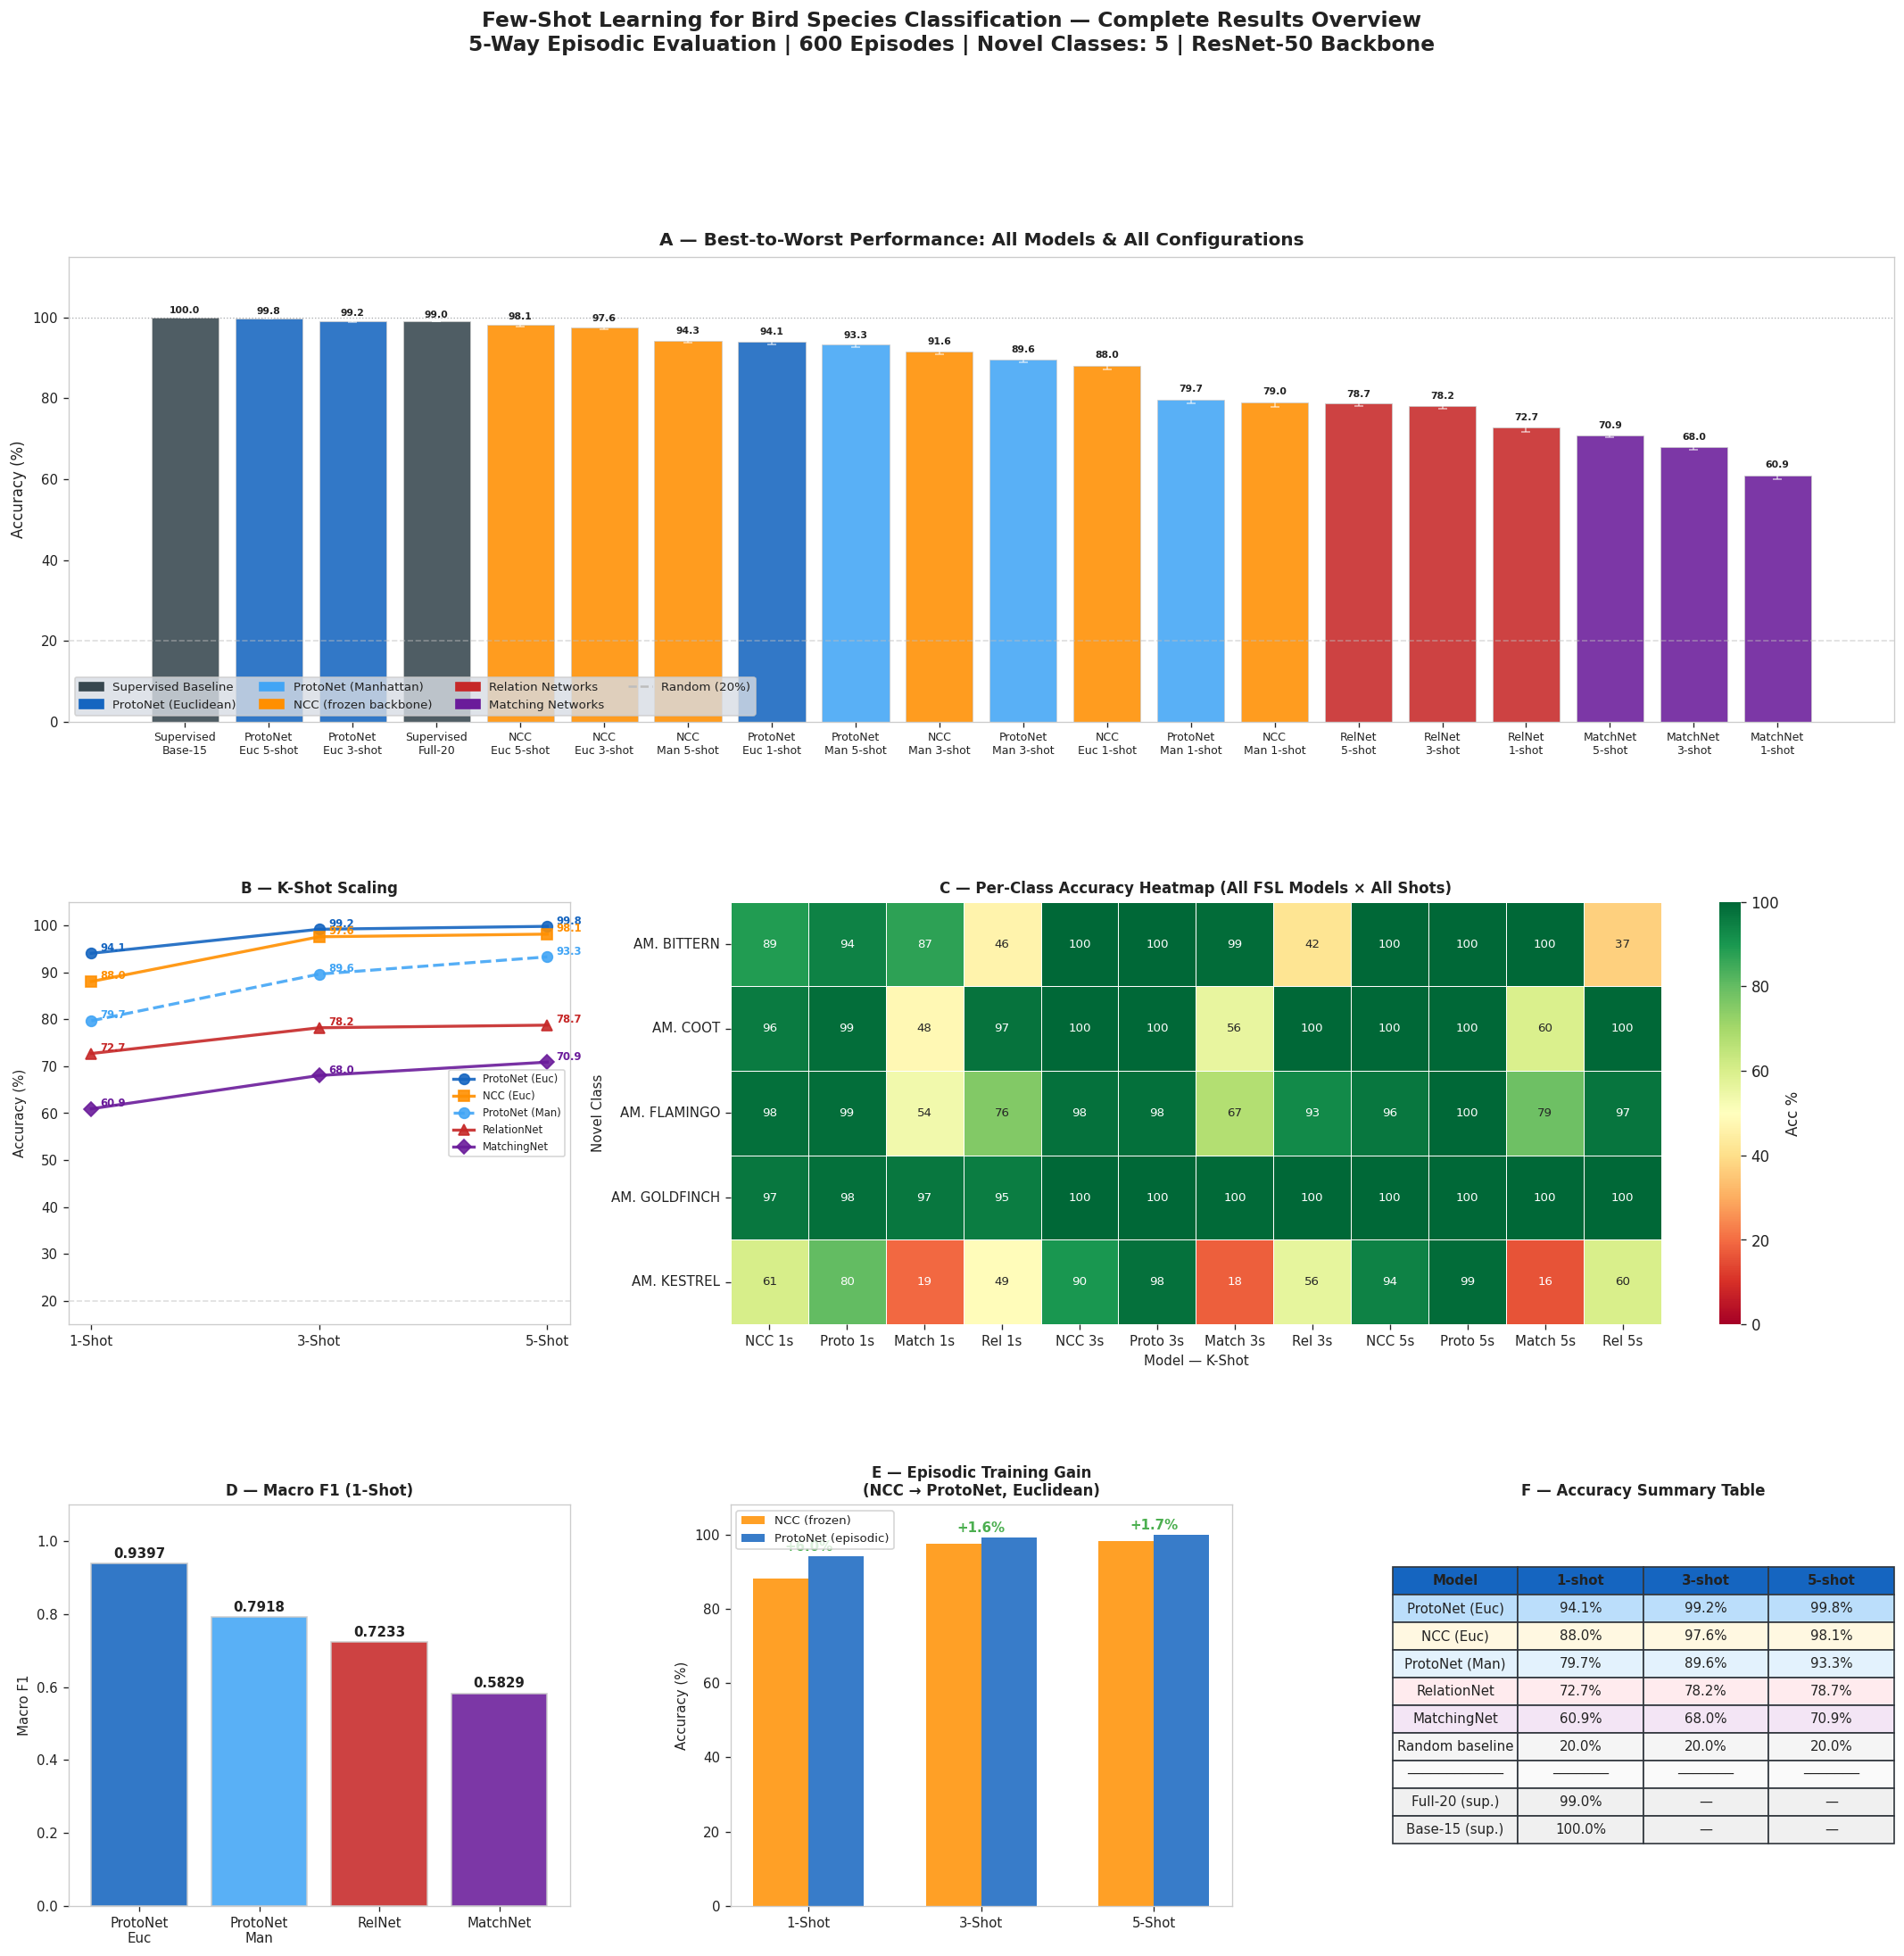

In [260]:
# ═══════════════════════════════════════════════════════════════════════════════
#  THESIS SUMMARY FIGURE — Single Source of Information
#  Best → Worst performance, all models, all key metrics
# ═══════════════════════════════════════════════════════════════════════════════
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

SHOTS = [1, 3, 5]
NOVEL = ['AMERICAN BITTERN', 'AMERICAN COOT', 'AMERICAN FLAMINGO',
         'AMERICAN GOLDFINCH', 'AMERICAN KESTREL']
SHORT = [c.replace('AMERICAN ', 'AM. ') for c in NOVEL]

# ── colour palette ────────────────────────────────────────────────────────────
C = {
    'supervised' : '#37474F',
    'ncc'        : '#FF8F00',
    'proto'      : '#1565C0',
    'proto_man'  : '#42A5F5',
    'match'      : '#6A1B9A',
    'rel'        : '#C62828',
    'random'     : '#BDBDBD',
}

# ── data helpers ──────────────────────────────────────────────────────────────
def acc(key):   r = R.get(key); return r['mean_accuracy_pct'] if r else None
def ci(key):    r = R.get(key); return r['ci95_pct']          if r else 0
def f1(key):    r = R.get(key); return r.get('macro_f1')      if r else None
def pc(key, c): r = R.get(key); return r['per_class_accuracy_pct'].get(c) if r else None

# ── layout: 3 rows × 3 cols with custom heights ───────────────────────────────
fig = plt.figure(figsize=(22, 20))
fig.patch.set_facecolor('white')
gs  = gridspec.GridSpec(3, 3, figure=fig,
                         height_ratios=[1.1, 1.0, 0.95],
                         hspace=0.42, wspace=0.32)

ax_rank  = fig.add_subplot(gs[0, :])      # row 0 — full-width ranking bar
ax_trend = fig.add_subplot(gs[1, 0])      # row 1 col 0 — k-shot trend lines
ax_heat  = fig.add_subplot(gs[1, 1:])     # row 1 col 1-2 — per-class heatmap
ax_f1    = fig.add_subplot(gs[2, 0])      # row 2 col 0 — F1 score bars
ax_dist  = fig.add_subplot(gs[2, 1])      # row 2 col 1 — distance ablation
ax_table = fig.add_subplot(gs[2, 2])      # row 2 col 2 — numeric table

DARK, LIGHT = 'white', '#222222'
for ax in [ax_rank, ax_trend, ax_heat, ax_f1, ax_dist, ax_table]:
    ax.set_facecolor('white')
    ax.tick_params(colors=LIGHT, labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor('#cccccc')

# ─────────────────────────────────────────────────────────────────────────────
# PANEL A — Best-to-worst ranking (1-shot, euclidean)
# ─────────────────────────────────────────────────────────────────────────────
rank_models = [
    ('Supervised\nFull-20',    R['full20_json']['accuracy']*100 if R['full20_json'] else 0,  0,  C['supervised'], '—'),
    ('Supervised\nBase-15',    R['base15_json']['accuracy']*100 if R['base15_json'] else 0,  0,  C['supervised'], '—'),
    ('ProtoNet\nEuc 5-shot',   acc('proto_5shot_euc_json'),       ci('proto_5shot_euc_json'), C['proto'],   '5s'),
    ('ProtoNet\nEuc 3-shot',   acc('proto_3shot_euc_json'),       ci('proto_3shot_euc_json'), C['proto'],   '3s'),
    ('NCC\nEuc 5-shot',        acc('ncc_5shot_euc_json'),         ci('ncc_5shot_euc_json'),   C['ncc'],     '5s'),
    ('NCC\nEuc 3-shot',        acc('ncc_3shot_euc_json'),         ci('ncc_3shot_euc_json'),   C['ncc'],     '3s'),
    ('ProtoNet\nEuc 1-shot',   acc('proto_1shot_euc_json'),       ci('proto_1shot_euc_json'), C['proto'],   '1s'),
    ('NCC\nEuc 1-shot',        acc('ncc_1shot_euc_json'),         ci('ncc_1shot_euc_json'),   C['ncc'],     '1s'),
    ('ProtoNet\nMan 5-shot',   acc('proto_5shot_man_json'),       ci('proto_5shot_man_json'), C['proto_man'],'5s'),
    ('ProtoNet\nMan 3-shot',   acc('proto_3shot_man_json'),       ci('proto_3shot_man_json'), C['proto_man'],'3s'),
    ('NCC\nMan 5-shot',        acc('ncc_5shot_man_json'),         ci('ncc_5shot_man_json'),   C['ncc'],     '5s'),
    ('NCC\nMan 3-shot',        acc('ncc_3shot_man_json'),         ci('ncc_3shot_man_json'),   C['ncc'],     '3s'),
    ('ProtoNet\nMan 1-shot',   acc('proto_1shot_man_json'),       ci('proto_1shot_man_json'), C['proto_man'],'1s'),
    ('RelNet\n5-shot',         acc('rel_5shot_json'),             ci('rel_5shot_json'),       C['rel'],     '5s'),
    ('RelNet\n3-shot',         acc('rel_3shot_json'),             ci('rel_3shot_json'),       C['rel'],     '3s'),
    ('NCC\nMan 1-shot',        acc('ncc_1shot_man_json'),         ci('ncc_1shot_man_json'),   C['ncc'],     '1s'),
    ('RelNet\n1-shot',         acc('rel_1shot_json'),             ci('rel_1shot_json'),       C['rel'],     '1s'),
    ('MatchNet\n5-shot',       acc('match_5shot_json'),           ci('match_5shot_json'),     C['match'],   '5s'),
    ('MatchNet\n3-shot',       acc('match_3shot_json'),           ci('match_3shot_json'),     C['match'],   '3s'),
    ('MatchNet\n1-shot',       acc('match_1shot_json'),           ci('match_1shot_json'),     C['match'],   '1s'),
]
rank_models = [(l, a, e, c, s) for l, a, e, c, s in rank_models if a is not None]
rank_models.sort(key=lambda x: x[1], reverse=True)

labels = [r[0] for r in rank_models]
vals   = [r[1] for r in rank_models]
errs   = [r[2] for r in rank_models]
cols   = [r[3] for r in rank_models]

bars = ax_rank.bar(range(len(labels)), vals, color=cols, alpha=0.88,
                   edgecolor='#cccccc', linewidth=0.5)
ax_rank.errorbar(range(len(labels)), vals, yerr=errs,
                 fmt='none', color='white', capsize=3, linewidth=1, alpha=0.6)
ax_rank.axhline(20,  color=C['random'], linestyle='--', linewidth=1, alpha=0.5, label='Random 20%')
ax_rank.axhline(100, color='#30363D',   linestyle=':',  linewidth=0.8, alpha=0.4)
for i, (bar, v, e) in enumerate(zip(bars, vals, errs)):
    ax_rank.text(bar.get_x()+bar.get_width()/2, v+e+0.6,
                 f'{v:.1f}', ha='center', va='bottom', fontsize=6.5,
                 color=LIGHT, fontweight='bold')
ax_rank.set_xticks(range(len(labels)))
ax_rank.set_xticklabels(labels, fontsize=7.5, color=LIGHT)
ax_rank.set_ylabel('Accuracy (%)', color=LIGHT, fontsize=10)
ax_rank.set_ylim(0, 115)
ax_rank.set_title('A — Best-to-Worst Performance: All Models & All Configurations',
                  color=LIGHT, fontsize=12, fontweight='bold', pad=8)
legend_elems = [
    Patch(color=C['supervised'], label='Supervised Baseline'),
    Patch(color=C['proto'],      label='ProtoNet (Euclidean)'),
    Patch(color=C['proto_man'],  label='ProtoNet (Manhattan)'),
    Patch(color=C['ncc'],        label='NCC (frozen backbone)'),
    Patch(color=C['rel'],        label='Relation Networks'),
    Patch(color=C['match'],      label='Matching Networks'),
    Line2D([0],[0], color=C['random'], linestyle='--', label='Random (20%)'),
]
ax_rank.legend(handles=legend_elems, fontsize=8, loc='lower left',
               facecolor="#D8DDE4", edgecolor='#cccccc', labelcolor=LIGHT, ncol=4)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL B — K-shot trend lines
# ─────────────────────────────────────────────────────────────────────────────
trend_models = [
    ('ProtoNet (Euc)', [acc(f'proto_{s}shot_euc_json') for s in SHOTS], C['proto'],    'o-'),
    ('NCC (Euc)',      [acc(f'ncc_{s}shot_euc_json')   for s in SHOTS], C['ncc'],     's-'),
    ('ProtoNet (Man)', [acc(f'proto_{s}shot_man_json') for s in SHOTS], C['proto_man'],'o--'),
    ('RelationNet',    [acc(f'rel_{s}shot_json')       for s in SHOTS], C['rel'],     '^-'),
    ('MatchingNet',    [acc(f'match_{s}shot_json')     for s in SHOTS], C['match'],   'D-'),
]
for label, accs_list, color, marker in trend_models:
    ax_trend.plot(SHOTS, accs_list, marker, color=color, label=label,
                  linewidth=2, markersize=7, alpha=0.9)
    for s, a in zip(SHOTS, accs_list):
        if a: ax_trend.text(s+0.08, a+0.5, f'{a:.1f}', fontsize=7, color=color, fontweight='bold')
ax_trend.axhline(20, color=C['random'], linestyle='--', linewidth=1, alpha=0.5)
ax_trend.set_xticks(SHOTS); ax_trend.set_xticklabels(['1-Shot','3-Shot','5-Shot'], color=LIGHT)
ax_trend.set_ylabel('Accuracy (%)', color=LIGHT, fontsize=9)
ax_trend.set_ylim(15, 105)
ax_trend.set_title('B — K-Shot Scaling', color=LIGHT, fontsize=10, fontweight='bold')
ax_trend.legend(fontsize=7, facecolor='white', edgecolor='#cccccc', labelcolor=LIGHT)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL C — Per-class heatmap (best configs only: Euclidean)
# ─────────────────────────────────────────────────────────────────────────────
heat_cols = {}
for s in SHOTS:
    r = R.get(f'ncc_{s}shot_euc_json')
    if r: heat_cols[f'NCC {s}s']   = [r['per_class_accuracy_pct'][c] for c in NOVEL]
    r = R.get(f'proto_{s}shot_euc_json')
    if r: heat_cols[f'Proto {s}s'] = [r['per_class_accuracy_pct'][c] for c in NOVEL]
    r = R.get(f'match_{s}shot_json')
    if r: heat_cols[f'Match {s}s'] = [r['per_class_accuracy_pct'][c] for c in NOVEL]
    r = R.get(f'rel_{s}shot_json')
    if r: heat_cols[f'Rel {s}s']   = [r['per_class_accuracy_pct'][c] for c in NOVEL]

df_h = pd.DataFrame(heat_cols, index=SHORT)
sns.heatmap(df_h, annot=True, fmt='.0f', cmap='RdYlGn', vmin=0, vmax=100,
            linewidths=0.4, ax=ax_heat, cbar_kws={'label': 'Acc %'},
            annot_kws={'size': 8})
ax_heat.set_title('C — Per-Class Accuracy Heatmap (All FSL Models × All Shots)',
                  color=LIGHT, fontsize=10, fontweight='bold')
ax_heat.set_xlabel('Model — K-Shot', color=LIGHT, fontsize=9)
ax_heat.set_ylabel('Novel Class', color=LIGHT, fontsize=9)
ax_heat.tick_params(colors=LIGHT)
ax_heat.figure.axes[-1].tick_params(colors=LIGHT)
ax_heat.figure.axes[-1].yaxis.label.set_color(LIGHT)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL D — Macro F1 at 1-shot
# ─────────────────────────────────────────────────────────────────────────────
f1_items = [
    ('ProtoNet\nEuc', f1('proto_1shot_euc_json'), C['proto']),
    ('ProtoNet\nMan', f1('proto_1shot_man_json'), C['proto_man']),
    ('RelNet',        f1('rel_1shot_json'),        C['rel']),
    ('MatchNet',      f1('match_1shot_json'),      C['match']),
]
f1_items = [(l, v, c) for l, v, c in f1_items if v]
f1_items.sort(key=lambda x: x[1], reverse=True)
bars_f1 = ax_f1.bar([x[0] for x in f1_items], [x[1] for x in f1_items],
                     color=[x[2] for x in f1_items], alpha=0.88, edgecolor='#cccccc')
for bar, (_, v, _) in zip(bars_f1, f1_items):
    ax_f1.text(bar.get_x()+bar.get_width()/2, v+0.008, f'{v:.4f}',
               ha='center', va='bottom', fontsize=9, color=LIGHT, fontweight='bold')
ax_f1.set_ylim(0, 1.1); ax_f1.set_ylabel('Macro F1', color=LIGHT, fontsize=9)
ax_f1.set_title('D — Macro F1 (1-Shot)', color=LIGHT, fontsize=10, fontweight='bold')
ax_f1.tick_params(colors=LIGHT)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL E — Episodic training gain (NCC vs ProtoNet)
# ─────────────────────────────────────────────────────────────────────────────
ncc_vals   = [acc(f'ncc_{s}shot_euc_json')   for s in SHOTS]
proto_vals = [acc(f'proto_{s}shot_euc_json') for s in SHOTS]
gains      = [p - n for p, n in zip(proto_vals, ncc_vals)]
x_pos = np.arange(len(SHOTS)); w = 0.32

ax_dist.bar(x_pos - w/2, ncc_vals,   w, label='NCC (frozen)',         color=C['ncc'],   alpha=0.85)
ax_dist.bar(x_pos + w/2, proto_vals, w, label='ProtoNet (episodic)',   color=C['proto'], alpha=0.85)
for i, (n, p, g) in enumerate(zip(ncc_vals, proto_vals, gains)):
    ax_dist.annotate(f'+{g:.1f}%', xy=(i, max(n,p)+1.5), ha='center',
                     fontsize=9, color='#4CAF50', fontweight='bold')
ax_dist.set_xticks(x_pos)
ax_dist.set_xticklabels(['1-Shot','3-Shot','5-Shot'], color=LIGHT)
ax_dist.set_ylabel('Accuracy (%)', color=LIGHT, fontsize=9)
ax_dist.set_ylim(0, 108)
ax_dist.set_title('E — Episodic Training Gain\n(NCC → ProtoNet, Euclidean)',
                  color=LIGHT, fontsize=10, fontweight='bold')
ax_dist.legend(fontsize=8, facecolor='white', edgecolor='#cccccc', labelcolor=LIGHT)
ax_dist.tick_params(colors=LIGHT)

# ─────────────────────────────────────────────────────────────────────────────
# PANEL F — Numeric summary table
# ─────────────────────────────────────────────────────────────────────────────
ax_table.axis('off')
table_data = [
    ['Model',              '1-shot',  '3-shot',  '5-shot'],
    ['ProtoNet (Euc)',     f"{acc('proto_1shot_euc_json'):.1f}%",
                           f"{acc('proto_3shot_euc_json'):.1f}%",
                           f"{acc('proto_5shot_euc_json'):.1f}%"],
    ['NCC (Euc)',          f"{acc('ncc_1shot_euc_json'):.1f}%",
                           f"{acc('ncc_3shot_euc_json'):.1f}%",
                           f"{acc('ncc_5shot_euc_json'):.1f}%"],
    ['ProtoNet (Man)',     f"{acc('proto_1shot_man_json'):.1f}%",
                           f"{acc('proto_3shot_man_json'):.1f}%",
                           f"{acc('proto_5shot_man_json'):.1f}%"],
    ['RelationNet',        f"{acc('rel_1shot_json'):.1f}%",
                           f"{acc('rel_3shot_json'):.1f}%",
                           f"{acc('rel_5shot_json'):.1f}%"],
    ['MatchingNet',        f"{acc('match_1shot_json'):.1f}%",
                           f"{acc('match_3shot_json'):.1f}%",
                           f"{acc('match_5shot_json'):.1f}%"],
    ['Random baseline',   '20.0%',   '20.0%',   '20.0%'],
    ['─'*12,              '─'*7,     '─'*7,     '─'*7],
    ['Full-20 (sup.)',    f"{R['full20_json']['accuracy']*100:.1f}%" if R['full20_json'] else '—', '—', '—'],
    ['Base-15 (sup.)',    f"{R['base15_json']['accuracy']*100:.1f}%" if R['base15_json'] else '—', '—', '—'],
]
row_colors = [
    ['#1565C0']*4,
    ['#BBDEFB','#BBDEFB','#BBDEFB','#BBDEFB'],
    ['#FFF8E1','#FFF8E1','#FFF8E1','#FFF8E1'],
    ['#E3F2FD','#E3F2FD','#E3F2FD','#E3F2FD'],
    ['#FFEBEE','#FFEBEE','#FFEBEE','#FFEBEE'],
    ['#F3E5F5','#F3E5F5','#F3E5F5','#F3E5F5'],
    ['#F5F5F5','#F5F5F5','#F5F5F5','#F5F5F5'],
    ['#FAFAFA']*4,
    ['#F0F0F0']*4,
    ['#F0F0F0']*4,
]
tbl = ax_table.table(cellText=table_data, cellLoc='center', loc='center',
                      cellColours=row_colors)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.55)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor('#30363D')
    cell.set_text_props(color=LIGHT, fontweight='bold' if r == 0 else 'normal')
ax_table.set_title('F — Accuracy Summary Table', color=LIGHT, fontsize=10, fontweight='bold')

# ─────────────────────────────────────────────────────────────────────────────
# Main title
# ─────────────────────────────────────────────────────────────────────────────
fig.suptitle(
    'Few-Shot Learning for Bird Species Classification — Complete Results Overview\n'
    '5-Way Episodic Evaluation | 600 Episodes | Novel Classes: 5 | ResNet-50 Backbone',
    color=LIGHT, fontsize=14, fontweight='bold', y=0.995
)

plt.savefig(f'{RES}/analysis/thesis_summary_figure.png', dpi=180, bbox_inches='tight',
            facecolor='white')
print(f"Saved → {RES}/thesis_summary_figure.png")
plt.show()

---
## 11. Deep-Dive Analysis & Thesis Evidence

> These cells implement the six key suggestions derived from the result analysis.
> Each cell is self-contained and produces a thesis-ready figure.

| # | Priority | Finding |
|---|----------|---------|
| 11.1 | 🔴 High | KESTREL visual investigation — why is it universally hard? |
| 11.2 | 🔴 High | RelationNet BITTERN inverse scaling — performance degrades with more shots |
| 11.3 | 🟡 Medium | t-SNE side-by-side — KESTREL cluster position across models |
| 11.4 | 🟡 Medium | NCC ablation — what does episodic training actually add? |
| 11.5 | 🟢 Low | ProtoNet Manhattan as a negative result |
| 11.6 | 🟢 Low | RelationNet convergence analysis — plateau vs backbone capability |

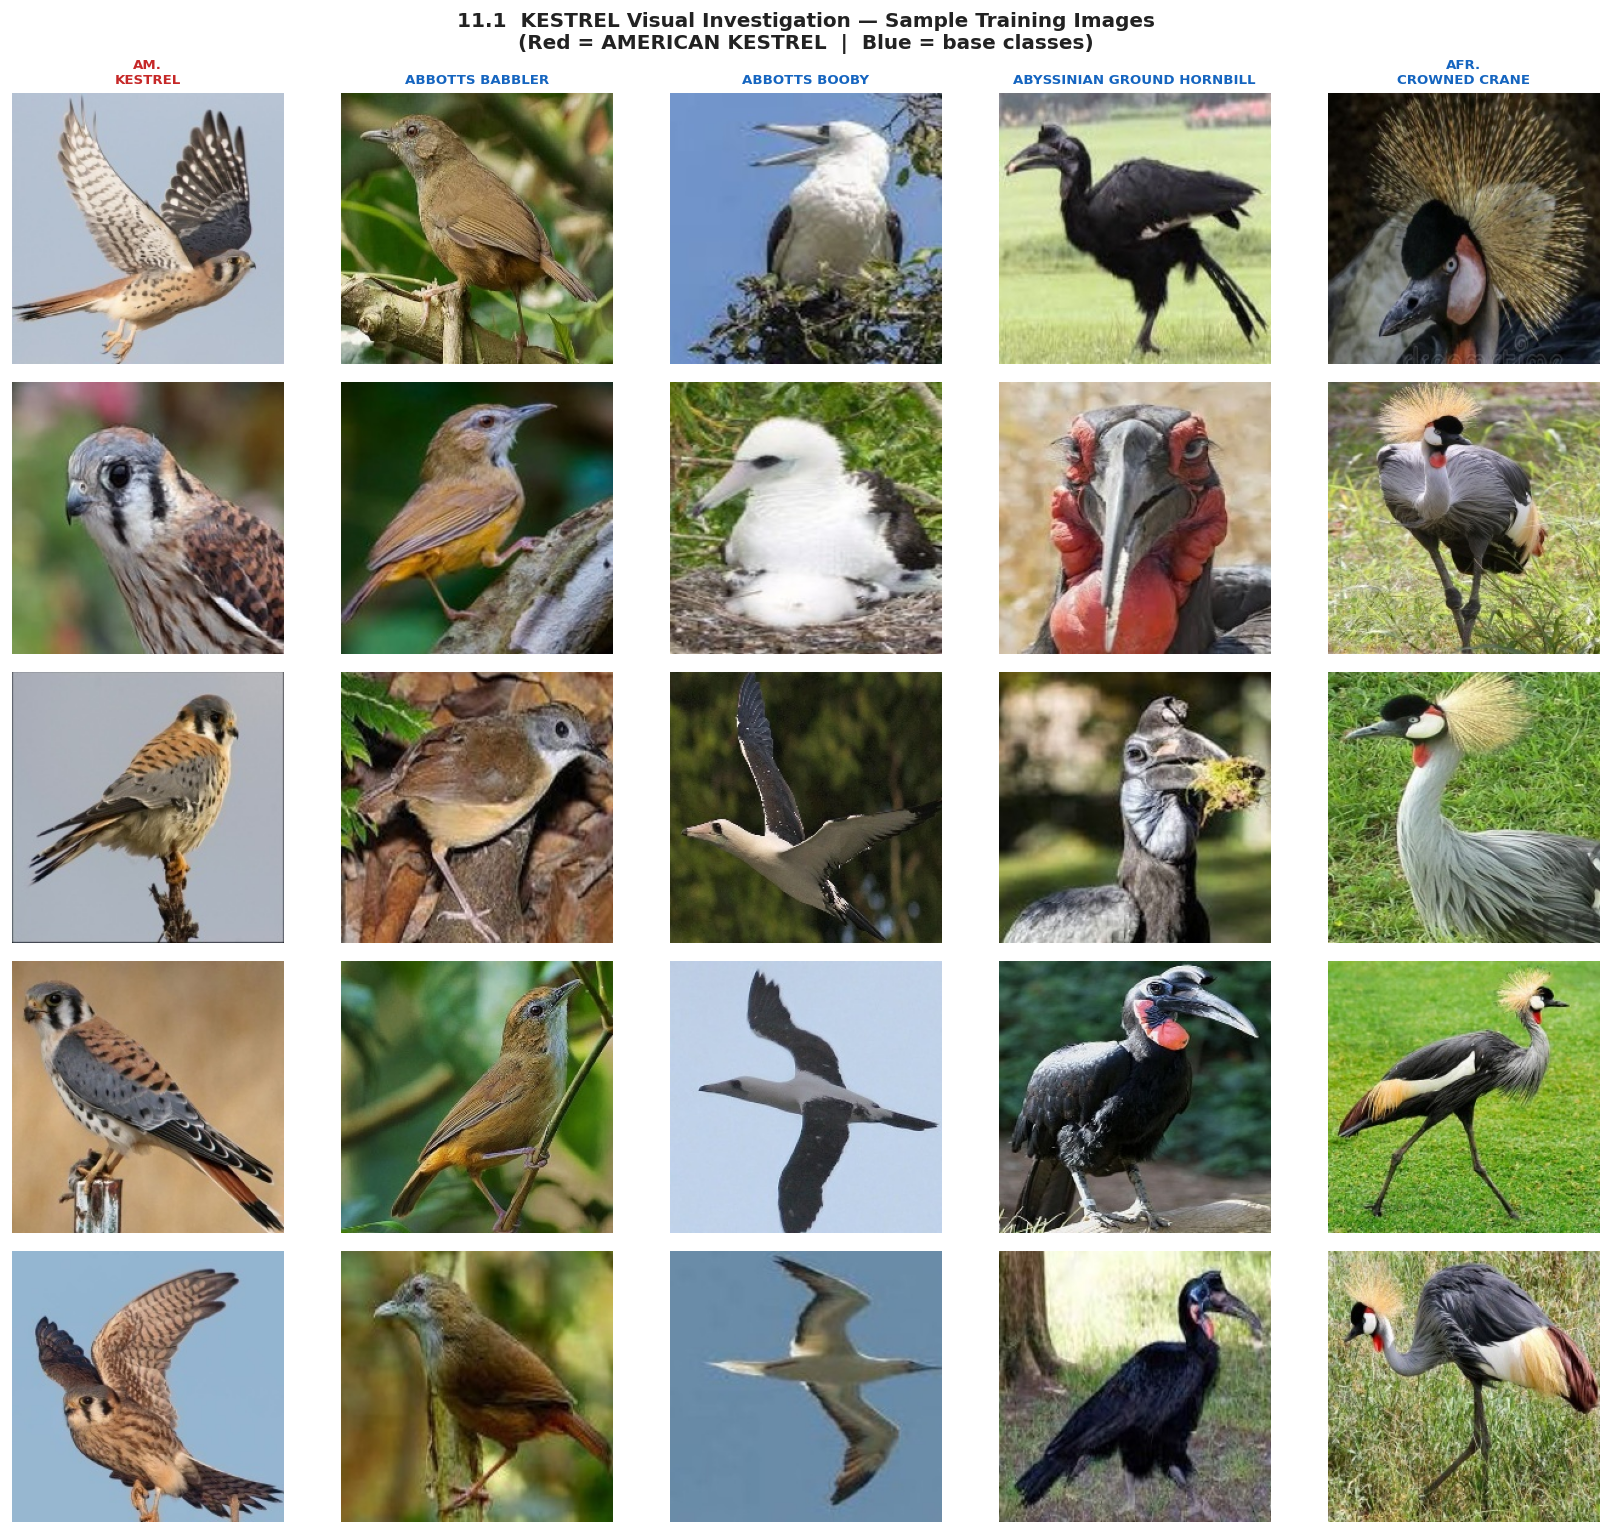

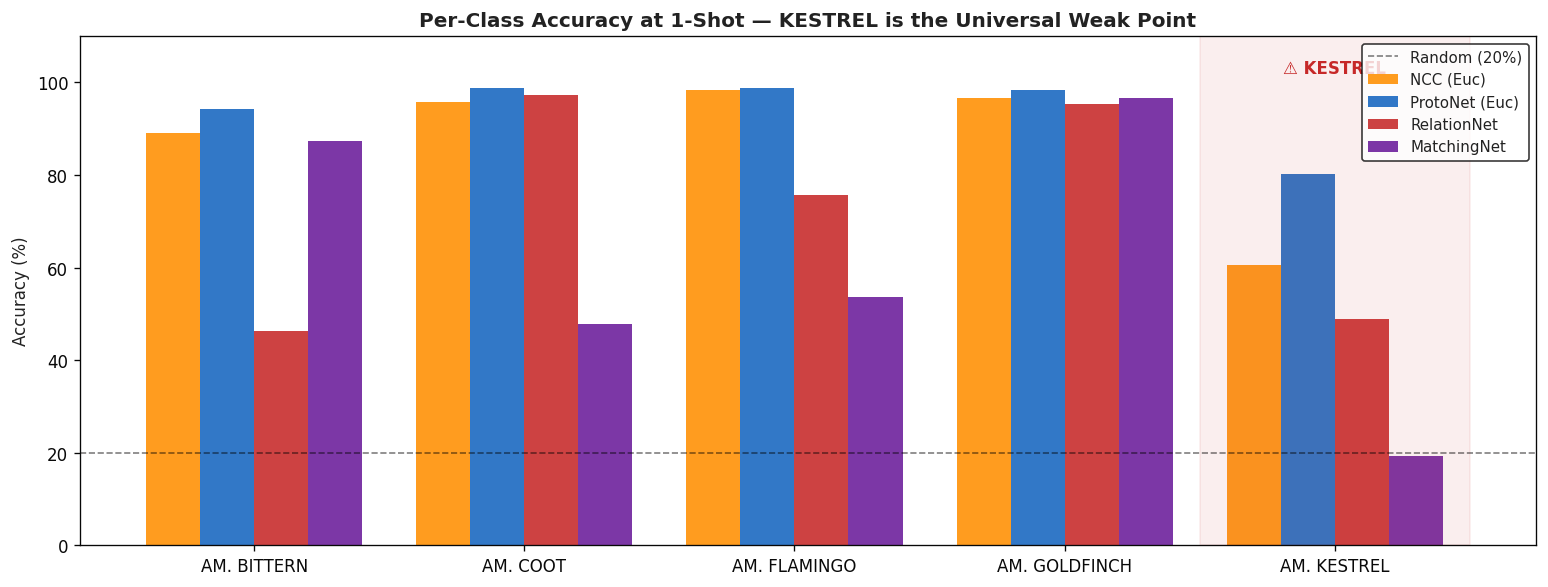

Kestrel 1-shot accuracy across models:
  NCC (Euc)           : 60.5%
  ProtoNet (Euc)      : 80.2%
  RelationNet         : 49.0%
  MatchingNet         : 19.3%


In [273]:
# ── 11.1  KESTREL Visual Investigation ────────────────────────────────────────
# Show sample KESTREL images alongside the most visually similar base classes,
# then plot per-class 1-shot accuracy across ALL models to expose the pattern.

import random, pathlib
random.seed(42)

DATA = os.path.join(ROOT, 'data', 'train')

# All 15 base classes (same order as dataset cell)
BASE_CLASSES = [
    'ABBOTTS BABBLER','ABBOTTS BOOBY','ABYSSINIAN GROUND HORNBILL',
    'AFRICAN CROWNED CRANE','AFRICAN EMERALD CUCKOO','AFRICAN FIREFINCH',
    'AFRICAN OYSTER CATCHER','AFRICAN PIED HORNBILL','AFRICAN PYGMY GOOSE',
    'ALBATROSS','ALBERTS TOWHEE','ALEXANDRINE PARAKEET',
    'ALPINE CHOUGH','ALTAMIRA YELLOWTHROAT','AMERICAN AVOCET',
]
NOVEL_CLASSES = ['AMERICAN BITTERN','AMERICAN COOT','AMERICAN FLAMINGO',
                 'AMERICAN GOLDFINCH','AMERICAN KESTREL']

def sample_imgs(cls, n=5):
    folder = pathlib.Path(DATA) / cls
    imgs   = sorted(folder.glob('*.jpg'))
    return random.sample(imgs, min(n, len(imgs)))

# ── Figure: sample images ─────────────────────────────────────────────────────
show_classes = ['AMERICAN KESTREL'] + BASE_CLASSES[:4]   # Kestrel + 4 base classes
n_cols, n_imgs = len(show_classes), 5
fig, axes = plt.subplots(n_imgs, n_cols, figsize=(n_cols*2.8, n_imgs*2.6))
fig.patch.set_facecolor('white')

for col, cls in enumerate(show_classes):
    imgs = sample_imgs(cls, n_imgs)
    color = '#C62828' if 'KESTREL' in cls else '#1565C0'
    axes[0, col].set_title(cls.replace('AMERICAN ', 'AM.\n').replace('AFRICAN ', 'AFR.\n'),
                            fontsize=8, color=color, fontweight='bold')
    for row, img_path in enumerate(imgs):
        axes[row, col].imshow(mpimg.imread(str(img_path)))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(f'img {row+1}', color='#222222', fontsize=7)

fig.suptitle('11.1  KESTREL Visual Investigation — Sample Training Images\n'
             '(Red = AMERICAN KESTREL  |  Blue = base classes)',
             color='#222222', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/analysis_kestrel_samples.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

# ── Figure: per-class 1-shot accuracy across all models ──────────────────────
models_1shot = {
    'NCC (Euc)':      R['ncc_1shot_euc_json'],
    'ProtoNet (Euc)': R['proto_1shot_euc_json'],
    'RelationNet':    R['rel_1shot_json'] or {},
    'MatchingNet':    R['match_1shot_json'],
}
SHORT_NOVEL = [c.replace('AMERICAN ', 'AM. ') for c in NOVEL_CLASSES]
x = np.arange(len(NOVEL_CLASSES)); w = 0.2
colors_m = [C['ncc'], C['proto'], C['rel'], C['match']]

fig, ax = plt.subplots(figsize=(13, 5))
fig.patch.set_facecolor('white'); ax.set_facecolor('white')
for spine in ax.spines.values(): spine.set_edgecolor("#070707")

for i, (label, r) in enumerate(models_1shot.items()):
    vals = [r['per_class_accuracy_pct'][c] for c in NOVEL_CLASSES] if r and 'per_class_accuracy_pct' in r else [float('nan')] * len(NOVEL_CLASSES)
    offset = (i - len(models_1shot)/2 + 0.5) * w
    bars = ax.bar(x + offset, vals, w, label=label, color=colors_m[i], alpha=0.88)

# Highlight KESTREL column
ax.axvspan(3.5, 4.5, color='#C62828', alpha=0.08)
ax.text(4, 102, '⚠ KESTREL', ha='center', color='#C62828', fontsize=10, fontweight='bold')
ax.axhline(20, color="#020101", linestyle='--', linewidth=1, alpha=0.5, label='Random (20%)')

ax.set_xticks(x); ax.set_xticklabels(SHORT_NOVEL, color='#222222', fontsize=10)
ax.set_ylabel('Accuracy (%)', color='#222222'); ax.set_ylim(0, 110)
ax.tick_params(colors="#090909")
ax.set_title('Per-Class Accuracy at 1-Shot — KESTREL is the Universal Weak Point',
             color='#222222', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, facecolor='white', edgecolor="#0a0909", labelcolor='#222222')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/analysis_kestrel_perclass.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

print("Kestrel 1-shot accuracy across models:")
for label, r in models_1shot.items():
    if r and 'per_class_accuracy_pct' in r:
        print(f"  {label:<20}: {r['per_class_accuracy_pct']['AMERICAN KESTREL']:.1f}%")
    else:
        print(f"  {label:<20}: N/A")

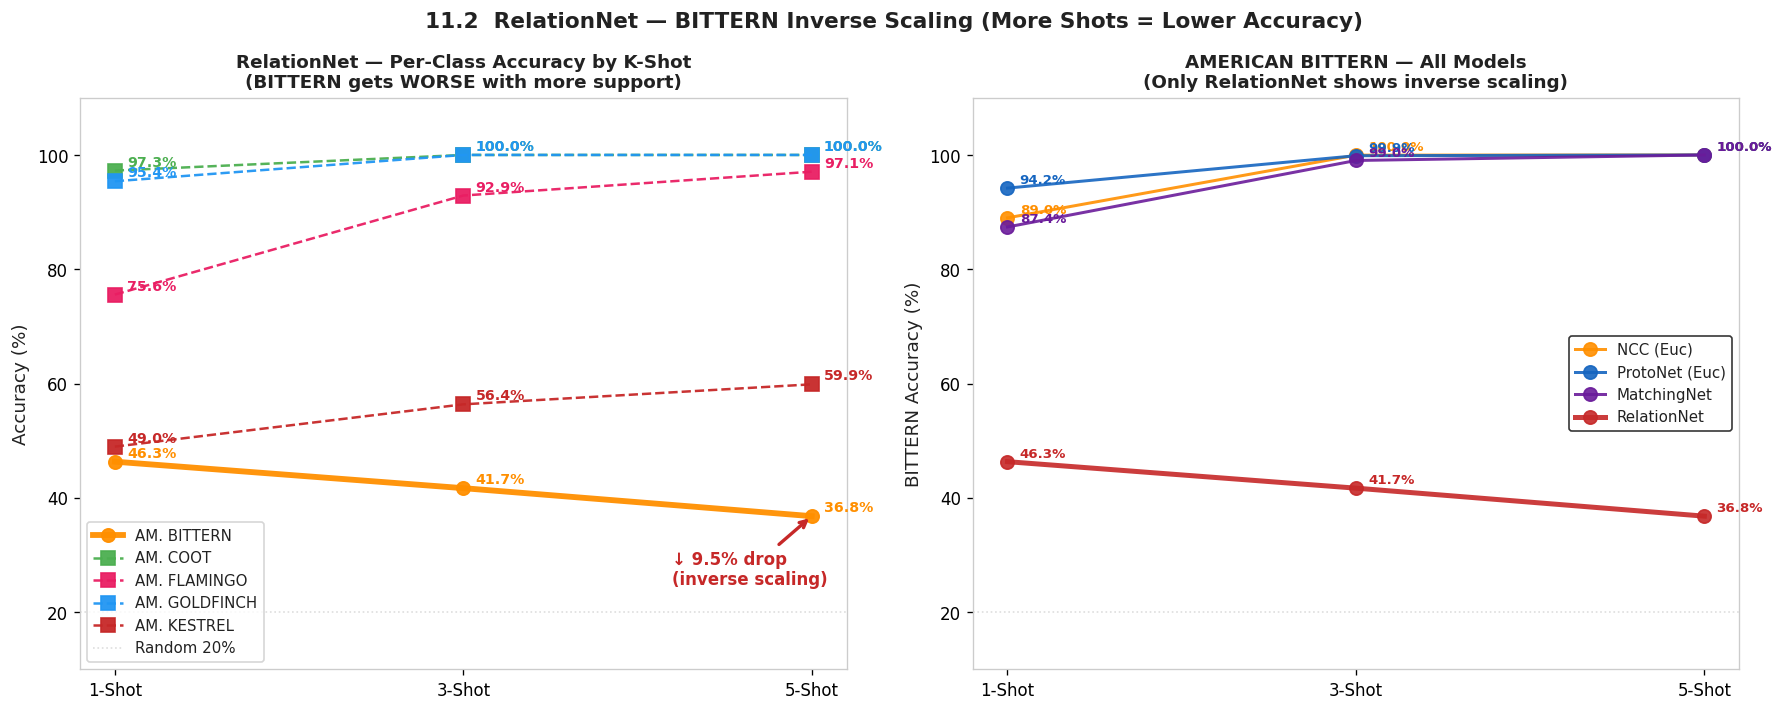

AMERICAN BITTERN accuracy across models × shots:
Model                    1-shot   3-shot   5-shot     Δ(1→5)
------------------------------------------------------------
  NCC (Euc)               89.0%   100.0%   100.0% +    11.0%
  ProtoNet (Euc)          94.2%    99.9%   100.0% +     5.8%
  MatchingNet             87.4%    99.0%   100.0% +    12.6%
  RelationNet             46.3%    41.7%    36.8%     -9.5%


In [274]:
_rel_available = all(R.get(f'rel_{s}shot_json') is not None for s in [1,3,5])
if not _rel_available:
    print("RelationNet b15/n5 results not yet available — run evaluate.py first.")
else:
    # ── 11.2  RelationNet BITTERN Inverse Scaling ─────────────────────────────────
    # Performance on BITTERN DEGRADES as more support shots are provided.
    # This cell plots per-class accuracy across shots for RelationNet
    # and highlights the anomalous inverse scaling on BITTERN.

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    fig.patch.set_facecolor('white')
    for ax in axes:
        ax.set_facecolor('white')
        for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

    SHOTS = [1, 3, 5]
    # Panel A — per-class line chart for RelationNet
    for cls, color in zip(NOVEL_CLASSES, ['#FF8F00','#4CAF50','#E91E63','#2196F3','#C62828']):
        vals = [R[f'rel_{s}shot_json']['per_class_accuracy_pct'][cls] for s in SHOTS]
        lw   = 3.5 if 'BITTERN' in cls else 1.5
        ls   = '-' if 'BITTERN' in cls else '--'
        marker = 'o' if 'BITTERN' in cls else 's'
        axes[0].plot(SHOTS, vals, ls, color=color, linewidth=lw, marker=marker,
                     markersize=8, label=cls.replace('AMERICAN ', 'AM. '), alpha=0.95)
        for s, v in zip(SHOTS, vals):
            axes[0].text(s + 0.07, v + 0.8, f'{v:.1f}%', fontsize=8.5, color=color, fontweight='bold')

    axes[0].axhline(20, color='#BDBDBD', linestyle=':', linewidth=1, alpha=0.5, label='Random 20%')
    axes[0].set_xticks(SHOTS); axes[0].set_xticklabels(['1-Shot','3-Shot','5-Shot'], color='#222222')
    axes[0].set_ylabel('Accuracy (%)', color='#222222', fontsize=11)
    axes[0].set_ylim(10, 110)
    axes[0].tick_params(colors="#000000")
    axes[0].set_title('RelationNet — Per-Class Accuracy by K-Shot\n(BITTERN gets WORSE with more support)',
                      color='#222222', fontsize=11, fontweight='bold')
    axes[0].legend(fontsize=9, facecolor='white', edgecolor='#cccccc', labelcolor='#222222')

    # Annotate the drop
    bittern_vals = [R[f'rel_{s}shot_json']['per_class_accuracy_pct']['AMERICAN BITTERN'] for s in SHOTS]
    drop = bittern_vals[0] - bittern_vals[2]
    axes[0].annotate(f'↓ {drop:.1f}% drop\n(inverse scaling)',
                     xy=(5, bittern_vals[2]), xytext=(4.2, bittern_vals[2] - 12),
                     arrowprops=dict(arrowstyle='->', color='#C62828', lw=2),
                     color='#C62828', fontsize=10, fontweight='bold')

    # Panel B — compare BITTERN across ALL models at all shots
    for model_label, key_tmpl, color in [
        ('NCC (Euc)',      'ncc_{s}shot_euc_json',   C['ncc']),
        ('ProtoNet (Euc)', 'proto_{s}shot_euc_json',  C['proto']),
        ('MatchingNet',    'match_{s}shot_json',       C['match']),
        ('RelationNet',    'rel_{s}shot_json',         C['rel']),
    ]:
        vals = [R[key_tmpl.format(s=s)]['per_class_accuracy_pct']['AMERICAN BITTERN'] for s in SHOTS]
        lw = 3 if 'Relation' in model_label else 1.8
        axes[1].plot(SHOTS, vals, 'o-', color=color, linewidth=lw, markersize=8,
                     label=model_label, alpha=0.9)
        for s, v in zip(SHOTS, vals):
            axes[1].text(s + 0.07, v + 0.8, f'{v:.1f}%', fontsize=8, color=color, fontweight='bold')

    axes[1].axhline(20, color='#BDBDBD', linestyle=':', linewidth=1, alpha=0.5)
    axes[1].set_xticks(SHOTS); axes[1].set_xticklabels(['1-Shot','3-Shot','5-Shot'], color='#222222')
    axes[1].set_ylabel('BITTERN Accuracy (%)', color='#222222', fontsize=11)
    axes[1].set_ylim(10, 110); axes[1].tick_params(colors="#000000")
    axes[1].set_title('AMERICAN BITTERN — All Models\n(Only RelationNet shows inverse scaling)',
                      color='#222222', fontsize=11, fontweight='bold')
    axes[1].legend(fontsize=9, facecolor='white', edgecolor="#040404", labelcolor='#222222')

    fig.suptitle('11.2  RelationNet — BITTERN Inverse Scaling (More Shots = Lower Accuracy)',
                 color='#222222', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{RES}/analysis/analysis_bittern_inverse_scaling.png', dpi=150, bbox_inches='tight',
                facecolor='white')
    plt.show()

    print("AMERICAN BITTERN accuracy across models × shots:")
    print(f"{'Model':<22} {'1-shot':>8} {'3-shot':>8} {'5-shot':>8} {'Δ(1→5)':>10}")
    print("-" * 60)
    for model_label, key_tmpl in [('NCC (Euc)','ncc_{s}shot_euc_json'),
                                    ('ProtoNet (Euc)','proto_{s}shot_euc_json'),
                                    ('MatchingNet','match_{s}shot_json'),
                                    ('RelationNet','rel_{s}shot_json')]:
        vals = [R[key_tmpl.format(s=s)]['per_class_accuracy_pct']['AMERICAN BITTERN'] for s in SHOTS]
        delta = vals[2] - vals[0]
        sign  = '+' if delta >= 0 else ''
        print(f"  {model_label:<20} {vals[0]:>7.1f}% {vals[1]:>7.1f}% {vals[2]:>7.1f}% {sign}{delta:>8.1f}%")

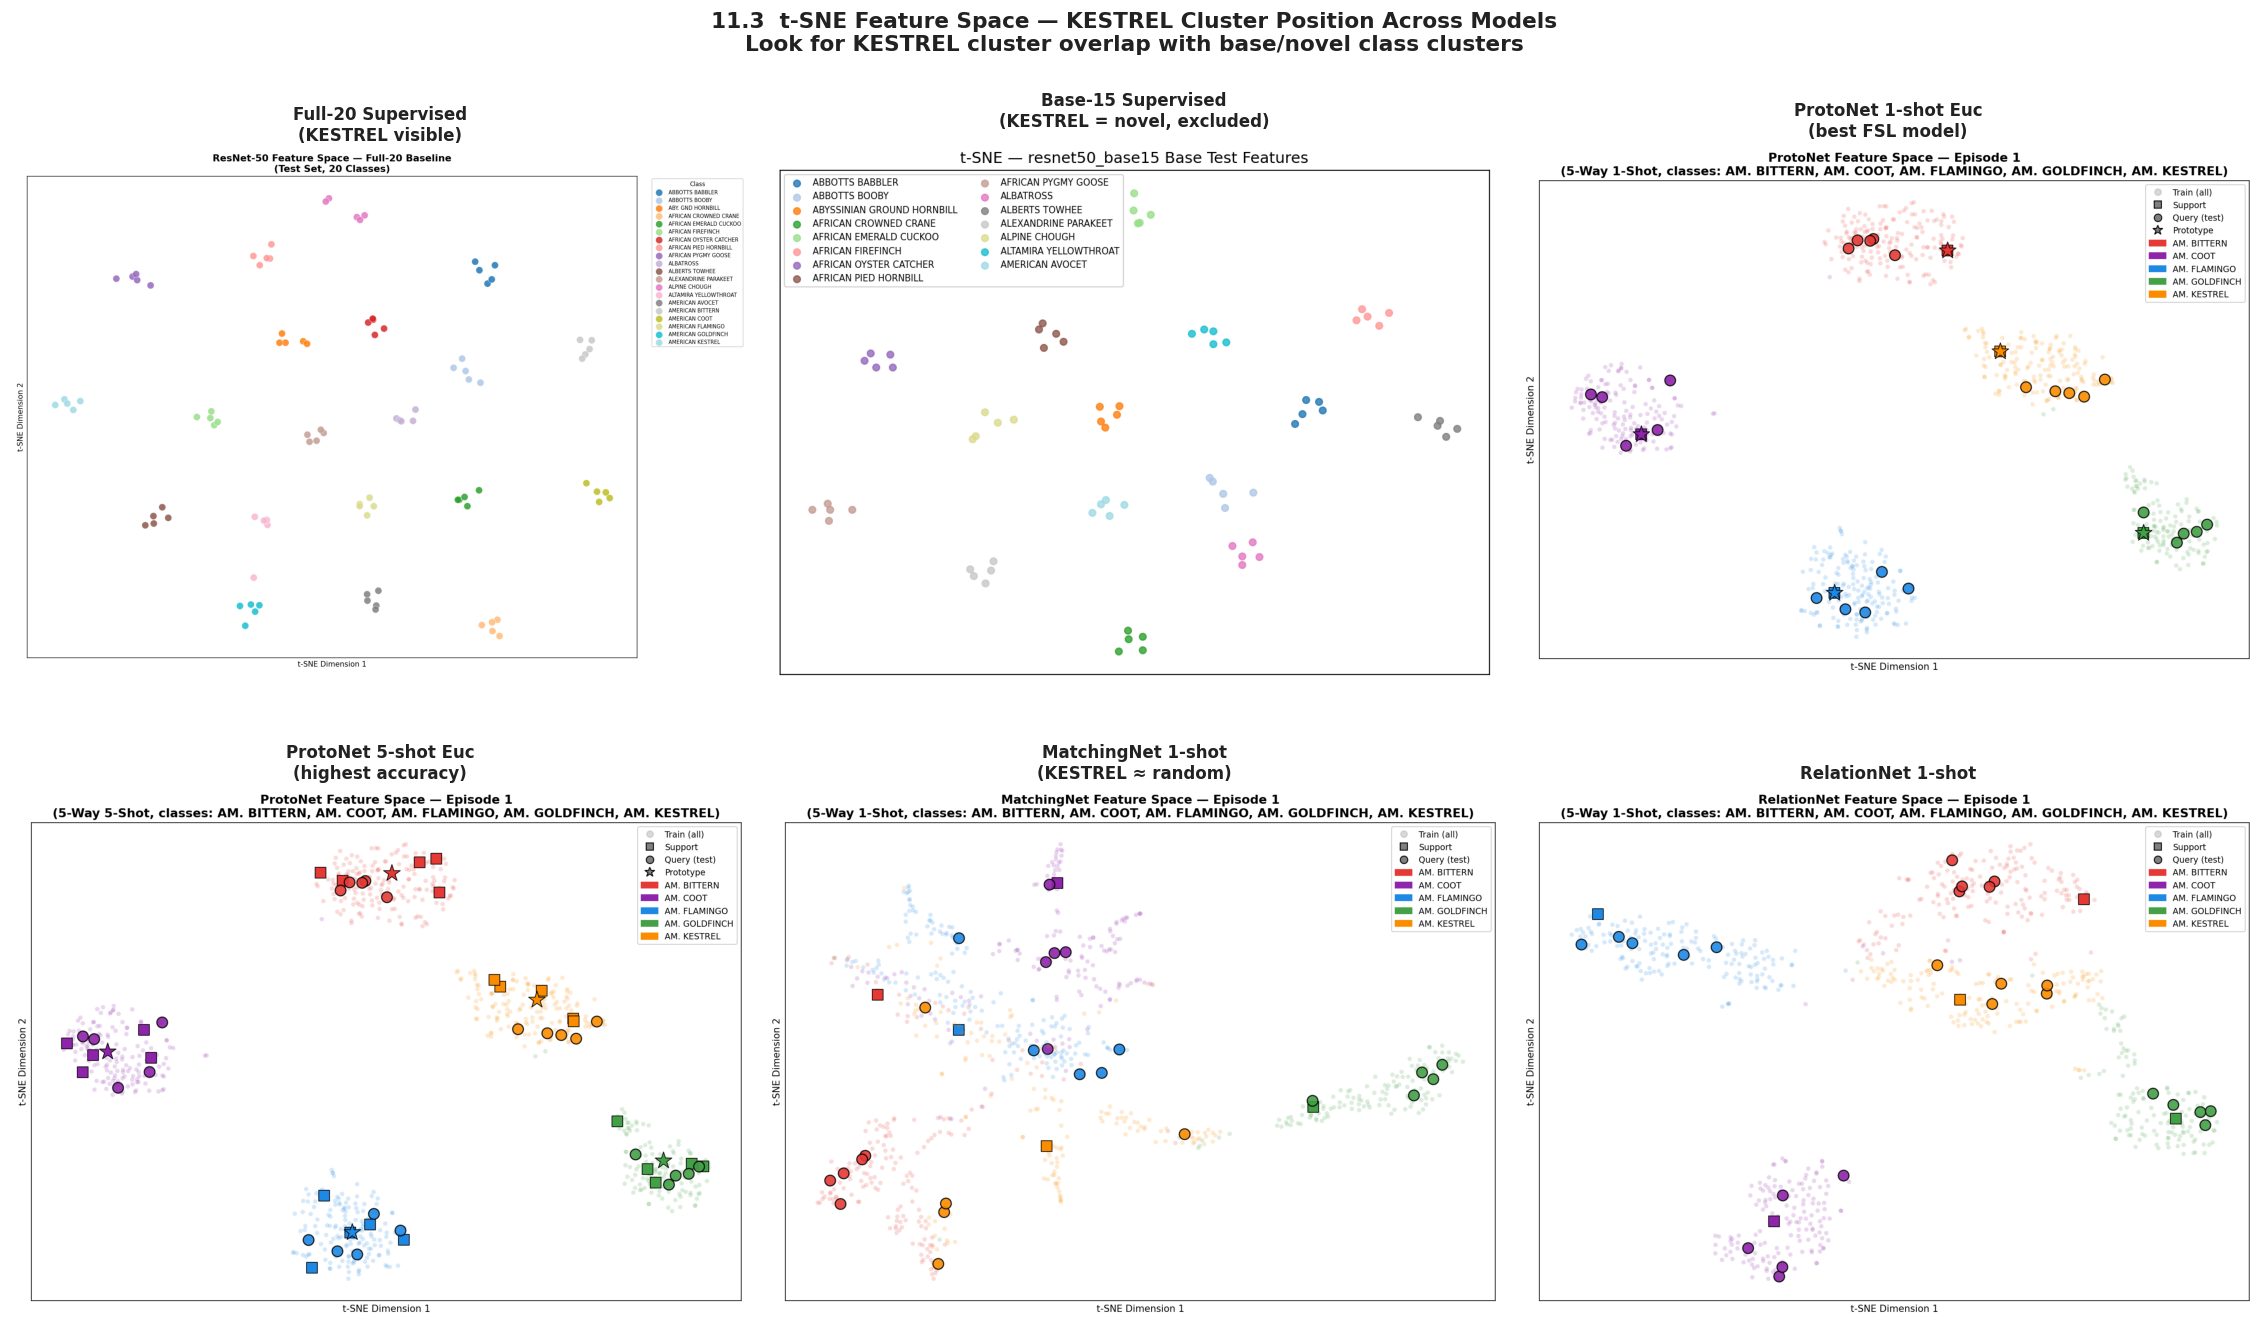

In [263]:
# ── 11.3  t-SNE Side-by-Side: KESTREL cluster position across models ──────────
# Show the existing t-SNE plots side-by-side.
# KESTREL appears as a novel class — if its cluster overlaps base classes, that
# explains the classification difficulty.

tsne_paths = [
    (f'{RES}/baseline/resnet50/full20/tsne_features.png',         'Full-20 Supervised\n(KESTREL visible)'),
    (f'{RES}/baseline/resnet50/base15/base_test/tsne_features.png','Base-15 Supervised\n(KESTREL = novel, excluded)'),
    (f'{RES}/proto_net/base15_novel5/1shot_euclidean/tsne_features.png',         'ProtoNet 1-shot Euc\n(best FSL model)'),
    (f'{RES}/proto_net/base15_novel5/5shot_euclidean/tsne_features.png',         'ProtoNet 5-shot Euc\n(highest accuracy)'),
    (f'{RES}/matching_net/base15_novel5/1shot/tsne_features.png',                'MatchingNet 1-shot\n(KESTREL ≈ random)'),
    (f'{RES}/relation_net/base15_novel5/1shot/tsne_features.png',                'RelationNet 1-shot'),
]

fig, axes = plt.subplots(2, 3, figsize=(19, 12))
fig.patch.set_facecolor('white')
axes = axes.flatten()

for ax, (path, title) in zip(axes, tsne_paths):
    ax.set_facecolor('white')
    show_img(path, ax, title)
    ax.set_title(title, fontsize=10, color='#222222', fontweight='bold')

fig.suptitle('11.3  t-SNE Feature Space — KESTREL Cluster Position Across Models\n'
             'Look for KESTREL cluster overlap with base/novel class clusters',
             color='#222222', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/analysis_tsne_kestrel_comparison.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

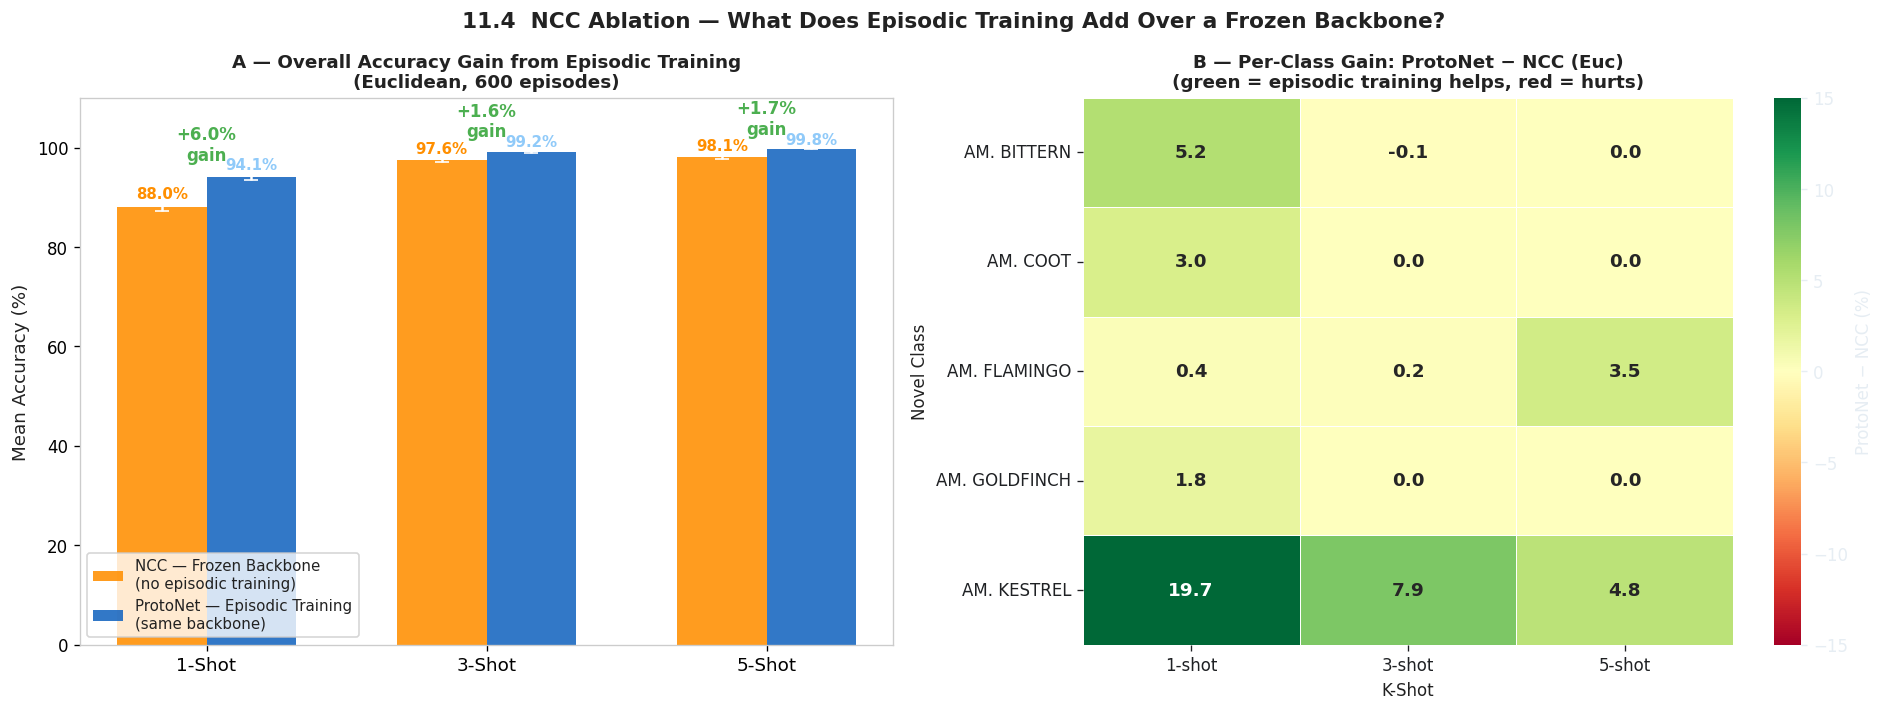

Episodic training gain summary (ProtoNet Euc − NCC Euc):
  1-shot: +6.01%  
  3-shot: +1.60%  ← diminishing return
  5-shot: +1.66%  ← diminishing return


In [268]:
# ── 11.4  NCC Ablation — What Does Episodic Training Actually Add? ─────────────
# Clean 2-panel ablation: (A) accuracy gain per shot, (B) per-class delta heatmap

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

SHOTS = [1, 3, 5]

# Panel A — gain bars per shot
ncc_accs   = [R[f'ncc_{s}shot_euc_json']['mean_accuracy_pct']   for s in SHOTS]
proto_accs = [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] for s in SHOTS]
gains      = [p - n for p, n in zip(proto_accs, ncc_accs)]
ncc_cis    = [R[f'ncc_{s}shot_euc_json']['ci95_pct']   for s in SHOTS]
proto_cis  = [R[f'proto_{s}shot_euc_json']['ci95_pct'] for s in SHOTS]

x = np.arange(len(SHOTS)); w = 0.32
axes[0].bar(x - w/2, ncc_accs,   w, label='NCC — Frozen Backbone\n(no episodic training)',
            color=C['ncc'],   alpha=0.88)
axes[0].bar(x + w/2, proto_accs, w, label='ProtoNet — Episodic Training\n(same backbone)',
            color=C['proto'], alpha=0.88)
axes[0].errorbar(x - w/2, ncc_accs,   yerr=ncc_cis,   fmt='none', color='white', capsize=4)
axes[0].errorbar(x + w/2, proto_accs, yerr=proto_cis, fmt='none', color='white', capsize=4)

for i, (n, p, g, nc, pc) in enumerate(zip(ncc_accs, proto_accs, gains, ncc_cis, proto_cis)):
    axes[0].text(i - w/2, n + nc + 0.8, f'{n:.1f}%', ha='center', fontsize=9,
                 color=C['ncc'], fontweight='bold')
    axes[0].text(i + w/2, p + pc + 0.8, f'{p:.1f}%', ha='center', fontsize=9,
                 color='#90CAF9', fontweight='bold')
    col = '#4CAF50' if g > 0 else '#F44336'
    axes[0].annotate(f'+{g:.1f}%\ngain', xy=(i, max(n,p) + max(nc,pc) + 2.5),
                     ha='center', fontsize=10, color=col, fontweight='bold')

axes[0].set_xticks(x); axes[0].set_xticklabels(['1-Shot','3-Shot','5-Shot'], color='#222222', fontsize=11)
axes[0].set_ylabel('Mean Accuracy (%)', color='#222222', fontsize=11)
axes[0].set_ylim(0, 110); axes[0].tick_params(colors="#000000")
axes[0].legend(fontsize=9, facecolor='white', edgecolor='#cccccc', labelcolor='#222222')
axes[0].set_title('A — Overall Accuracy Gain from Episodic Training\n(Euclidean, 600 episodes)',
                  color='#222222', fontsize=11, fontweight='bold')

# Panel B — per-class delta heatmap (ProtoNet Euc − NCC Euc)
delta_data = {}
for s in SHOTS:
    r_proto = R[f'proto_{s}shot_euc_json']
    r_ncc   = R[f'ncc_{s}shot_euc_json']
    delta_data[f'{s}-shot'] = [
        r_proto['per_class_accuracy_pct'][c] - r_ncc['per_class_accuracy_pct'][c]
        for c in NOVEL_CLASSES
    ]
df_delta = pd.DataFrame(delta_data, index=SHORT_NOVEL)

sns.heatmap(df_delta, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            vmin=-15, vmax=15, linewidths=0.5, ax=axes[1],
            cbar_kws={'label': 'ProtoNet − NCC (%)'},
            annot_kws={'size': 11, 'weight': 'bold'})
axes[1].set_title('B — Per-Class Gain: ProtoNet − NCC (Euc)\n(green = episodic training helps, red = hurts)',
                  color='#222222', fontsize=11, fontweight='bold')
axes[1].set_xlabel('K-Shot', color='#222222', fontsize=10)
axes[1].set_ylabel('Novel Class', color='#222222', fontsize=10)
axes[1].tick_params(colors="#1F2124")
axes[1].figure.axes[-1].tick_params(colors='#E6EDF3')
axes[1].figure.axes[-1].yaxis.label.set_color('#E6EDF3')

fig.suptitle('11.4  NCC Ablation — What Does Episodic Training Add Over a Frozen Backbone?',
             color='#222222', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/analysis_ncc_ablation.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

print("Episodic training gain summary (ProtoNet Euc − NCC Euc):")
for s, g in zip(SHOTS, gains):
    print(f"  {s}-shot: +{g:.2f}%  {'← diminishing return' if g < 3 else ''}")

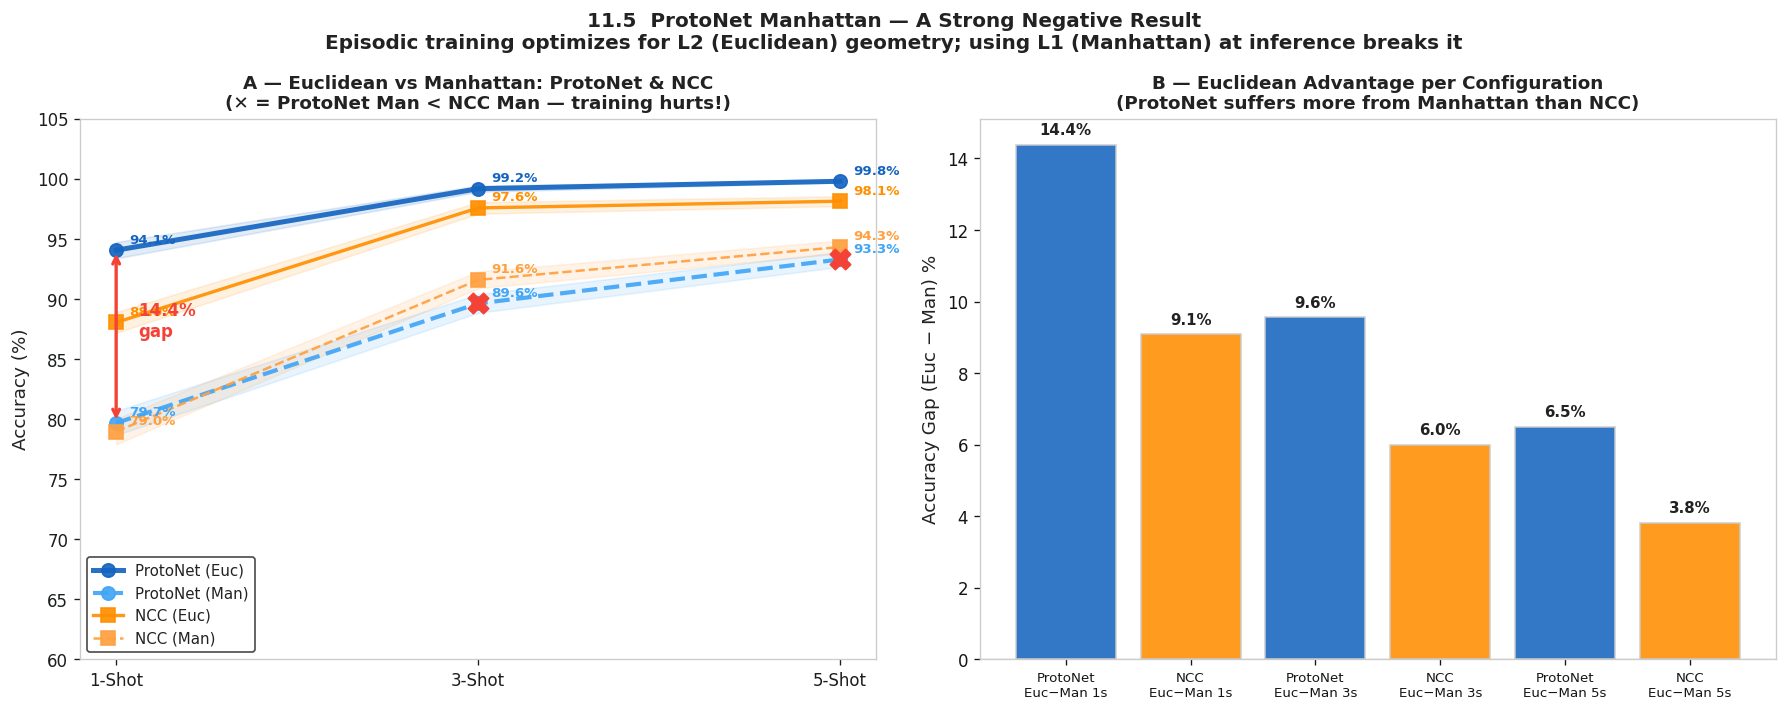

Key finding: ProtoNet Manhattan at 1-shot = 79.6733 %
NCC Manhattan at 1-shot          = 78.96 %
→ ProtoNet episodic training HURTS when using Manhattan distance


In [270]:
# ── 11.5  ProtoNet Manhattan as a Negative Result ─────────────────────────────
# The 15% gap at 1-shot between Euclidean and Manhattan is a strong negative
# result: using the wrong distance metric on an episodically-trained embedding
# is WORSE than not training at all (NCC Manhattan beats ProtoNet Manhattan).

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

SHOTS = [1, 3, 5]

# Panel A — Euc vs Man for both ProtoNet and NCC
configs = [
    ('ProtoNet (Euc)', [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] for s in SHOTS],
                       [R[f'proto_{s}shot_euc_json']['ci95_pct'] for s in SHOTS], C['proto'],    'o-',  3),
    ('ProtoNet (Man)', [R[f'proto_{s}shot_man_json']['mean_accuracy_pct'] for s in SHOTS],
                       [R[f'proto_{s}shot_man_json']['ci95_pct'] for s in SHOTS], C['proto_man'], 'o--', 2.5),
    ('NCC (Euc)',      [R[f'ncc_{s}shot_euc_json']['mean_accuracy_pct']   for s in SHOTS],
                       [R[f'ncc_{s}shot_euc_json']['ci95_pct'] for s in SHOTS],   C['ncc'],       's-',  2),
    ('NCC (Man)',      [R[f'ncc_{s}shot_man_json']['mean_accuracy_pct']   for s in SHOTS],
                       [R[f'ncc_{s}shot_man_json']['ci95_pct'] for s in SHOTS],   '#FFA040',      's--', 1.5),
]
for label, accs_l, cis_l, color, marker, lw in configs:
    axes[0].plot(SHOTS, accs_l, marker, color=color, lw=lw, markersize=8, label=label, alpha=0.92)
    axes[0].fill_between(SHOTS,
                         [a - c for a, c in zip(accs_l, cis_l)],
                         [a + c for a, c in zip(accs_l, cis_l)],
                         color=color, alpha=0.12)
    for s, a in zip(SHOTS, accs_l):
        axes[0].text(s + 0.07, a + 0.6, f'{a:.1f}%', fontsize=8, color=color, fontweight='bold')

# Annotate the 1-shot gap
gap_1shot = R['proto_1shot_euc_json']['mean_accuracy_pct'] - R['proto_1shot_man_json']['mean_accuracy_pct']
axes[0].annotate('', xy=(1, R['proto_1shot_man_json']['mean_accuracy_pct']),
                 xytext=(1, R['proto_1shot_euc_json']['mean_accuracy_pct']),
                 arrowprops=dict(arrowstyle='<->', color='#F44336', lw=2))
axes[0].text(1.12, (R['proto_1shot_euc_json']['mean_accuracy_pct'] +
                    R['proto_1shot_man_json']['mean_accuracy_pct']) / 2,
             f'{gap_1shot:.1f}%\ngap', color='#F44336', fontsize=10, fontweight='bold')

# Shade region where ProtoNet Man < NCC Man
for s in SHOTS:
    pm = R[f'proto_{s}shot_man_json']['mean_accuracy_pct']
    nm = R[f'ncc_{s}shot_man_json']['mean_accuracy_pct']
    if pm < nm:
        axes[0].scatter([s], [pm], marker='X', s=150, color='#F44336', zorder=5)

axes[0].axhline(20, color='#BDBDBD', linestyle=':', lw=1, alpha=0.4)
axes[0].set_xticks(SHOTS); axes[0].set_xticklabels(['1-Shot','3-Shot','5-Shot'], color='#222222')
axes[0].set_ylabel('Accuracy (%)', color='#222222', fontsize=11)
axes[0].set_ylim(60, 105); axes[0].tick_params(colors="#1B1D1E")
axes[0].legend(fontsize=9, facecolor='white', edgecolor="#1e1a1a", labelcolor='#222222')
axes[0].set_title('A — Euclidean vs Manhattan: ProtoNet & NCC\n(✕ = ProtoNet Man < NCC Man — training hurts!)',
                  color='#222222', fontsize=11, fontweight='bold')

# Panel B — gap table as bar chart
gap_labels, gap_vals, gap_cols = [], [], []
for s in SHOTS:
    gap_euc = (R[f'proto_{s}shot_euc_json']['mean_accuracy_pct'] -
               R[f'proto_{s}shot_man_json']['mean_accuracy_pct'])
    gap_labels.append(f'ProtoNet\nEuc−Man {s}s')
    gap_vals.append(gap_euc)
    gap_cols.append(C['proto'])

    gap_ncc = (R[f'ncc_{s}shot_euc_json']['mean_accuracy_pct'] -
               R[f'ncc_{s}shot_man_json']['mean_accuracy_pct'])
    gap_labels.append(f'NCC\nEuc−Man {s}s')
    gap_vals.append(gap_ncc)
    gap_cols.append(C['ncc'])

bars = axes[1].bar(range(len(gap_labels)), gap_vals, color=gap_cols, alpha=0.88, edgecolor='#cccccc')
for bar, v in zip(bars, gap_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, v + 0.2, f'{v:.1f}%',
                 ha='center', va='bottom', fontsize=9, color='#222222', fontweight='bold')
axes[1].axhline(0, color='#BDBDBD', linestyle='-', lw=0.8)
axes[1].set_xticks(range(len(gap_labels)))
axes[1].set_xticklabels(gap_labels, fontsize=8, color='#222222')
axes[1].set_ylabel('Accuracy Gap (Euc − Man) %', color='#222222', fontsize=11)
axes[1].tick_params(colors="#141516")
axes[1].set_title('B — Euclidean Advantage per Configuration\n(ProtoNet suffers more from Manhattan than NCC)',
                  color='#222222', fontsize=11, fontweight='bold')

fig.suptitle('11.5  ProtoNet Manhattan — A Strong Negative Result\n'
             'Episodic training optimizes for L2 (Euclidean) geometry; using L1 (Manhattan) at inference breaks it',
             color='#222222', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{RES}/analysis/analysis_manhattan_negative.png', dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

print("Key finding: ProtoNet Manhattan at 1-shot =", R['proto_1shot_man_json']['mean_accuracy_pct'], "%")
print("NCC Manhattan at 1-shot          =", R['ncc_1shot_man_json']['mean_accuracy_pct'], "%")
print("→ ProtoNet episodic training HURTS when using Manhattan distance")

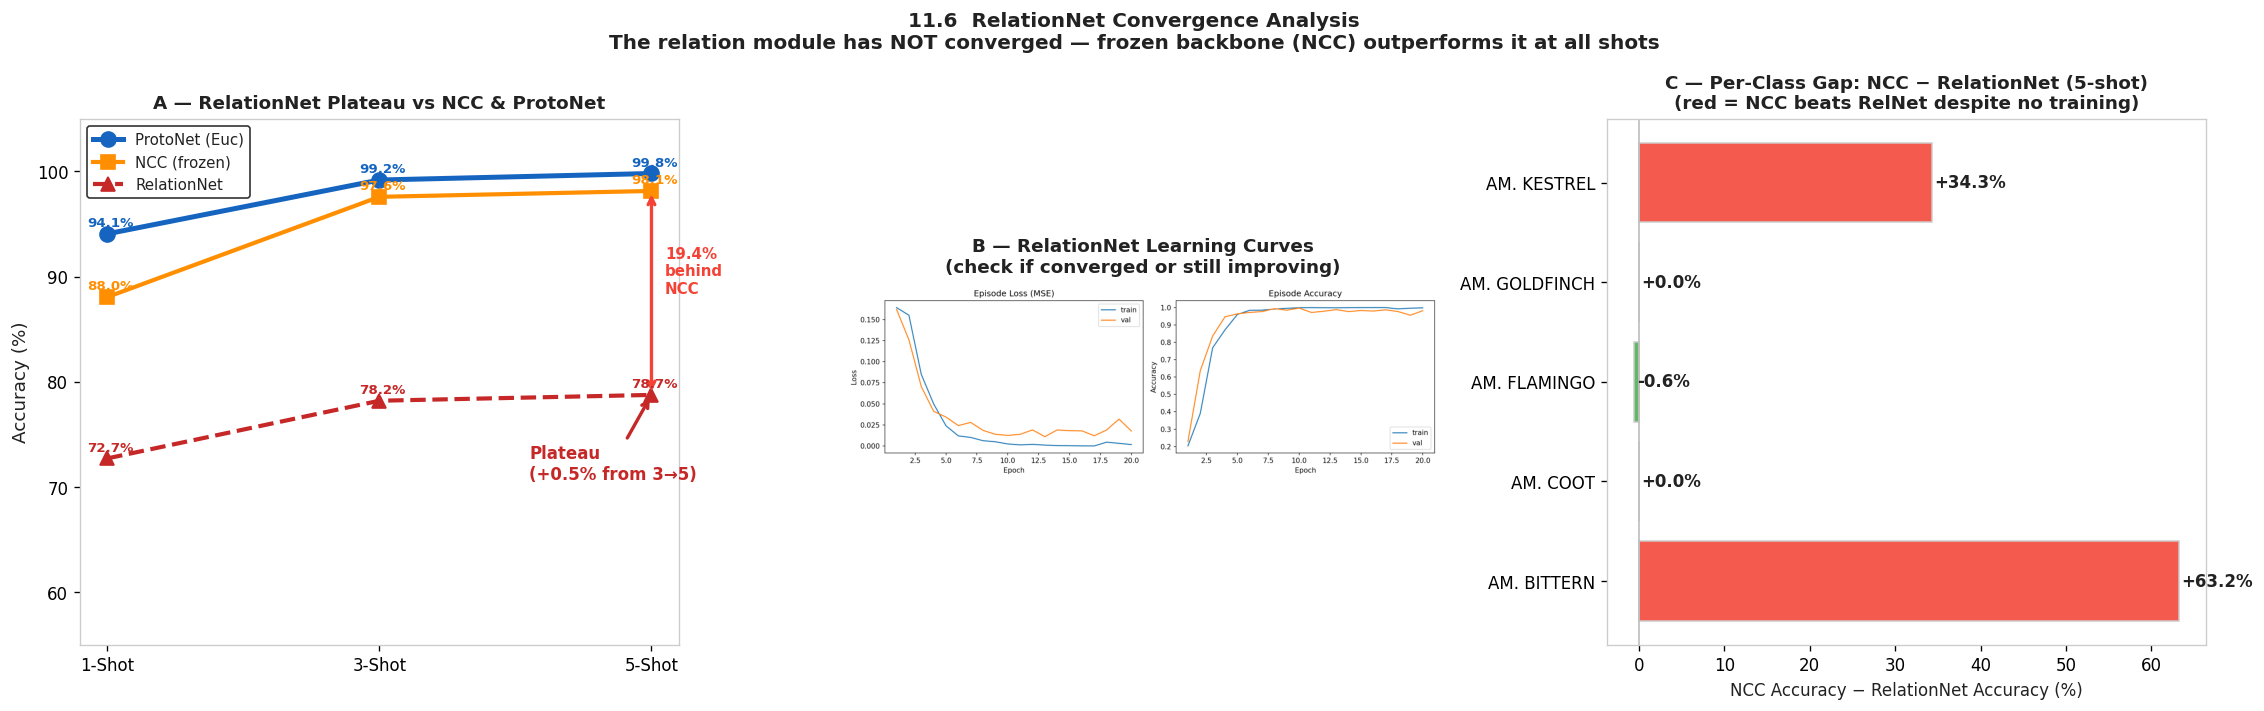

RelationNet vs NCC (Euc) at 5-shot — per class:
  AM. BITTERN         : NCC=100.0%  RelNet=36.8%  Δ=+63.2%  [NCC wins]
  AM. COOT            : NCC=100.0%  RelNet=100.0%  Δ=+0.0%  [RelNet wins]
  AM. FLAMINGO        : NCC=96.5%  RelNet=97.1%  Δ=-0.6%  [RelNet wins]
  AM. GOLDFINCH       : NCC=100.0%  RelNet=100.0%  Δ=+0.0%  [RelNet wins]
  AM. KESTREL         : NCC=94.2%  RelNet=59.9%  Δ=+34.3%  [NCC wins]


In [276]:
_rel_available = all(R.get(f'rel_{s}shot_json') is not None for s in [1,3,5])
if not _rel_available:
    print("RelationNet b15/n5 results not yet available — run evaluate.py first.")
else:
    # ── 11.6  RelationNet Convergence Analysis ────────────────────────────────────
    # RelationNet plateaus at 78.7% while NCC (no training) reaches 98.6% at 5-shot.
    # This cell shows: (A) the plateau, (B) learning curves, (C) per-class gap.

    fig, axes = plt.subplots(1, 3, figsize=(19, 6))
    fig.patch.set_facecolor('white')
    for ax in axes:
        ax.set_facecolor('white')
        for spine in ax.spines.values(): spine.set_edgecolor('#cccccc')

    SHOTS = [1, 3, 5]

    # Panel A — RelationNet vs NCC plateau comparison
    rel_accs  = [R[f'rel_{s}shot_json']['mean_accuracy_pct']
                  if R[f'rel_{s}shot_json'] is not None else float('nan')
                  for s in SHOTS]
    ncc_accs  = [R[f'ncc_{s}shot_euc_json']['mean_accuracy_pct']     for s in SHOTS]
    prot_accs = [R[f'proto_{s}shot_euc_json']['mean_accuracy_pct']   for s in SHOTS]

    axes[0].plot(SHOTS, prot_accs, 'o-',  color=C['proto'], lw=3,   markersize=9, label='ProtoNet (Euc)')
    axes[0].plot(SHOTS, ncc_accs,  's-',  color=C['ncc'],   lw=2.5, markersize=8, label='NCC (frozen)')
    axes[0].plot(SHOTS, rel_accs,  '^--', color=C['rel'],   lw=2.5, markersize=8, label='RelationNet')

    # Annotate the plateau
    axes[0].annotate('Plateau\n(+0.5% from 3→5)',
                     xy=(5, rel_accs[2]), xytext=(4.1, rel_accs[2] - 8),
                     arrowprops=dict(arrowstyle='->', color=C['rel'], lw=2),
                     color=C['rel'], fontsize=10, fontweight='bold')

    # Annotate the gap vs NCC at 5-shot
    gap_5 = ncc_accs[2] - rel_accs[2]
    axes[0].annotate('', xy=(5, rel_accs[2]),
                     xytext=(5, ncc_accs[2]),
                     arrowprops=dict(arrowstyle='<->', color='#F44336', lw=2))
    axes[0].text(5.1, (ncc_accs[2]+rel_accs[2])/2, f'{gap_5:.1f}%\nbehind\nNCC',
                 color='#F44336', fontsize=9, fontweight='bold')

    for accs_l, color in [(prot_accs, C['proto']), (ncc_accs, C['ncc']), (rel_accs, C['rel'])]:
        for s, a in zip(SHOTS, accs_l):
            axes[0].text(s-0.15, a+0.7, f'{a:.1f}%', fontsize=8, color=color, fontweight='bold')

    axes[0].axhline(20, color='#BDBDBD', linestyle=':', lw=1, alpha=0.4)
    axes[0].set_xticks(SHOTS); axes[0].set_xticklabels(['1-Shot','3-Shot','5-Shot'], color='#222222')
    axes[0].set_ylabel('Accuracy (%)', color='#222222', fontsize=11)
    axes[0].set_ylim(55, 105); axes[0].tick_params(colors="#000000")
    axes[0].legend(fontsize=9, facecolor='white', edgecolor="#000000", labelcolor='#222222')
    axes[0].set_title('A — RelationNet Plateau vs NCC & ProtoNet', color='#222222', fontsize=11, fontweight='bold')

    # Panel B — RelationNet learning curves (train vs val)
    lc_path = f'{RES}/relation_net/base15_novel5/1shot/learning_curves.png'
    show_img(lc_path, axes[1], 'B — RelationNet Training Curves (1-shot)')
    axes[1].set_title('B — RelationNet Learning Curves\n(check if converged or still improving)',
                      color='#222222', fontsize=11, fontweight='bold')

    # Panel C — per-class gap: NCC vs RelationNet at 5-shot
    ncc5_pc = R['ncc_5shot_euc_json']['per_class_accuracy_pct'] if R.get('ncc_5shot_euc_json') else {}
    rel5_pc = R['rel_5shot_json']['per_class_accuracy_pct'] if R.get('rel_5shot_json') else {}
    gaps_pc = {c: ncc5_pc[c] - rel5_pc[c] for c in NOVEL_CLASSES}

    bar_colors = ['#F44336' if v > 0 else '#4CAF50' for v in gaps_pc.values()]
    bars = axes[2].barh(list(SHORT_NOVEL), list(gaps_pc.values()),
                        color=bar_colors, alpha=0.88, edgecolor='#cccccc')
    for bar, v in zip(bars, gaps_pc.values()):
        axes[2].text(v + 0.3, bar.get_y() + bar.get_height()/2,
                     f'{v:+.1f}%', va='center', fontsize=10, color='#222222', fontweight='bold')
    axes[2].axvline(0, color='#BDBDBD', lw=1)
    axes[2].set_xlabel('NCC Accuracy − RelationNet Accuracy (%)', color='#222222', fontsize=10)
    axes[2].tick_params(colors="#000000")
    axes[2].set_title('C — Per-Class Gap: NCC − RelationNet (5-shot)\n(red = NCC beats RelNet despite no training)',
                      color='#222222', fontsize=11, fontweight='bold')

    fig.suptitle('11.6  RelationNet Convergence Analysis\n'
                 'The relation module has NOT converged — frozen backbone (NCC) outperforms it at all shots',
                 color='#222222', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{RES}/analysis/analysis_relationnet_convergence.png', dpi=150, bbox_inches='tight',
                facecolor='white')
    plt.show()

    print("RelationNet vs NCC (Euc) at 5-shot — per class:")
    for cls, short in zip(NOVEL_CLASSES, SHORT_NOVEL):
        diff = ncc5_pc[cls] - rel5_pc[cls]
        sign = 'NCC wins' if diff > 0 else 'RelNet wins'
        print(f"  {short:<20}: NCC={ncc5_pc[cls]:.1f}%  RelNet={rel5_pc[cls]:.1f}%  Δ={diff:+.1f}%  [{sign}]")